In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Radiología.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 9 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=124.0, y1=114.7
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 297
Page 1, Q1, A: Yellow percentage: 0.0%


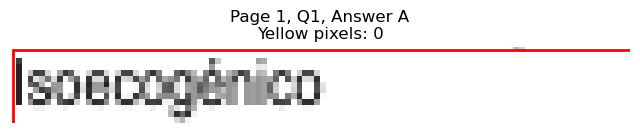

Page 1, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=133.5, y1=127.3
Page 1, Q1, B: Yellow pixels: 116
Page 1, Q1, B: Total non-white pixels: 457
Page 1, Q1, B: Yellow percentage: 25.4%


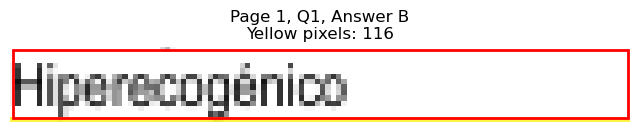

Page 1, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=130.9, y1=139.9
Page 1, Q1, C: Yellow pixels: 1191
Page 1, Q1, C: Total non-white pixels: 1469
Page 1, Q1, C: Yellow percentage: 81.1%


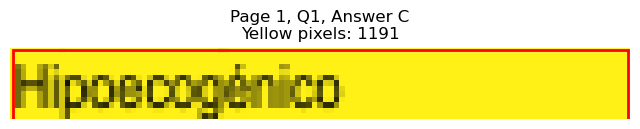

Page 1, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=382.3, y1=114.7
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 293
Page 1, Q1, D: Yellow percentage: 0.0%


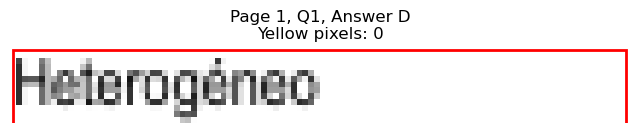

Page 1, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=381.8, y1=127.3
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 282
Page 1, Q1, E: Yellow percentage: 0.0%


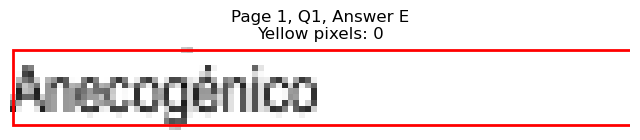


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=106.9, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 186
Page 1, Q2, A: Yellow percentage: 0.0%


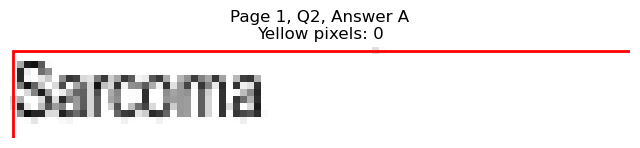

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=102.9, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 165
Page 1, Q2, B: Yellow percentage: 0.0%


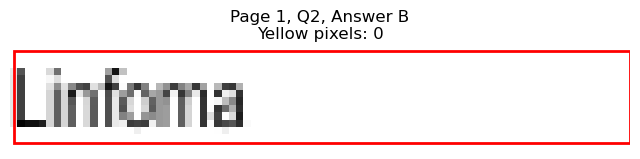

Page 1, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=109.9, y1=203.0
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 194
Page 1, Q2, C: Yellow percentage: 0.0%


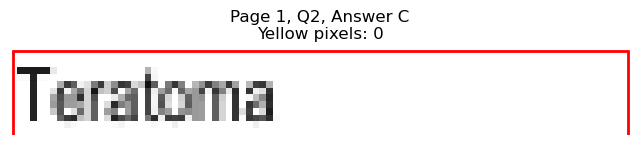

Page 1, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=359.7, y1=177.8
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 214
Page 1, Q2, D: Yellow percentage: 0.0%


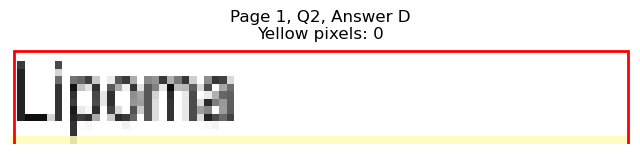

Page 1, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=361.1, y1=190.4
Page 1, Q2, E: Yellow pixels: 882
Page 1, Q2, E: Total non-white pixels: 1190
Page 1, Q2, E: Yellow percentage: 74.1%


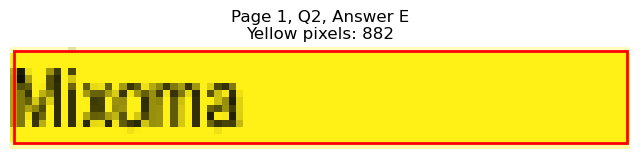


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=155.1, y1=266.1
Page 1, Q3, A: Yellow pixels: 138
Page 1, Q3, A: Total non-white pixels: 583
Page 1, Q3, A: Yellow percentage: 23.7%


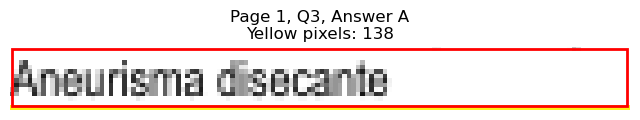

Page 1, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=202.1, y1=278.7
Page 1, Q3, B: Yellow pixels: 1891
Page 1, Q3, B: Total non-white pixels: 2405
Page 1, Q3, B: Yellow percentage: 78.6%


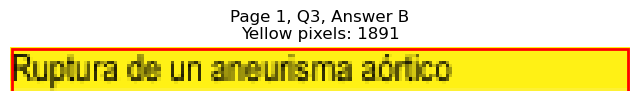

Page 1, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=144.0, y1=291.5
Page 1, Q3, C: Yellow pixels: 127
Page 1, Q3, C: Total non-white pixels: 482
Page 1, Q3, C: Yellow percentage: 26.3%


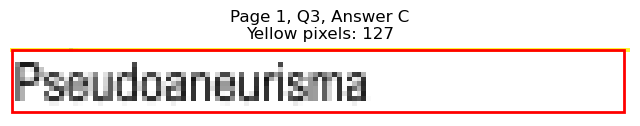

Page 1, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=422.3, y1=266.1
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 465
Page 1, Q3, D: Yellow percentage: 0.0%


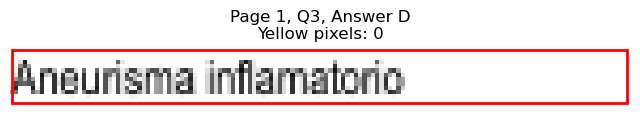

Page 1, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=431.3, y1=278.7
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 526
Page 1, Q3, E: Yellow percentage: 0.0%


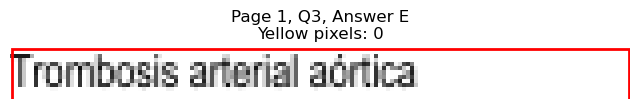


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=151.1, y1=329.3
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 412
Page 1, Q4, A: Yellow percentage: 0.0%


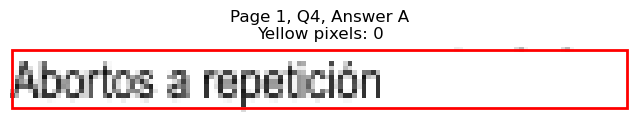

Page 1, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=163.1, y1=341.9
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 436
Page 1, Q4, B: Yellow percentage: 0.0%


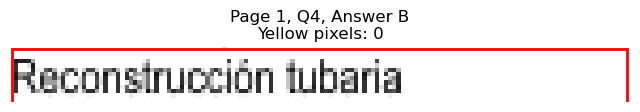

Page 1, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=134.5, y1=354.6
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 349
Page 1, Q4, C: Yellow percentage: 0.0%


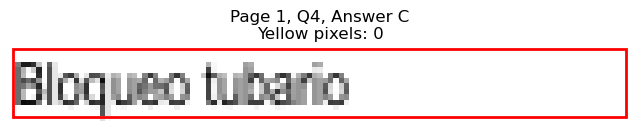

Page 1, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=405.8, y1=329.3
Page 1, Q4, D: Yellow pixels: 129
Page 1, Q4, D: Total non-white pixels: 553
Page 1, Q4, D: Yellow percentage: 23.3%


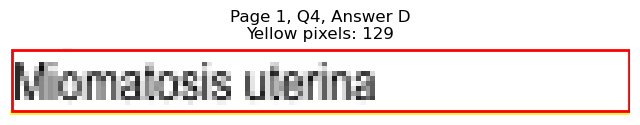

Page 1, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=420.8, y1=341.9
Page 1, Q4, E: Yellow pixels: 1486
Page 1, Q4, E: Total non-white pixels: 1872
Page 1, Q4, E: Yellow percentage: 79.4%


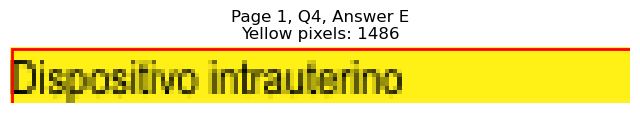


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=95.9, y1=417.6
Page 1, Q5, A: Yellow pixels: 914
Page 1, Q5, A: Total non-white pixels: 1092
Page 1, Q5, A: Yellow percentage: 83.7%


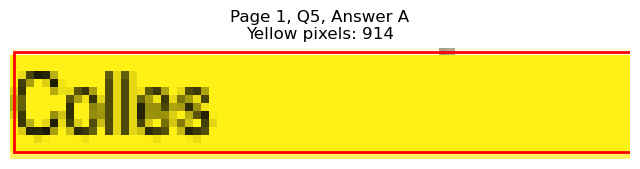

Page 1, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=93.9, y1=430.3
Page 1, Q5, B: Yellow pixels: 76
Page 1, Q5, B: Total non-white pixels: 203
Page 1, Q5, B: Yellow percentage: 37.4%


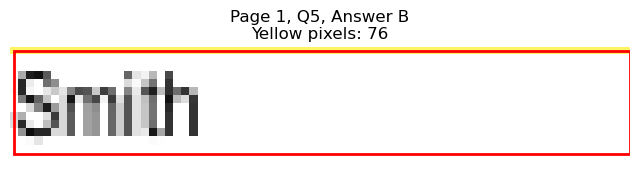

Page 1, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=106.5, y1=442.9
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 196
Page 1, Q5, C: Yellow percentage: 0.0%


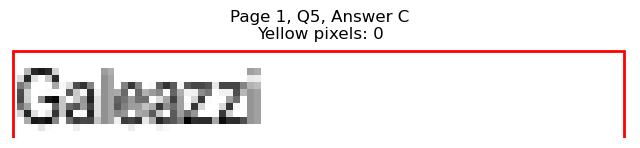

Page 1, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=368.2, y1=417.6
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 188
Page 1, Q5, D: Yellow percentage: 0.0%


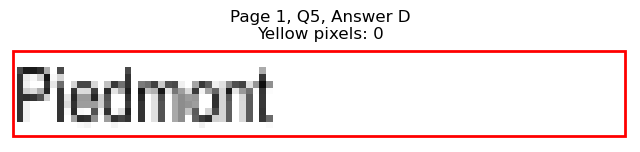

Page 1, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=410.8, y1=430.3
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 429
Page 1, Q5, E: Yellow percentage: 0.0%


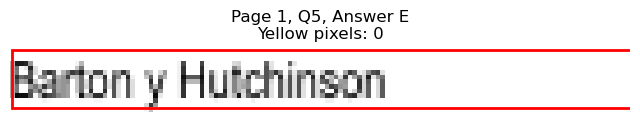


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=153.5, y1=493.4
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 437
Page 1, Q6, A: Yellow percentage: 0.0%


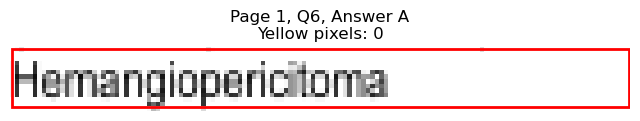

Page 1, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=176.2, y1=506.0
Page 1, Q6, B: Yellow pixels: 159
Page 1, Q6, B: Total non-white pixels: 911
Page 1, Q6, B: Yellow percentage: 17.5%


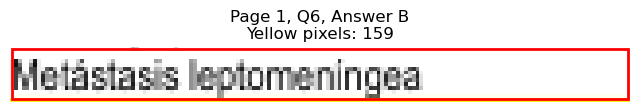

Page 1, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=144.5, y1=518.6
Page 1, Q6, C: Yellow pixels: 1349
Page 1, Q6, C: Total non-white pixels: 1778
Page 1, Q6, C: Yellow percentage: 75.9%


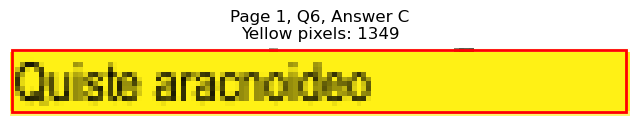

Page 1, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=390.8, y1=493.4
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 338
Page 1, Q6, D: Yellow percentage: 0.0%


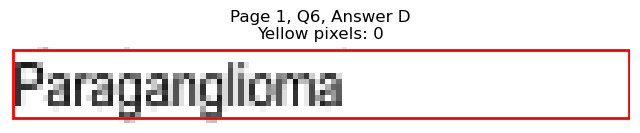

Page 1, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=368.2, y1=506.0
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 207
Page 1, Q6, E: Yellow percentage: 0.0%


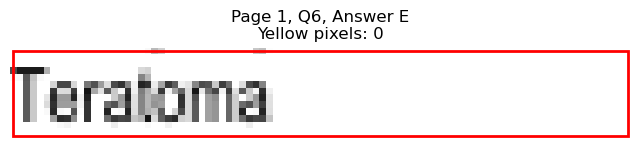


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=135.5, y1=569.2
Page 1, Q7, A: Yellow pixels: 1263
Page 1, Q7, A: Total non-white pixels: 1652
Page 1, Q7, A: Yellow percentage: 76.5%


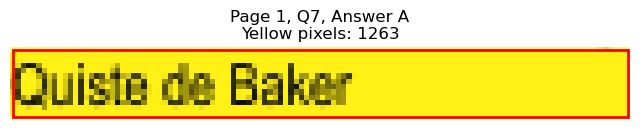

Page 1, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=100.3, y1=581.8
Page 1, Q7, B: Yellow pixels: 0
Page 1, Q7, B: Total non-white pixels: 258
Page 1, Q7, B: Yellow percentage: 0.0%


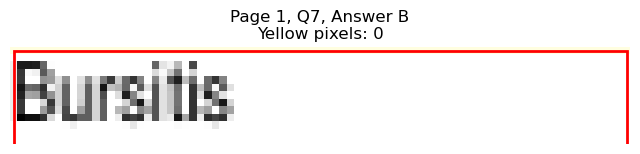

Page 1, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=141.0, y1=594.4
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 341
Page 1, Q7, C: Yellow percentage: 0.0%


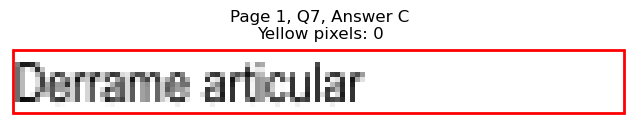

Page 1, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=378.7, y1=569.2
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 262
Page 1, Q7, D: Yellow percentage: 0.0%


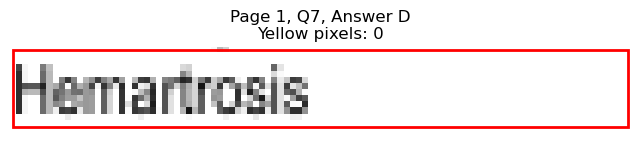

Page 1, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=393.8, y1=581.8
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 353
Page 1, Q7, E: Yellow percentage: 0.0%


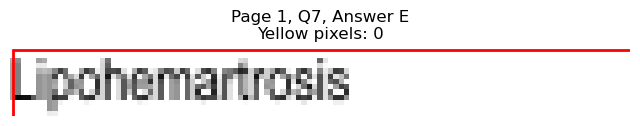


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=632.2, x1=106.9, y1=644.9
Page 1, Q8, A: Yellow pixels: 1016
Page 1, Q8, A: Total non-white pixels: 1157
Page 1, Q8, A: Yellow percentage: 87.8%


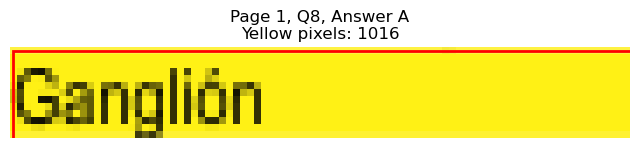

Page 1, Q8 - B: Detected box: x0=68.3, y0=644.9, x1=125.4, y1=657.5
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 275
Page 1, Q8, B: Yellow percentage: 0.0%


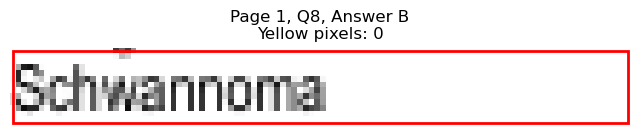

Page 1, Q8 - C: Detected box: x0=68.8, y0=657.5, x1=105.9, y1=670.1
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 186
Page 1, Q8, C: Yellow percentage: 0.0%


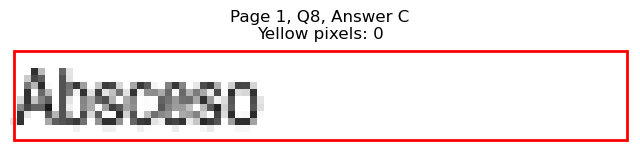

Page 1, Q8 - D: Detected box: x0=327.5, y0=632.2, x1=374.2, y1=644.9
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 232
Page 1, Q8, D: Yellow percentage: 0.0%


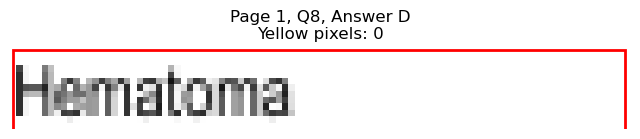

Page 1, Q8 - E: Detected box: x0=327.0, y0=644.9, x1=363.2, y1=657.5
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 198
Page 1, Q8, E: Yellow percentage: 0.0%


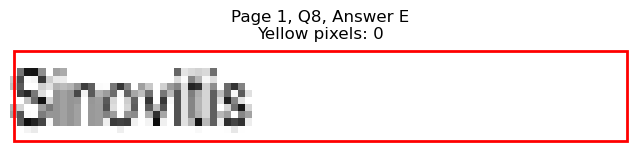


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=117.5, y1=720.6
Page 1, Q9, A: Yellow pixels: 1090
Page 1, Q9, A: Total non-white pixels: 1400
Page 1, Q9, A: Yellow percentage: 77.9%


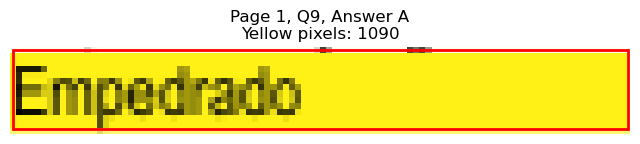

Page 1, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=114.5, y1=733.2
Page 1, Q9, B: Yellow pixels: 97
Page 1, Q9, B: Total non-white pixels: 311
Page 1, Q9, B: Yellow percentage: 31.2%


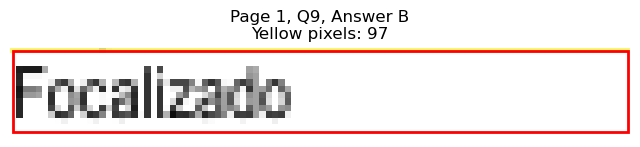

Page 1, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=120.5, y1=745.8
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 266
Page 1, Q9, C: Yellow percentage: 0.0%


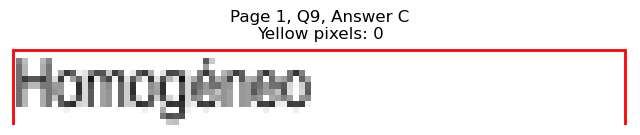

Page 1, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=396.8, y1=720.6
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 332
Page 1, Q9, D: Yellow percentage: 0.0%


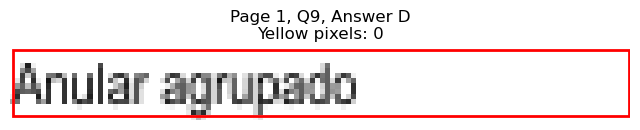

Page 1, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=381.8, y1=733.2
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 303
Page 1, Q9, E: Yellow percentage: 0.0%


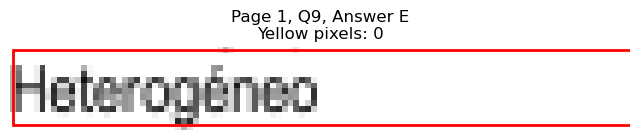


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)





Page 2: Found 9 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=150.5, y1=114.7
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 401
Page 2, Q1, A: Yellow percentage: 0.0%


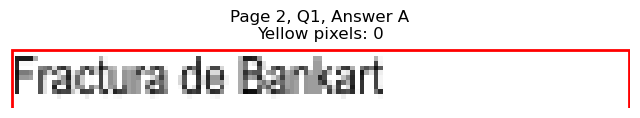

Page 2, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=183.1, y1=127.3
Page 2, Q1, B: Yellow pixels: 0
Page 2, Q1, B: Total non-white pixels: 552
Page 2, Q1, B: Yellow percentage: 0.0%


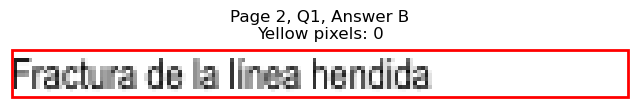

Page 2, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=141.0, y1=139.9
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 328
Page 2, Q1, C: Yellow percentage: 0.0%


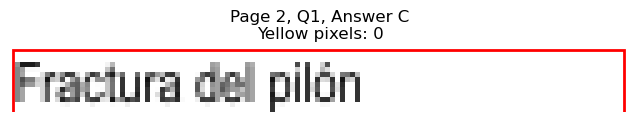

Page 2, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=418.9, y1=114.7
Page 2, Q1, D: Yellow pixels: 1515
Page 2, Q1, D: Total non-white pixels: 1846
Page 2, Q1, D: Yellow percentage: 82.1%


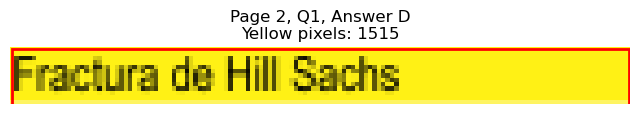

Page 2, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=404.8, y1=127.3
Page 2, Q1, E: Yellow pixels: 128
Page 2, Q1, E: Total non-white pixels: 503
Page 2, Q1, E: Yellow percentage: 25.4%


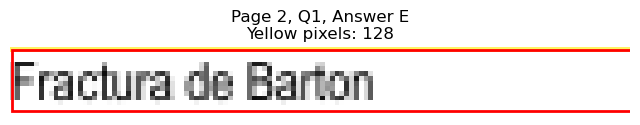


Page 2, Q1 - Selected Answer: D (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=98.4, y1=177.8
Page 2, Q2, A: Yellow pixels: 925
Page 2, Q2, A: Total non-white pixels: 1053
Page 2, Q2, A: Yellow percentage: 87.8%


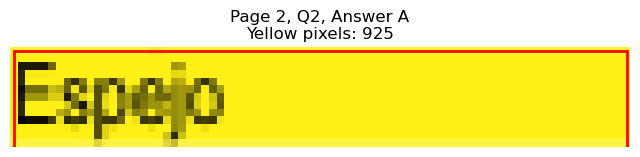

Page 2, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=175.1, y1=190.4
Page 2, Q2, B: Yellow pixels: 157
Page 2, Q2, B: Total non-white pixels: 722
Page 2, Q2, B: Yellow percentage: 21.7%


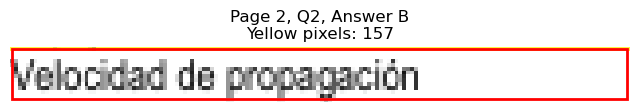

Page 2, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=133.9, y1=203.0
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 319
Page 2, Q2, C: Yellow percentage: 0.0%


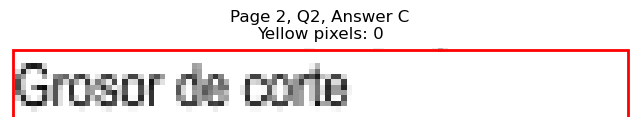

Page 2, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=384.2, y1=177.8
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 280
Page 2, Q2, D: Yellow percentage: 0.0%


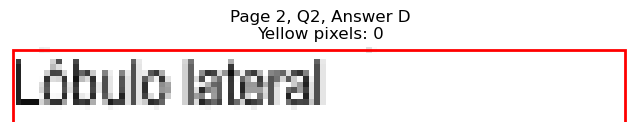

Page 2, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=388.3, y1=190.4
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 323
Page 2, Q2, E: Yellow percentage: 0.0%


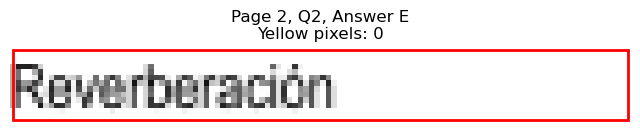


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=163.6, y1=253.5
Page 2, Q3, A: Yellow pixels: 1529
Page 2, Q3, A: Total non-white pixels: 2044
Page 2, Q3, A: Yellow percentage: 74.8%


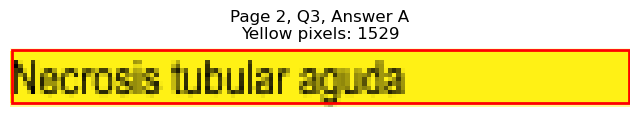

Page 2, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=118.5, y1=266.1
Page 2, Q3, B: Yellow pixels: 100
Page 2, Q3, B: Total non-white pixels: 370
Page 2, Q3, B: Yellow percentage: 27.0%


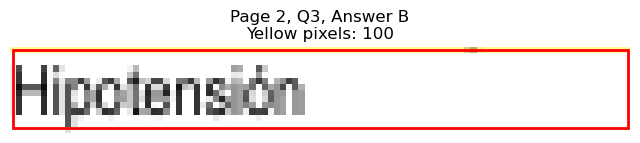

Page 2, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=180.1, y1=278.7
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 517
Page 2, Q3, C: Yellow percentage: 0.0%


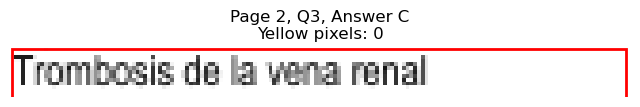

Page 2, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=420.3, y1=253.5
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 469
Page 2, Q3, D: Yellow percentage: 0.0%


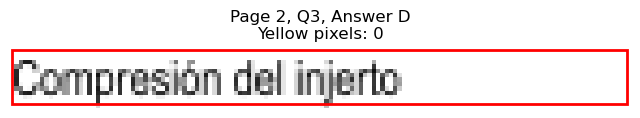

Page 2, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=405.8, y1=266.1
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 411
Page 2, Q3, E: Yellow percentage: 0.0%


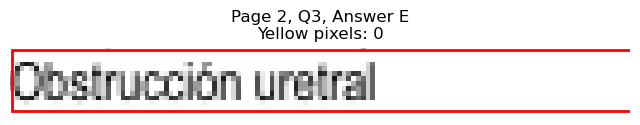


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=106.5, y1=341.9
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 194
Page 2, Q4, A: Yellow percentage: 0.0%


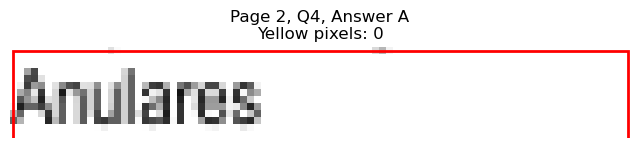

Page 2, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=127.0, y1=354.6
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 319
Page 2, Q4, B: Yellow percentage: 0.0%


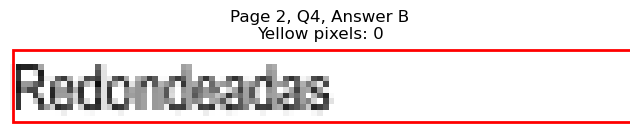

Page 2, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=126.0, y1=367.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 264
Page 2, Q4, C: Yellow percentage: 0.0%


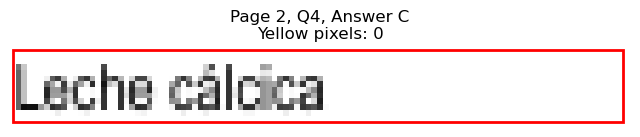

Page 2, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=372.2, y1=341.9
Page 2, Q4, D: Yellow pixels: 1065
Page 2, Q4, D: Total non-white pixels: 1248
Page 2, Q4, D: Yellow percentage: 85.3%


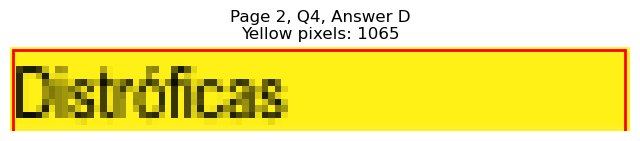

Page 2, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=374.2, y1=354.6
Page 2, Q4, E: Yellow pixels: 98
Page 2, Q4, E: Total non-white pixels: 337
Page 2, Q4, E: Yellow percentage: 29.1%


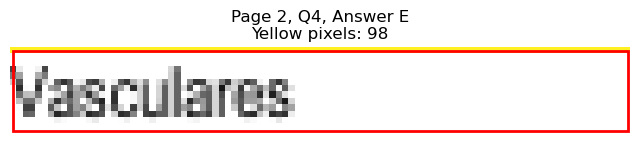


Page 2, Q4 - Selected Answer: D (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=189.1, y1=405.0
Page 2, Q5, A: Yellow pixels: 0
Page 2, Q5, A: Total non-white pixels: 594
Page 2, Q5, A: Yellow percentage: 0.0%


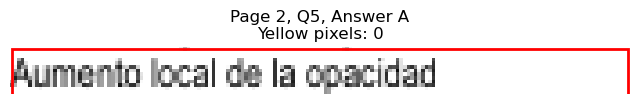

Page 2, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=186.6, y1=417.6
Page 2, Q5, B: Yellow pixels: 0
Page 2, Q5, B: Total non-white pixels: 610
Page 2, Q5, B: Yellow percentage: 0.0%


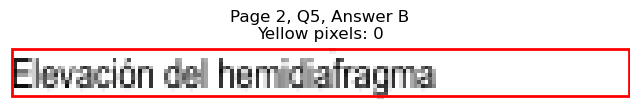

Page 2, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=202.2, y1=430.3
Page 2, Q5, C: Yellow pixels: 0
Page 2, Q5, C: Total non-white pixels: 653
Page 2, Q5, C: Yellow percentage: 0.0%


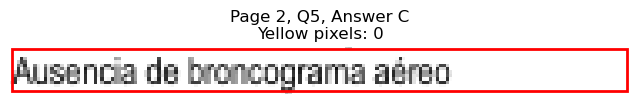

Page 2, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=445.9, y1=405.0
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 772
Page 2, Q5, D: Yellow percentage: 0.0%


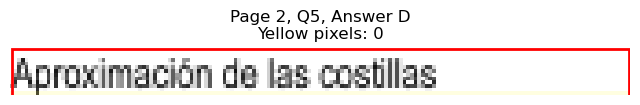

Page 2, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=483.1, y1=417.6
Page 2, Q5, E: Yellow pixels: 2106
Page 2, Q5, E: Total non-white pixels: 2898
Page 2, Q5, E: Yellow percentage: 72.7%


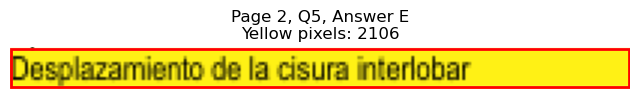


Page 2, Q5 - Selected Answer: E (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=143.1, y1=468.1
Page 2, Q6, A: Yellow pixels: 126
Page 2, Q6, A: Total non-white pixels: 462
Page 2, Q6, A: Yellow percentage: 27.3%


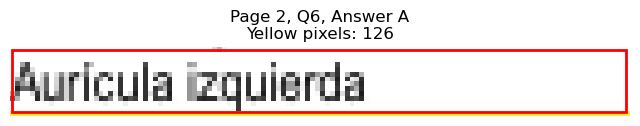

Page 2, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=146.5, y1=480.7
Page 2, Q6, B: Yellow pixels: 1380
Page 2, Q6, B: Total non-white pixels: 1677
Page 2, Q6, B: Yellow percentage: 82.3%


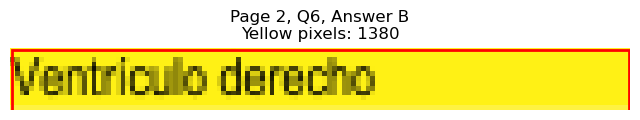

Page 2, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=151.0, y1=493.4
Page 2, Q6, C: Yellow pixels: 133
Page 2, Q6, C: Total non-white pixels: 521
Page 2, Q6, C: Yellow percentage: 25.5%


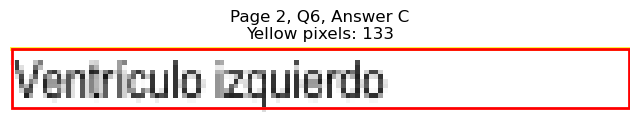

Page 2, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=405.8, y1=468.1
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 402
Page 2, Q6, D: Yellow percentage: 0.0%


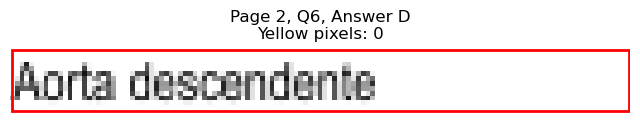

Page 2, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=397.7, y1=480.7
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 358
Page 2, Q6, E: Yellow percentage: 0.0%


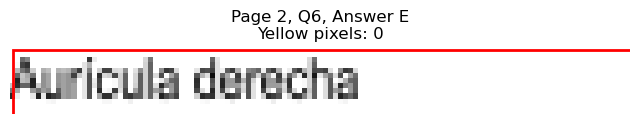


Page 2, Q6 - Selected Answer: B (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=130.9, y1=543.8
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 329
Page 2, Q7, A: Yellow percentage: 0.0%


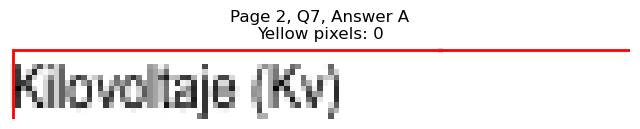

Page 2, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=100.9, y1=556.4
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 162
Page 2, Q7, B: Yellow percentage: 0.0%


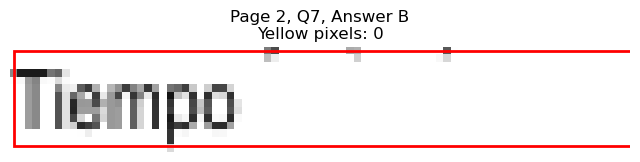

Page 2, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=147.5, y1=569.2
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 380
Page 2, Q7, C: Yellow percentage: 0.0%


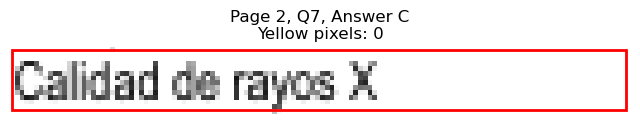

Page 2, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=402.8, y1=543.8
Page 2, Q7, D: Yellow pixels: 1320
Page 2, Q7, D: Total non-white pixels: 1638
Page 2, Q7, D: Yellow percentage: 80.6%


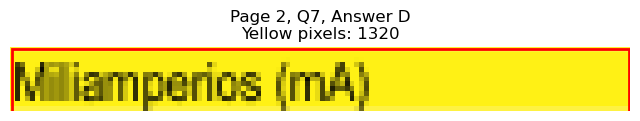

Page 2, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=402.8, y1=556.4
Page 2, Q7, E: Yellow pixels: 123
Page 2, Q7, E: Total non-white pixels: 535
Page 2, Q7, E: Yellow percentage: 23.0%


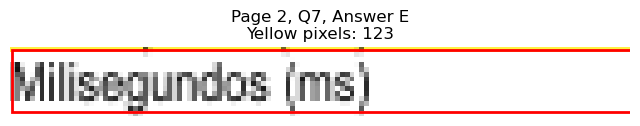


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=157.1, y1=619.6
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 433
Page 2, Q8, A: Yellow percentage: 0.0%


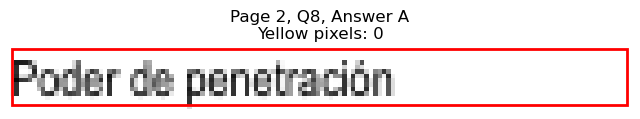

Page 2, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=149.1, y1=632.3
Page 2, Q8, B: Yellow pixels: 1265
Page 2, Q8, B: Total non-white pixels: 1848
Page 2, Q8, B: Yellow percentage: 68.5%


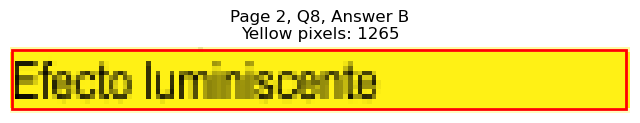

Page 2, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=135.5, y1=644.9
Page 2, Q8, C: Yellow pixels: 0
Page 2, Q8, C: Total non-white pixels: 458
Page 2, Q8, C: Yellow percentage: 0.0%


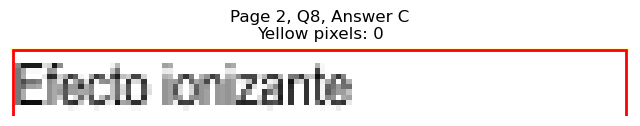

Page 2, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=393.8, y1=619.6
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 352
Page 2, Q8, D: Yellow percentage: 0.0%


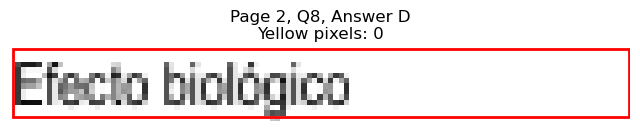

Page 2, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=399.8, y1=632.3
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 380
Page 2, Q8, E: Yellow percentage: 0.0%


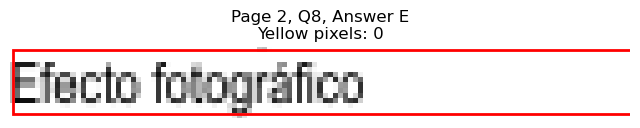


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)




Page 2, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=170.2, y1=708.0
Page 2, Q9, A: Yellow pixels: 153
Page 2, Q9, A: Total non-white pixels: 832
Page 2, Q9, A: Yellow percentage: 18.4%


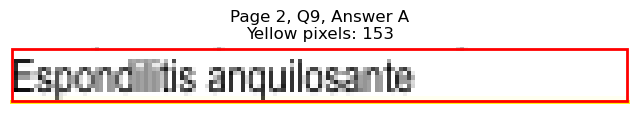

Page 2, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=186.6, y1=720.6
Page 2, Q9, B: Yellow pixels: 1682
Page 2, Q9, B: Total non-white pixels: 2366
Page 2, Q9, B: Yellow percentage: 71.1%


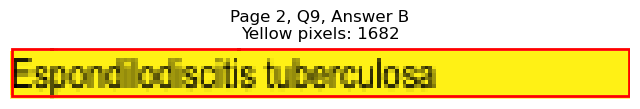

Page 2, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=191.7, y1=733.2
Page 2, Q9, C: Yellow pixels: 174
Page 2, Q9, C: Total non-white pixels: 791
Page 2, Q9, C: Yellow percentage: 22.0%


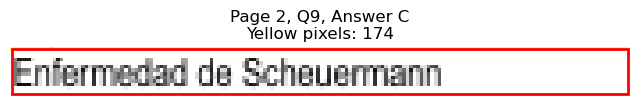

Page 2, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=438.4, y1=708.0
Page 2, Q9, D: Yellow pixels: 0
Page 2, Q9, D: Total non-white pixels: 571
Page 2, Q9, D: Yellow percentage: 0.0%


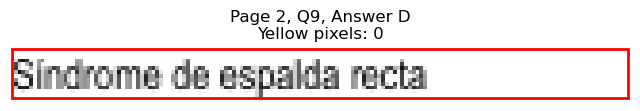

Page 2, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=396.3, y1=720.6
Page 2, Q9, E: Yellow pixels: 0
Page 2, Q9, E: Total non-white pixels: 388
Page 2, Q9, E: Yellow percentage: 0.0%


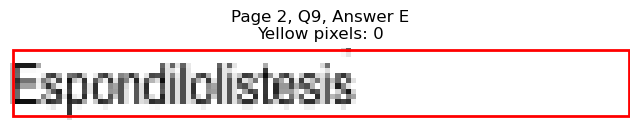


Page 2, Q9 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 9 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=97.3, y1=102.1
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 144
Page 3, Q1, A: Yellow percentage: 0.0%


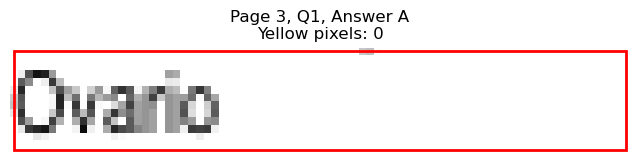

Page 3, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=96.4, y1=114.7
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 135
Page 3, Q1, B: Yellow percentage: 0.0%


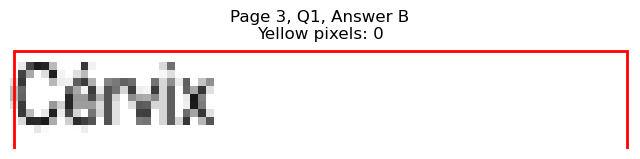

Page 3, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=148.6, y1=127.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 409
Page 3, Q1, C: Yellow percentage: 0.0%


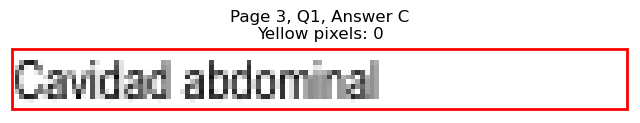

Page 3, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=376.1, y1=102.1
Page 3, Q1, D: Yellow pixels: 100
Page 3, Q1, D: Total non-white pixels: 331
Page 3, Q1, D: Yellow percentage: 30.2%


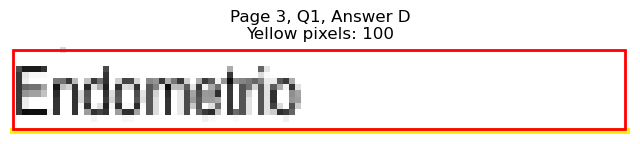

Page 3, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=402.3, y1=114.7
Page 3, Q1, E: Yellow pixels: 1372
Page 3, Q1, E: Total non-white pixels: 1638
Page 3, Q1, E: Yellow percentage: 83.8%


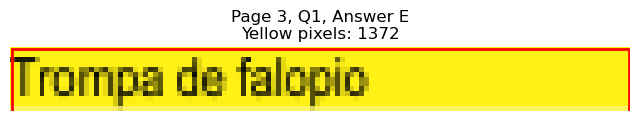


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=56.6, y0=165.1, x1=65.2, y1=177.8
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 59
Page 3, Q2, A: Yellow percentage: 0.0%


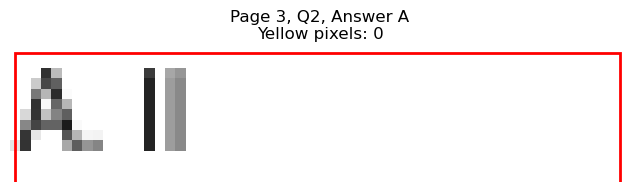

Page 3, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=79.3, y1=190.4
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 36
Page 3, Q2, B: Yellow percentage: 0.0%


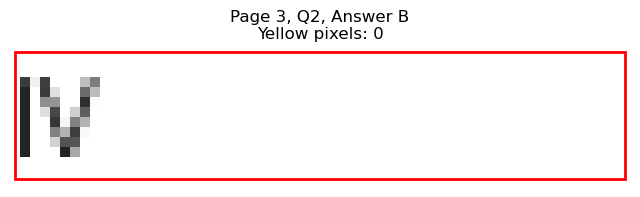

Page 3, Q2 - C: Detected box: x0=56.6, y0=190.3, x1=65.6, y1=203.0
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 65
Page 3, Q2, C: Yellow percentage: 0.0%


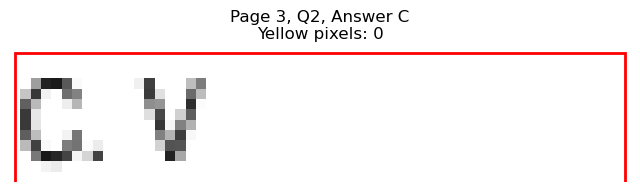

Page 3, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=338.6, y1=177.8
Page 3, Q2, D: Yellow pixels: 0
Page 3, Q2, D: Total non-white pixels: 107
Page 3, Q2, D: Yellow percentage: 0.0%


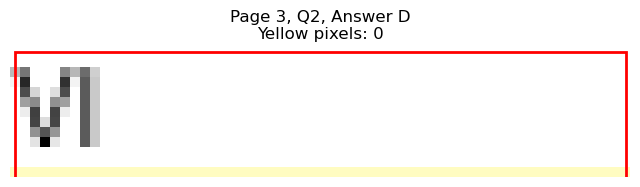

Page 3, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=337.1, y1=190.4
Page 3, Q2, E: Yellow pixels: 700
Page 3, Q2, E: Total non-white pixels: 854
Page 3, Q2, E: Yellow percentage: 82.0%


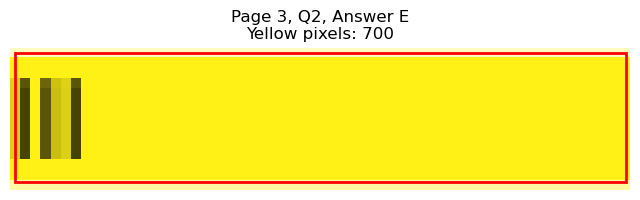


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=125.4, y1=266.1
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 296
Page 3, Q3, A: Yellow percentage: 0.0%


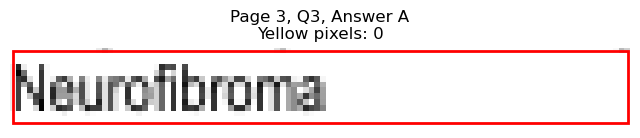

Page 3, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=131.5, y1=278.7
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 319
Page 3, Q3, B: Yellow percentage: 0.0%


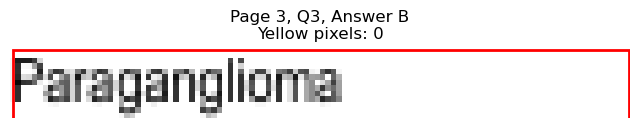

Page 3, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=176.7, y1=291.5
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 581
Page 3, Q3, C: Yellow percentage: 0.0%


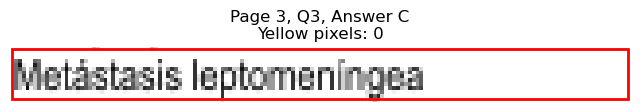

Page 3, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=412.7, y1=266.1
Page 3, Q3, D: Yellow pixels: 136
Page 3, Q3, D: Total non-white pixels: 570
Page 3, Q3, D: Yellow percentage: 23.9%


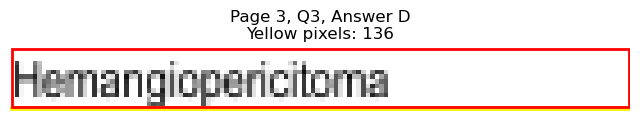

Page 3, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=378.7, y1=278.7
Page 3, Q3, E: Yellow pixels: 1130
Page 3, Q3, E: Total non-white pixels: 1326
Page 3, Q3, E: Yellow percentage: 85.2%


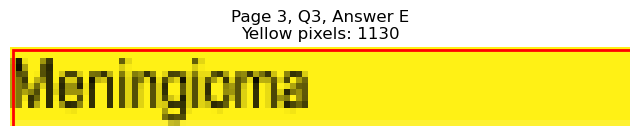


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=120.0, y1=341.9
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 259
Page 3, Q4, A: Yellow percentage: 0.0%


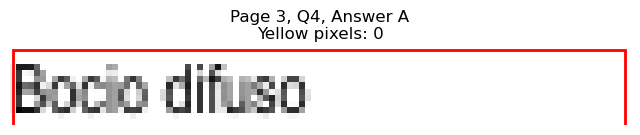

Page 3, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=185.7, y1=354.6
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 587
Page 3, Q4, B: Yellow percentage: 0.0%


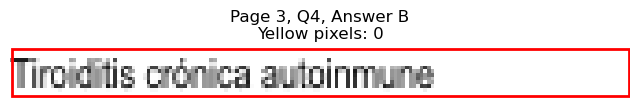

Page 3, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=147.0, y1=367.2
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 374
Page 3, Q4, C: Yellow percentage: 0.0%


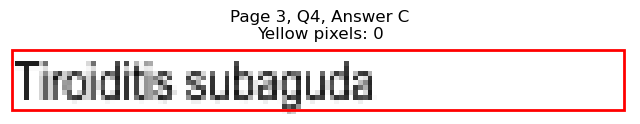

Page 3, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=404.2, y1=341.9
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 392
Page 3, Q4, D: Yellow percentage: 0.0%


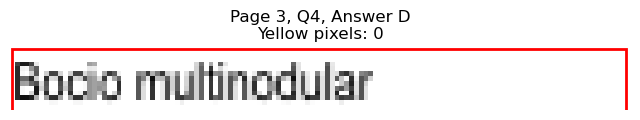

Page 3, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=398.2, y1=354.6
Page 3, Q4, E: Yellow pixels: 1293
Page 3, Q4, E: Total non-white pixels: 1708
Page 3, Q4, E: Yellow percentage: 75.7%


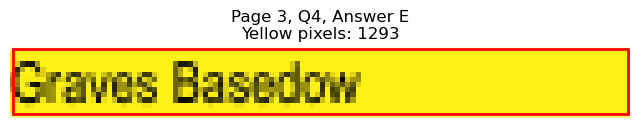


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=56.6, y0=404.9, x1=65.2, y1=417.6
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 47
Page 3, Q5, A: Yellow percentage: 0.0%


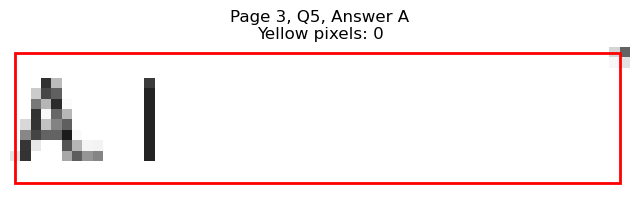

Page 3, Q5 - B: Detected box: x0=56.6, y0=417.6, x1=65.2, y1=430.3
Page 3, Q5, B: Yellow pixels: 60
Page 3, Q5, B: Total non-white pixels: 126
Page 3, Q5, B: Yellow percentage: 47.6%


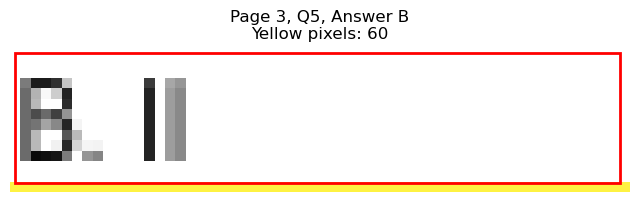

Page 3, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=78.9, y1=442.9
Page 3, Q5, C: Yellow pixels: 753
Page 3, Q5, C: Total non-white pixels: 793
Page 3, Q5, C: Yellow percentage: 95.0%


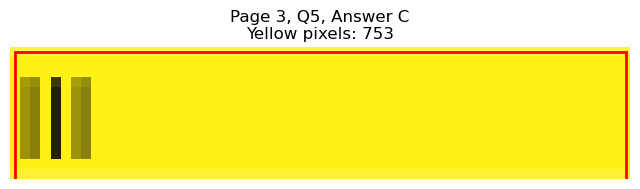

Page 3, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=340.6, y1=417.6
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 59
Page 3, Q5, D: Yellow percentage: 0.0%


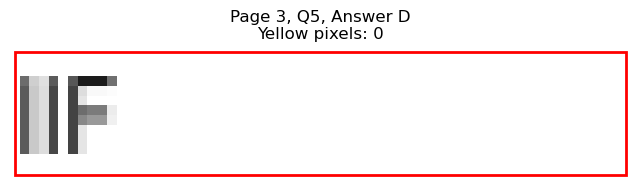

Page 3, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=338.1, y1=430.3
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 45
Page 3, Q5, E: Yellow percentage: 0.0%


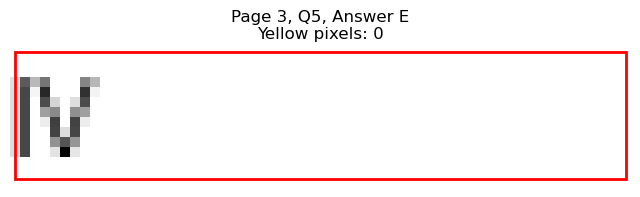


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=179.7, y1=493.4
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 511
Page 3, Q6, A: Yellow percentage: 0.0%


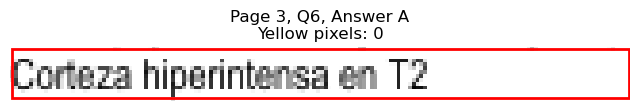

Page 3, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=169.1, y1=506.0
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 518
Page 3, Q6, B: Yellow percentage: 0.0%


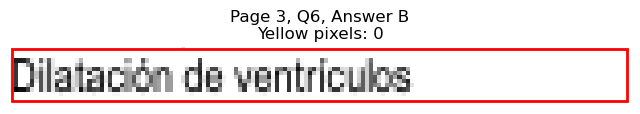

Page 3, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=186.6, y1=518.6
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 579
Page 3, Q6, C: Yellow percentage: 0.0%


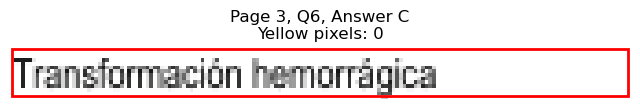

Page 3, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=396.3, y1=493.4
Page 3, Q6, D: Yellow pixels: 120
Page 3, Q6, D: Total non-white pixels: 472
Page 3, Q6, D: Yellow percentage: 25.4%


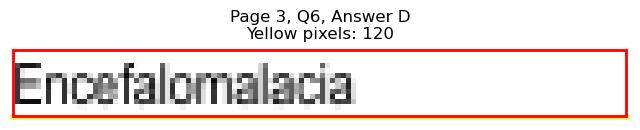

Page 3, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=404.8, y1=506.0
Page 3, Q6, E: Yellow pixels: 1351
Page 3, Q6, E: Total non-white pixels: 1666
Page 3, Q6, E: Yellow percentage: 81.1%


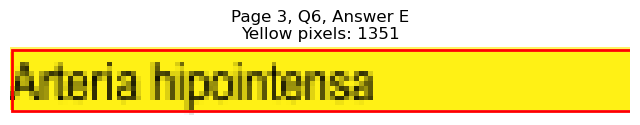


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=174.1, y1=556.4
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 528
Page 3, Q7, A: Yellow percentage: 0.0%


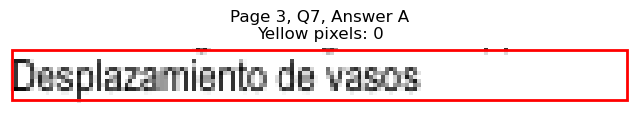

Page 3, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=118.9, y1=569.2
Page 3, Q7, B: Yellow pixels: 1136
Page 3, Q7, B: Total non-white pixels: 1414
Page 3, Q7, B: Yellow percentage: 80.3%


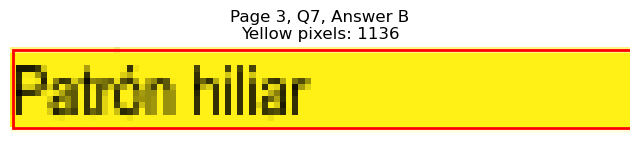

Page 3, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=237.3, y1=581.8
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 1042
Page 3, Q7, C: Yellow percentage: 0.0%


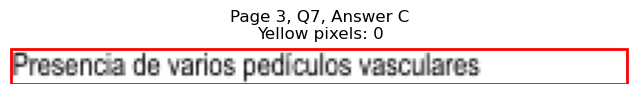

Page 3, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=450.9, y1=556.4
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 595
Page 3, Q7, D: Yellow percentage: 0.0%


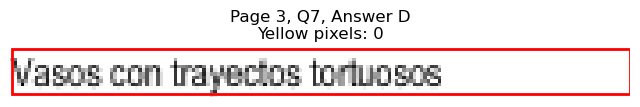

Page 3, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=440.5, y1=569.2
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 573
Page 3, Q7, E: Yellow percentage: 0.0%


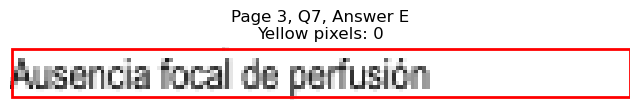


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=97.9, y1=632.3
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 150
Page 3, Q8, A: Yellow percentage: 0.0%


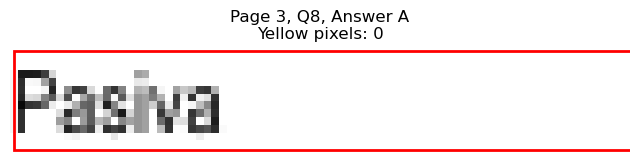

Page 3, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=119.4, y1=644.9
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 257
Page 3, Q8, B: Yellow percentage: 0.0%


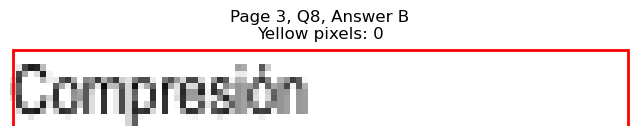

Page 3, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=108.4, y1=657.5
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 204
Page 3, Q8, C: Yellow percentage: 0.0%


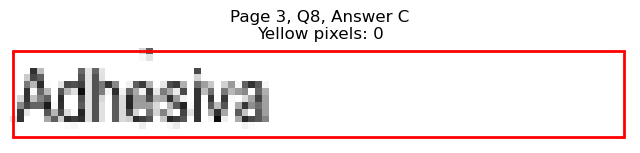

Page 3, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=381.7, y1=632.3
Page 3, Q8, D: Yellow pixels: 105
Page 3, Q8, D: Total non-white pixels: 389
Page 3, Q8, D: Yellow percentage: 27.0%


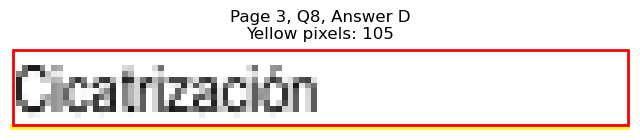

Page 3, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=380.2, y1=644.9
Page 3, Q8, E: Yellow pixels: 1149
Page 3, Q8, E: Total non-white pixels: 1352
Page 3, Q8, E: Yellow percentage: 85.0%


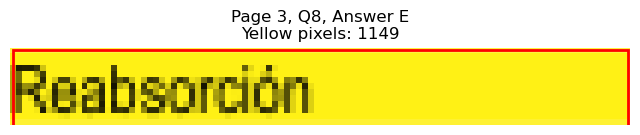


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)




Page 3, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=212.3, y1=720.6
Page 3, Q9, A: Yellow pixels: 0
Page 3, Q9, A: Total non-white pixels: 740
Page 3, Q9, A: Yellow percentage: 0.0%


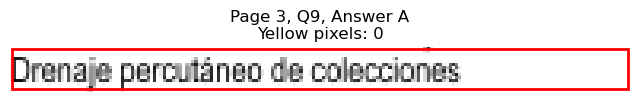

Page 3, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=182.7, y1=733.2
Page 3, Q9, B: Yellow pixels: 0
Page 3, Q9, B: Total non-white pixels: 606
Page 3, Q9, B: Yellow percentage: 0.0%


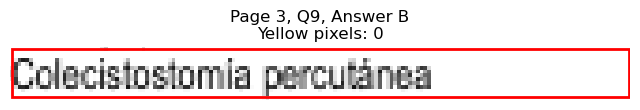

Page 3, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=104.9, y1=745.8
Page 3, Q9, C: Yellow pixels: 0
Page 3, Q9, C: Total non-white pixels: 183
Page 3, Q9, C: Yellow percentage: 0.0%


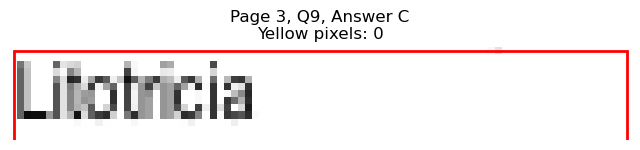

Page 3, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=426.9, y1=720.6
Page 3, Q9, D: Yellow pixels: 1555
Page 3, Q9, D: Total non-white pixels: 2100
Page 3, Q9, D: Yellow percentage: 74.0%


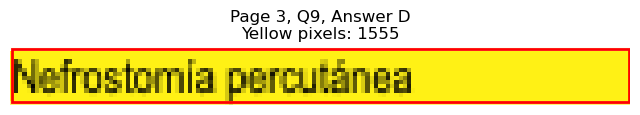

Page 3, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=378.7, y1=733.2
Page 3, Q9, E: Yellow pixels: 102
Page 3, Q9, E: Total non-white pixels: 380
Page 3, Q9, E: Yellow percentage: 26.8%


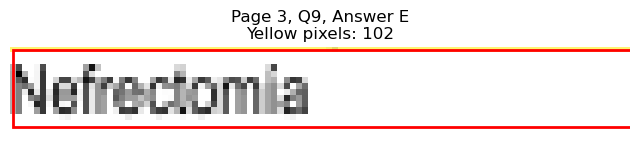


Page 3, Q9 - Selected Answer: D (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=106.5, y1=114.7
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 291
Page 4, Q1, A: Yellow percentage: 0.0%


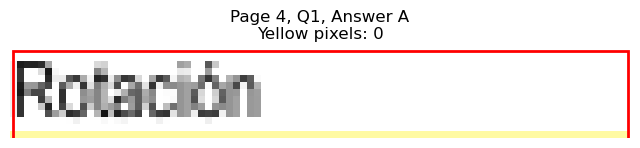

Page 4, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=134.1, y1=127.3
Page 4, Q1, B: Yellow pixels: 1158
Page 4, Q1, B: Total non-white pixels: 1638
Page 4, Q1, B: Yellow percentage: 70.7%


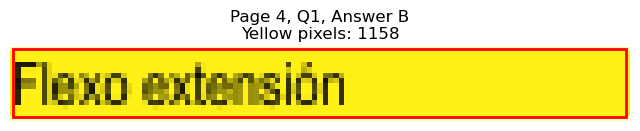

Page 4, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=102.9, y1=139.9
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 262
Page 4, Q1, C: Yellow percentage: 0.0%


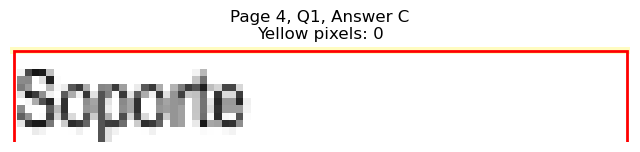

Page 4, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=354.7, y1=114.7
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 142
Page 4, Q1, D: Yellow percentage: 0.0%


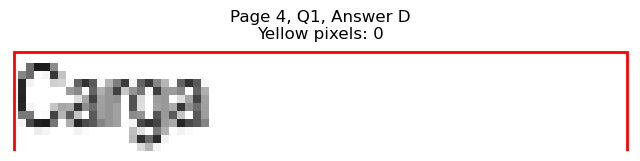

Page 4, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=394.3, y1=127.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 362
Page 4, Q1, E: Yellow percentage: 0.0%


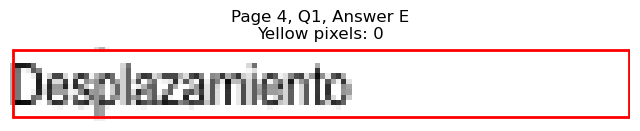


Page 4, Q1 - Selected Answer: B (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=177.6, y1=190.4
Page 4, Q2, A: Yellow pixels: 0
Page 4, Q2, A: Total non-white pixels: 539
Page 4, Q2, A: Yellow percentage: 0.0%


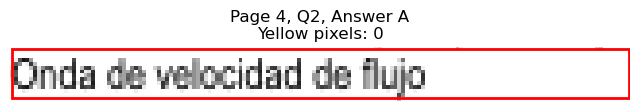

Page 4, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=132.0, y1=203.0
Page 4, Q2, B: Yellow pixels: 0
Page 4, Q2, B: Total non-white pixels: 305
Page 4, Q2, B: Yellow percentage: 0.0%


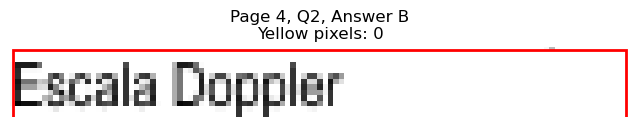

Page 4, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=144.0, y1=215.6
Page 4, Q2, C: Yellow pixels: 0
Page 4, Q2, C: Total non-white pixels: 371
Page 4, Q2, C: Yellow percentage: 0.0%


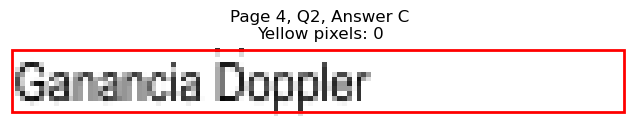

Page 4, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=413.3, y1=190.4
Page 4, Q2, D: Yellow pixels: 1328
Page 4, Q2, D: Total non-white pixels: 1918
Page 4, Q2, D: Yellow percentage: 69.2%


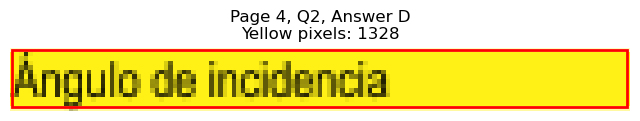

Page 4, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=400.3, y1=203.0
Page 4, Q2, E: Yellow pixels: 1
Page 4, Q2, E: Total non-white pixels: 482
Page 4, Q2, E: Yellow percentage: 0.2%


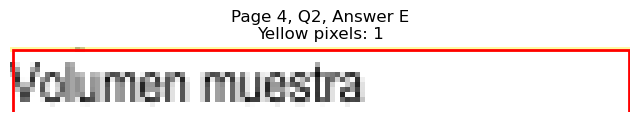


Page 4, Q2 - Selected Answer: D (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=156.0, y1=266.1
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 479
Page 4, Q3, A: Yellow percentage: 0.0%


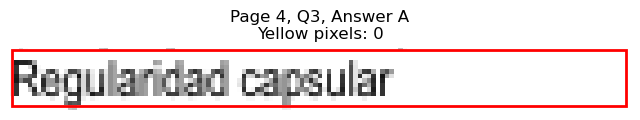

Page 4, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=103.5, y1=278.7
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 192
Page 4, Q3, B: Yellow percentage: 0.0%


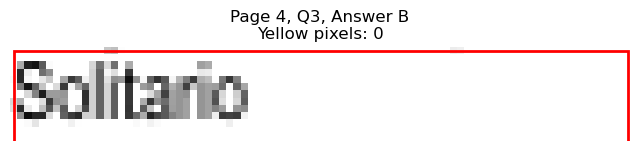

Page 4, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=172.1, y1=291.5
Page 4, Q3, C: Yellow pixels: 1643
Page 4, Q3, C: Total non-white pixels: 2170
Page 4, Q3, C: Yellow percentage: 75.7%


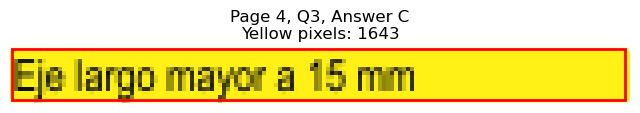

Page 4, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=390.2, y1=266.1
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 303
Page 4, Q3, D: Yellow percentage: 0.0%


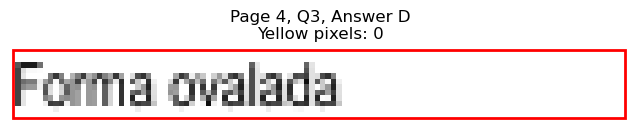

Page 4, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=385.7, y1=278.7
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 306
Page 4, Q3, E: Yellow percentage: 0.0%


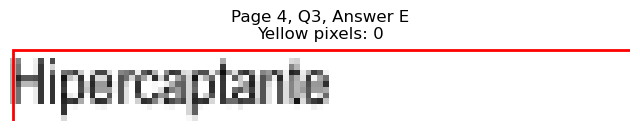


Page 4, Q3 - Selected Answer: C (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=121.9, y1=354.6
Page 4, Q4, A: Yellow pixels: 1125
Page 4, Q4, A: Total non-white pixels: 1456
Page 4, Q4, A: Yellow percentage: 77.3%


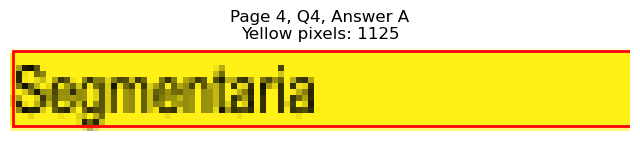

Page 4, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=106.5, y1=367.2
Page 4, Q4, B: Yellow pixels: 88
Page 4, Q4, B: Total non-white pixels: 302
Page 4, Q4, B: Yellow percentage: 29.1%


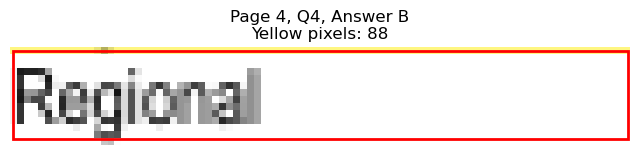

Page 4, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=95.4, y1=379.8
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 133
Page 4, Q4, C: Yellow percentage: 0.0%


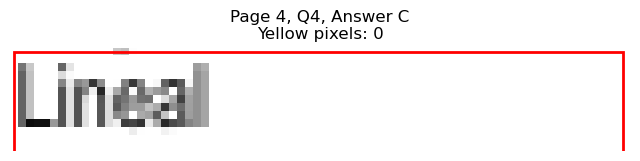

Page 4, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=355.6, y1=354.6
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 142
Page 4, Q4, D: Yellow percentage: 0.0%


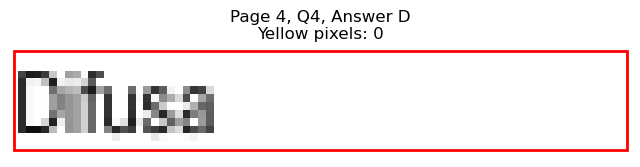

Page 4, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=351.7, y1=367.2
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 123
Page 4, Q4, E: Yellow percentage: 0.0%


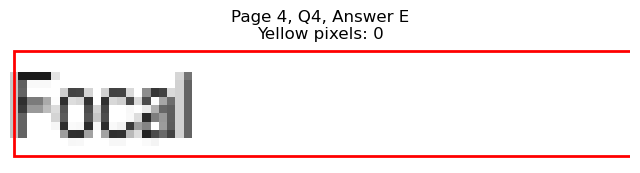


Page 4, Q4 - Selected Answer: A (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=97.9, y1=417.6
Page 4, Q5, A: Yellow pixels: 931
Page 4, Q5, A: Total non-white pixels: 1120
Page 4, Q5, A: Yellow percentage: 83.1%


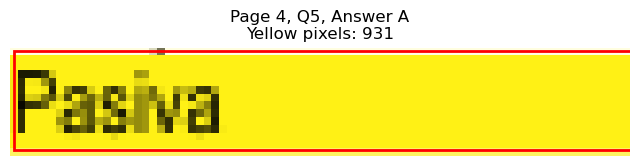

Page 4, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=122.4, y1=430.3
Page 4, Q5, B: Yellow pixels: 105
Page 4, Q5, B: Total non-white pixels: 389
Page 4, Q5, B: Yellow percentage: 27.0%


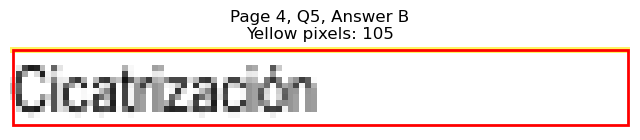

Page 4, Q5 - C: Detected box: x0=68.8, y0=430.2, x1=108.4, y1=442.9
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 200
Page 4, Q5, C: Yellow percentage: 0.0%


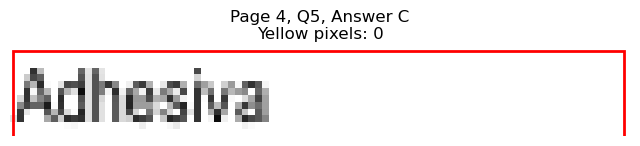

Page 4, Q5 - D: Detected box: x0=327.5, y0=404.9, x1=378.7, y1=417.6
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 252
Page 4, Q5, D: Yellow percentage: 0.0%


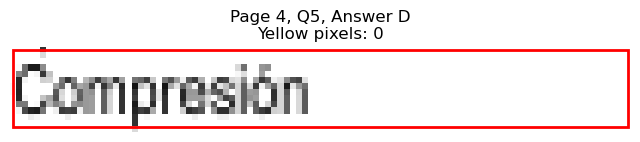

Page 4, Q5 - E: Detected box: x0=327.0, y0=417.6, x1=380.2, y1=430.3
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 275
Page 4, Q5, E: Yellow percentage: 0.0%


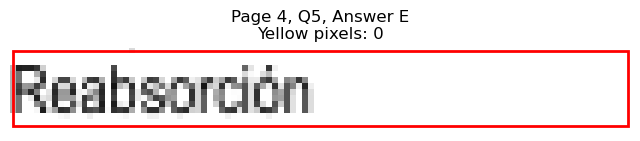


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=168.6, y1=493.4
Page 4, Q6, A: Yellow pixels: 0
Page 4, Q6, A: Total non-white pixels: 491
Page 4, Q6, A: Yellow percentage: 0.0%


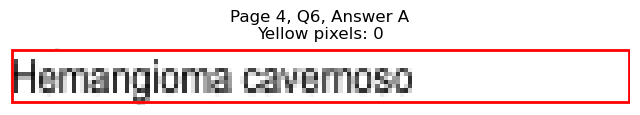

Page 4, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=158.5, y1=506.0
Page 4, Q6, B: Yellow pixels: 0
Page 4, Q6, B: Total non-white pixels: 453
Page 4, Q6, B: Yellow percentage: 0.0%


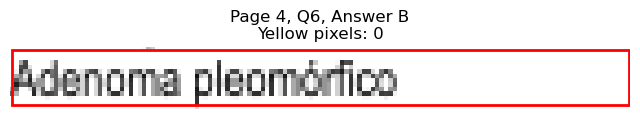

Page 4, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=100.9, y1=518.6
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 154
Page 4, Q6, C: Yellow percentage: 0.0%


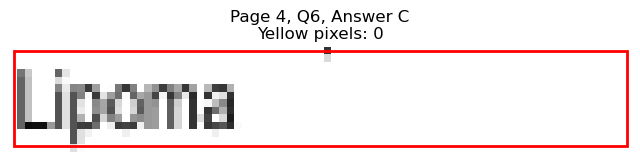

Page 4, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=378.2, y1=493.4
Page 4, Q6, D: Yellow pixels: 102
Page 4, Q6, D: Total non-white pixels: 346
Page 4, Q6, D: Yellow percentage: 29.5%


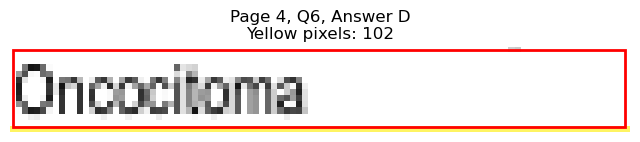

Page 4, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=401.8, y1=506.0
Page 4, Q6, E: Yellow pixels: 1349
Page 4, Q6, E: Total non-white pixels: 1625
Page 4, Q6, E: Yellow percentage: 83.0%


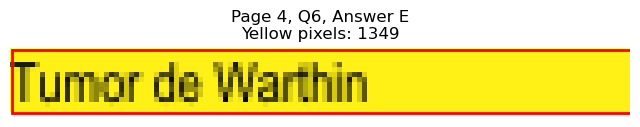


Page 4, Q6 - Selected Answer: E (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=556.5, x1=110.4, y1=569.2
Page 4, Q7, A: Yellow pixels: 93
Page 4, Q7, A: Total non-white pixels: 313
Page 4, Q7, A: Yellow percentage: 29.7%


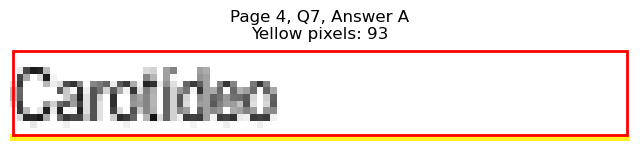

Page 4, Q7 - B: Detected box: x0=68.3, y0=569.1, x1=102.9, y1=581.8
Page 4, Q7, B: Yellow pixels: 978
Page 4, Q7, B: Total non-white pixels: 1105
Page 4, Q7, B: Yellow percentage: 88.5%


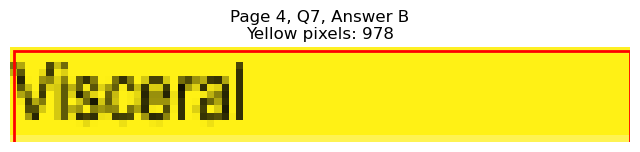

Page 4, Q7 - C: Detected box: x0=68.8, y0=581.7, x1=141.5, y1=594.4
Page 4, Q7, C: Yellow pixels: 124
Page 4, Q7, C: Total non-white pixels: 500
Page 4, Q7, C: Yellow percentage: 24.8%


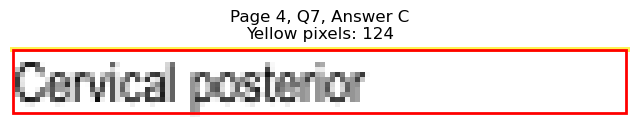

Page 4, Q7 - D: Detected box: x0=327.5, y0=556.5, x1=385.3, y1=569.2
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 304
Page 4, Q7, D: Yellow percentage: 0.0%


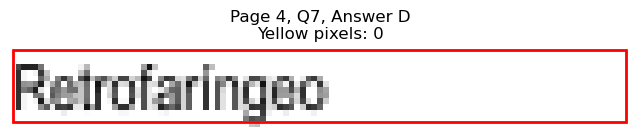

Page 4, Q7 - E: Detected box: x0=327.0, y0=569.1, x1=380.7, y1=581.8
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 291
Page 4, Q7, E: Yellow percentage: 0.0%


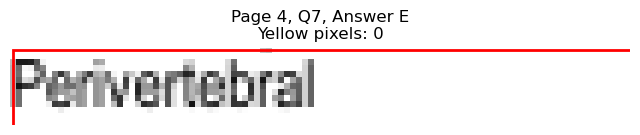


Page 4, Q7 - Selected Answer: B (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=125.5, y1=657.5
Page 4, Q8, A: Yellow pixels: 0
Page 4, Q8, A: Total non-white pixels: 288
Page 4, Q8, A: Yellow percentage: 0.0%


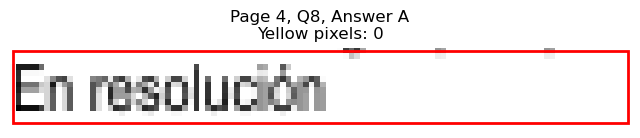

Page 4, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=112.9, y1=670.1
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 221
Page 4, Q8, B: Yellow percentage: 0.0%


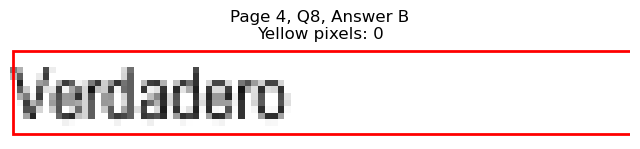

Page 4, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=136.0, y1=682.7
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 360
Page 4, Q8, C: Yellow percentage: 0.0%


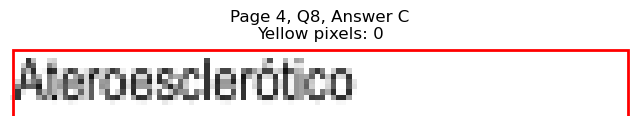

Page 4, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=377.2, y1=657.5
Page 4, Q8, D: Yellow pixels: 101
Page 4, Q8, D: Total non-white pixels: 348
Page 4, Q8, D: Yellow percentage: 29.0%


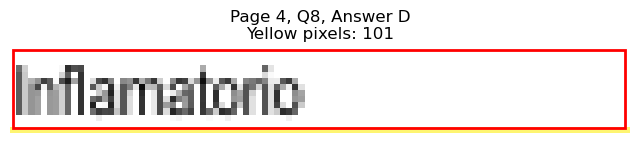

Page 4, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=362.7, y1=670.1
Page 4, Q8, E: Yellow pixels: 975
Page 4, Q8, E: Total non-white pixels: 1204
Page 4, Q8, E: Yellow percentage: 81.0%


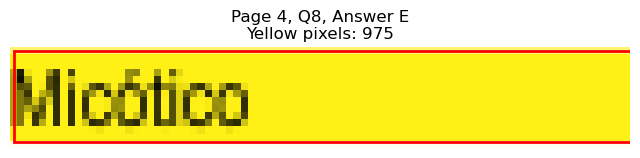


Page 4, Q8 - Selected Answer: E (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=116.9, y1=733.2
Page 4, Q9, A: Yellow pixels: 99
Page 4, Q9, A: Total non-white pixels: 368
Page 4, Q9, A: Yellow percentage: 26.9%


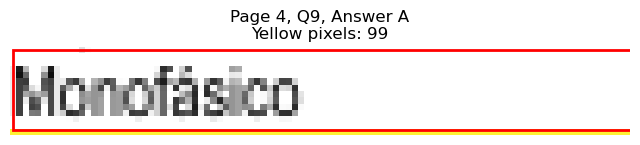

Page 4, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=99.9, y1=745.8
Page 4, Q9, B: Yellow pixels: 932
Page 4, Q9, B: Total non-white pixels: 1066
Page 4, Q9, B: Yellow percentage: 87.4%


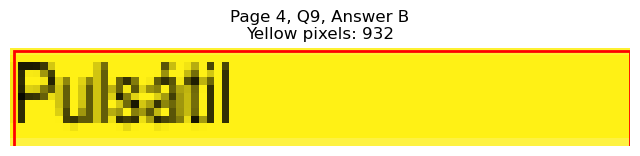

Page 4, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=102.9, y1=758.4
Page 4, Q9, C: Yellow pixels: 85
Page 4, Q9, C: Total non-white pixels: 279
Page 4, Q9, C: Yellow percentage: 30.5%


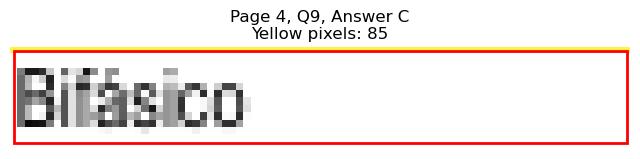

Page 4, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=363.7, y1=733.2
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 177
Page 4, Q9, D: Yellow percentage: 0.0%


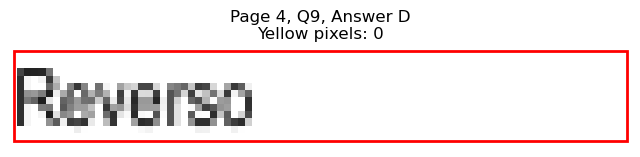

Page 4, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=360.3, y1=745.8
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 185
Page 4, Q9, E: Yellow percentage: 0.0%


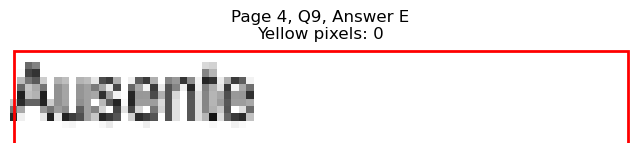


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 9 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=109.5, y1=127.3
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 213
Page 5, Q1, A: Yellow percentage: 0.0%


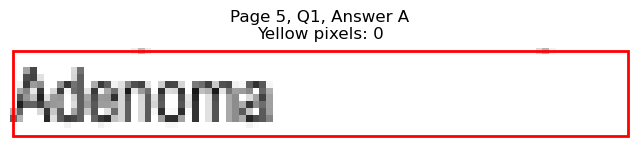

Page 5, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=141.5, y1=139.9
Page 5, Q1, B: Yellow pixels: 0
Page 5, Q1, B: Total non-white pixels: 371
Page 5, Q1, B: Yellow percentage: 0.0%


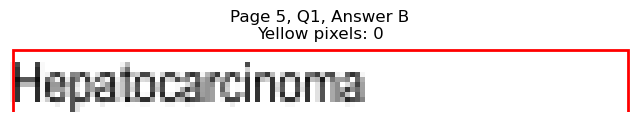

Page 5, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=169.1, y1=152.6
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 511
Page 5, Q1, C: Yellow percentage: 0.0%


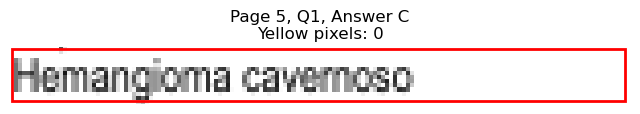

Page 5, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=423.3, y1=127.3
Page 5, Q1, D: Yellow pixels: 1377
Page 5, Q1, D: Total non-white pixels: 2058
Page 5, Q1, D: Yellow percentage: 66.9%


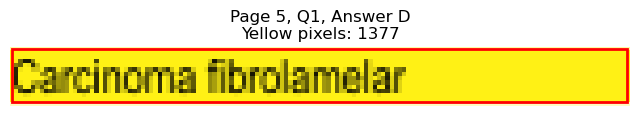

Page 5, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=361.6, y1=139.9
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 244
Page 5, Q1, E: Yellow percentage: 0.0%


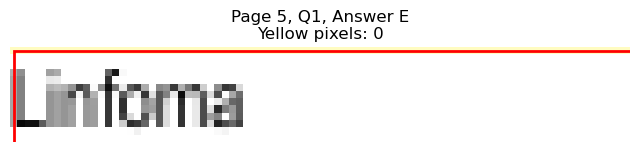


Page 5, Q1 - Selected Answer: D (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=250.8, y1=203.0
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 895
Page 5, Q2, A: Yellow percentage: 0.0%


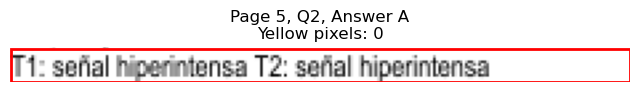

Page 5, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=282.4, y1=215.6
Page 5, Q2, B: Yellow pixels: 201
Page 5, Q2, B: Total non-white pixels: 1356
Page 5, Q2, B: Yellow percentage: 14.8%


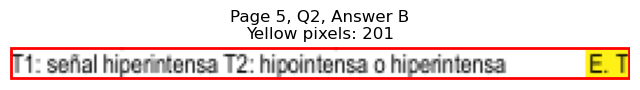

Page 5, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=273.5, y1=228.3
Page 5, Q2, C: Yellow pixels: 130
Page 5, Q2, C: Total non-white pixels: 1119
Page 5, Q2, C: Yellow percentage: 11.6%


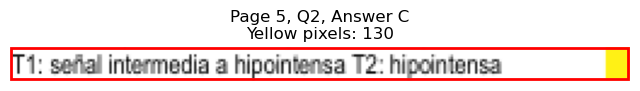

Page 5, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=485.5, y1=203.0
Page 5, Q2, D: Yellow pixels: 0
Page 5, Q2, D: Total non-white pixels: 971
Page 5, Q2, D: Yellow percentage: 0.0%


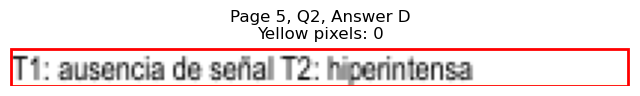

Page 5, Q2 - E: Detected box: x0=482.7, y0=202.9, x1=527.5, y1=215.6
Page 5, Q2, E: Yellow pixels: 548
Page 5, Q2, E: Total non-white pixels: 825
Page 5, Q2, E: Yellow percentage: 66.4%


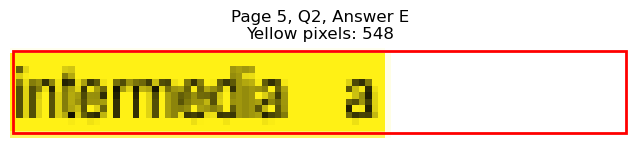


Page 5, Q2 - Selected Answer: E (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=110.9, y1=278.7
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 201
Page 5, Q3, A: Yellow percentage: 0.0%


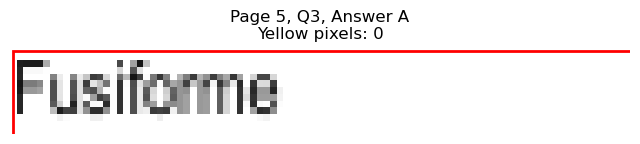

Page 5, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=118.0, y1=291.5
Page 5, Q3, B: Yellow pixels: 1107
Page 5, Q3, B: Total non-white pixels: 1400
Page 5, Q3, B: Yellow percentage: 79.1%


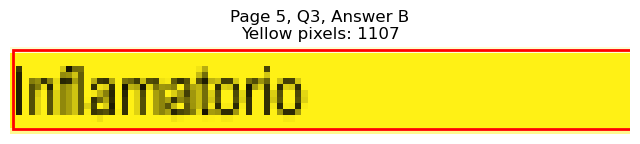

Page 5, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=113.5, y1=304.1
Page 5, Q3, C: Yellow pixels: 96
Page 5, Q3, C: Total non-white pixels: 324
Page 5, Q3, C: Yellow percentage: 29.6%


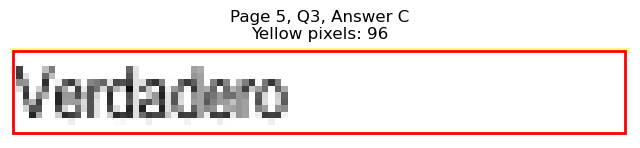

Page 5, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=370.1, y1=278.7
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 229
Page 5, Q3, D: Yellow percentage: 0.0%


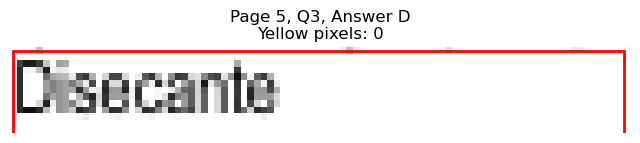

Page 5, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=402.3, y1=291.5
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 395
Page 5, Q3, E: Yellow percentage: 0.0%


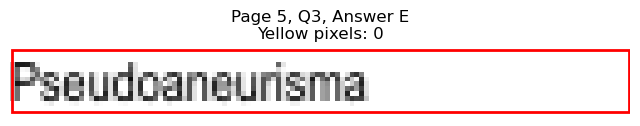


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=92.4, y1=341.9
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 118
Page 5, Q4, A: Yellow percentage: 0.0%


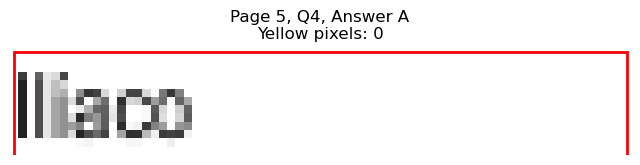

Page 5, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=103.9, y1=354.6
Page 5, Q4, B: Yellow pixels: 971
Page 5, Q4, B: Total non-white pixels: 1204
Page 5, Q4, B: Yellow percentage: 80.6%


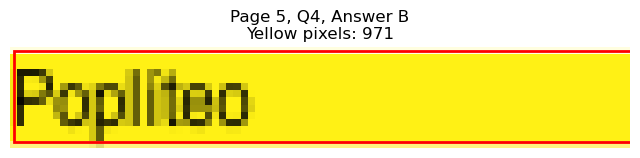

Page 5, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=104.4, y1=367.2
Page 5, Q4, C: Yellow pixels: 87
Page 5, Q4, C: Total non-white pixels: 267
Page 5, Q4, C: Yellow percentage: 32.6%


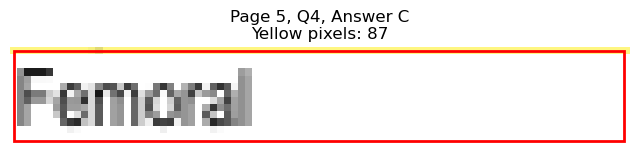

Page 5, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=353.1, y1=341.9
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 116
Page 5, Q4, D: Yellow percentage: 0.0%


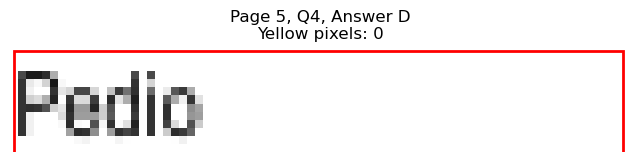

Page 5, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=351.2, y1=354.6
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 108
Page 5, Q4, E: Yellow percentage: 0.0%


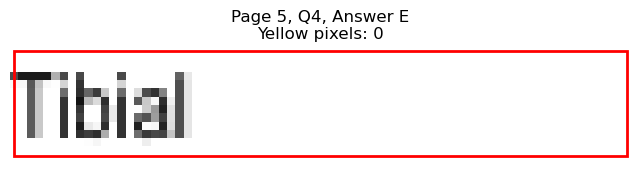


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=95.9, y1=405.0
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 224
Page 5, Q5, A: Yellow percentage: 0.0%


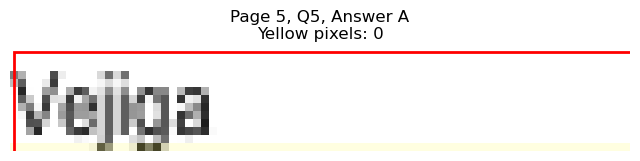

Page 5, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=101.4, y1=417.6
Page 5, Q5, B: Yellow pixels: 960
Page 5, Q5, B: Total non-white pixels: 1176
Page 5, Q5, B: Yellow percentage: 81.6%


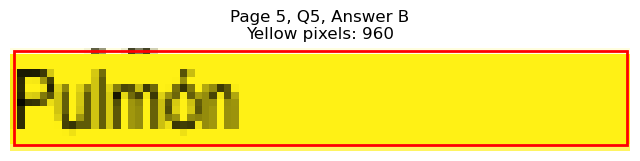

Page 5, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=109.5, y1=430.3
Page 5, Q5, C: Yellow pixels: 92
Page 5, Q5, C: Total non-white pixels: 294
Page 5, Q5, C: Yellow percentage: 31.3%


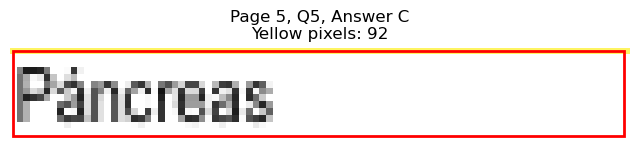

Page 5, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=363.7, y1=405.0
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 192
Page 5, Q5, D: Yellow percentage: 0.0%


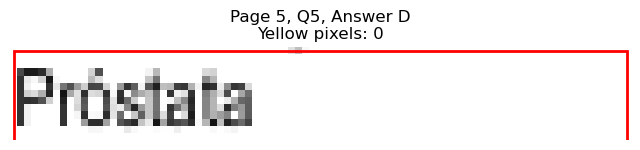

Page 5, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=362.2, y1=417.6
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 165
Page 5, Q5, E: Yellow percentage: 0.0%


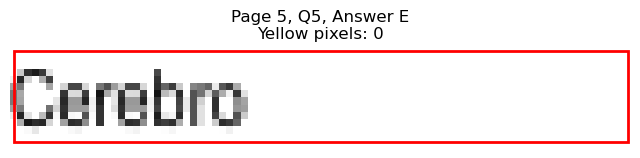


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=493.4, x1=111.4, y1=506.0
Page 5, Q6, A: Yellow pixels: 0
Page 5, Q6, A: Total non-white pixels: 226
Page 5, Q6, A: Yellow percentage: 0.0%


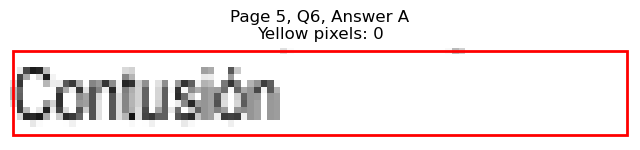

Page 5, Q6 - B: Detected box: x0=68.3, y0=506.0, x1=115.0, y1=518.6
Page 5, Q6, B: Yellow pixels: 0
Page 5, Q6, B: Total non-white pixels: 216
Page 5, Q6, B: Yellow percentage: 0.0%


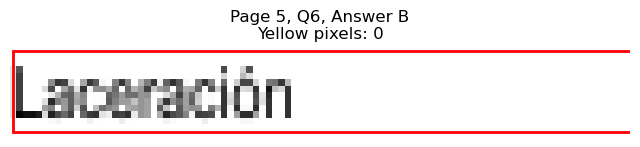

Page 5, Q6 - C: Detected box: x0=68.8, y0=518.6, x1=127.5, y1=531.2
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 320
Page 5, Q6, C: Yellow percentage: 0.0%


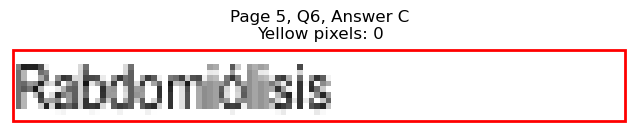

Page 5, Q6 - D: Detected box: x0=327.5, y0=493.4, x1=373.1, y1=506.0
Page 5, Q6, D: Yellow pixels: 97
Page 5, Q6, D: Total non-white pixels: 431
Page 5, Q6, D: Yellow percentage: 22.5%


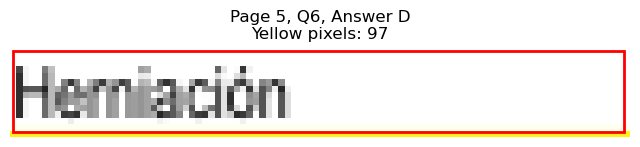

Page 5, Q6 - E: Detected box: x0=327.0, y0=506.0, x1=366.7, y1=518.6
Page 5, Q6, E: Yellow pixels: 1002
Page 5, Q6, E: Total non-white pixels: 1260
Page 5, Q6, E: Yellow percentage: 79.5%


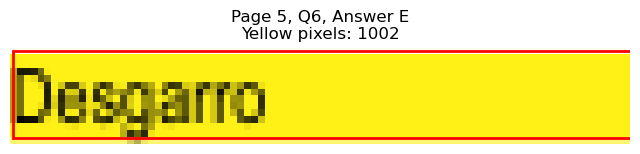


Page 5, Q6 - Selected Answer: E (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=123.0, y1=581.8
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 382
Page 5, Q7, A: Yellow percentage: 0.0%


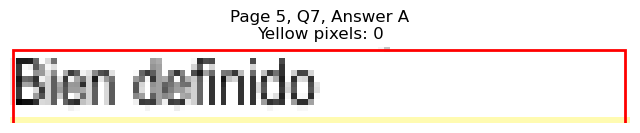

Page 5, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=118.5, y1=594.4
Page 5, Q7, B: Yellow pixels: 1042
Page 5, Q7, B: Total non-white pixels: 1414
Page 5, Q7, B: Yellow percentage: 73.7%


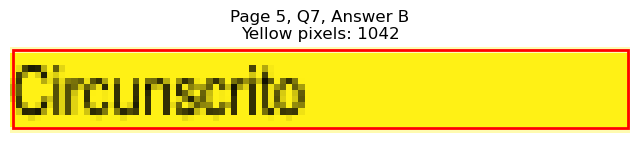

Page 5, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=133.0, y1=607.0
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 440
Page 5, Q7, C: Yellow percentage: 0.0%


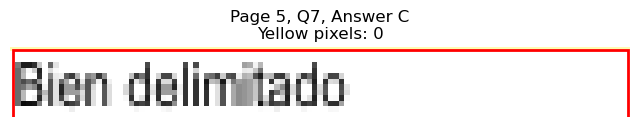

Page 5, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=353.6, y1=581.8
Page 5, Q7, D: Yellow pixels: 0
Page 5, Q7, D: Total non-white pixels: 144
Page 5, Q7, D: Yellow percentage: 0.0%


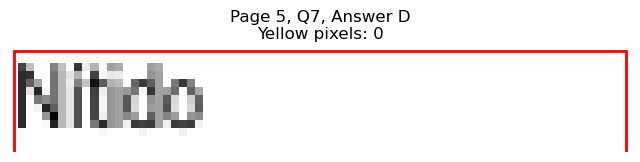

Page 5, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=361.1, y1=594.4
Page 5, Q7, E: Yellow pixels: 0
Page 5, Q7, E: Total non-white pixels: 175
Page 5, Q7, E: Yellow percentage: 0.0%


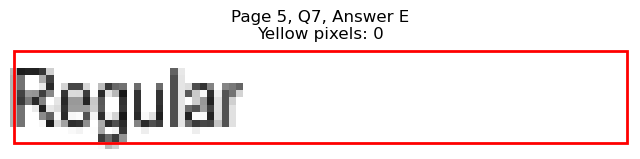


Page 5, Q7 - Selected Answer: B (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=118.9, y1=657.5
Page 5, Q8, A: Yellow pixels: 0
Page 5, Q8, A: Total non-white pixels: 261
Page 5, Q8, A: Yellow percentage: 0.0%


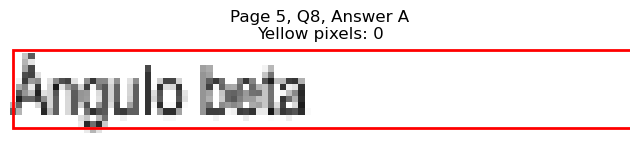

Page 5, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=185.7, y1=670.1
Page 5, Q8, B: Yellow pixels: 166
Page 5, Q8, B: Total non-white pixels: 748
Page 5, Q8, B: Yellow percentage: 22.2%


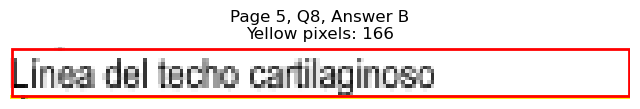

Page 5, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=116.4, y1=682.7
Page 5, Q8, C: Yellow pixels: 1106
Page 5, Q8, C: Total non-white pixels: 1287
Page 5, Q8, C: Yellow percentage: 85.9%


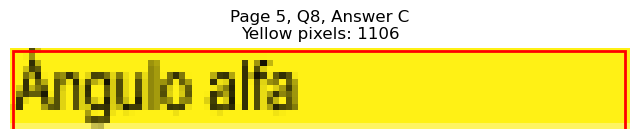

Page 5, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=393.8, y1=657.5
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 326
Page 5, Q8, D: Yellow percentage: 0.0%


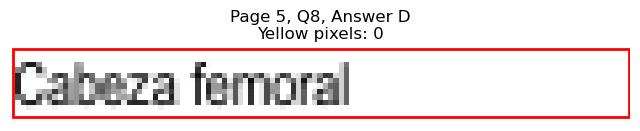

Page 5, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=397.3, y1=670.1
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 365
Page 5, Q8, E: Yellow percentage: 0.0%


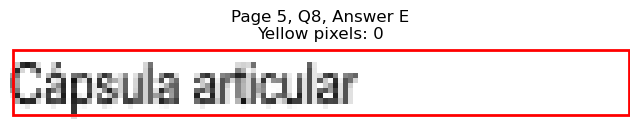


Page 5, Q8 - Selected Answer: C (based on yellow pixel count)




Page 5, Q9 - A: Detected box: x0=68.3, y0=708.0, x1=112.9, y1=720.6
Page 5, Q9, A: Yellow pixels: 1045
Page 5, Q9, A: Total non-white pixels: 1330
Page 5, Q9, A: Yellow percentage: 78.6%


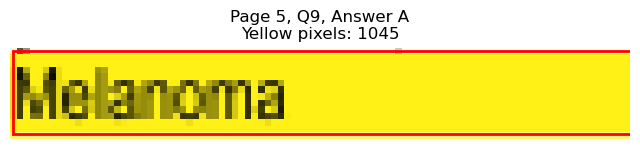

Page 5, Q9 - B: Detected box: x0=68.3, y0=720.6, x1=96.4, y1=733.2
Page 5, Q9, B: Yellow pixels: 79
Page 5, Q9, B: Total non-white pixels: 207
Page 5, Q9, B: Yellow percentage: 38.2%


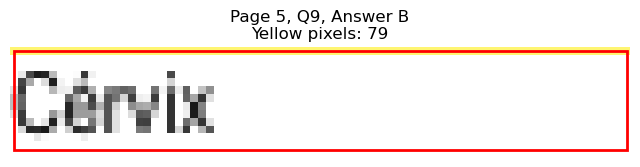

Page 5, Q9 - C: Detected box: x0=68.8, y0=733.2, x1=103.3, y1=745.8
Page 5, Q9, C: Yellow pixels: 0
Page 5, Q9, C: Total non-white pixels: 168
Page 5, Q9, C: Yellow percentage: 0.0%


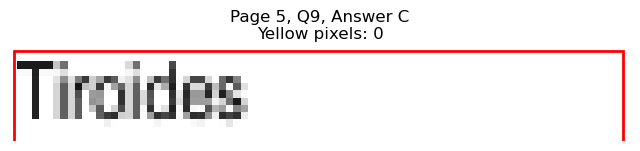

Page 5, Q9 - D: Detected box: x0=327.5, y0=708.0, x1=376.1, y1=720.6
Page 5, Q9, D: Yellow pixels: 0
Page 5, Q9, D: Total non-white pixels: 238
Page 5, Q9, D: Yellow percentage: 0.0%


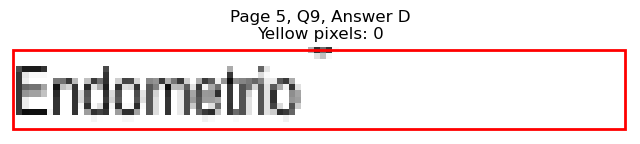

Page 5, Q9 - E: Detected box: x0=327.0, y0=720.6, x1=365.3, y1=733.2
Page 5, Q9, E: Yellow pixels: 0
Page 5, Q9, E: Total non-white pixels: 205
Page 5, Q9, E: Yellow percentage: 0.0%


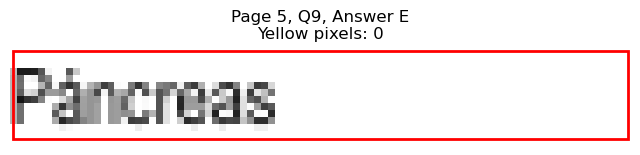


Page 5, Q9 - Selected Answer: A (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=135.0, y1=114.7
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 350
Page 6, Q1, A: Yellow percentage: 0.0%


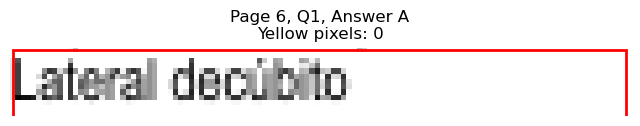

Page 6, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=164.5, y1=127.3
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 481
Page 6, Q1, B: Yellow percentage: 0.0%


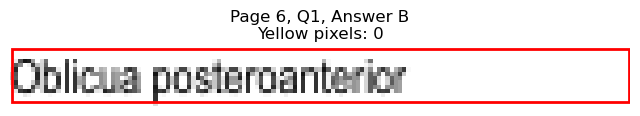

Page 6, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=160.1, y1=139.9
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 436
Page 6, Q1, C: Yellow percentage: 0.0%


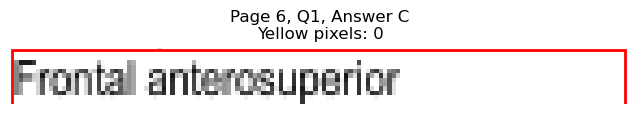

Page 6, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=431.3, y1=114.7
Page 6, Q1, D: Yellow pixels: 1614
Page 6, Q1, D: Total non-white pixels: 2015
Page 6, Q1, D: Yellow percentage: 80.1%


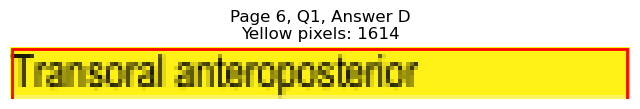

Page 6, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=399.3, y1=127.3
Page 6, Q1, E: Yellow pixels: 123
Page 6, Q1, E: Total non-white pixels: 474
Page 6, Q1, E: Yellow percentage: 25.9%


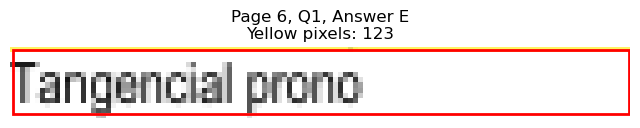


Page 6, Q1 - Selected Answer: D (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=121.9, y1=177.8
Page 6, Q2, A: Yellow pixels: 0
Page 6, Q2, A: Total non-white pixels: 397
Page 6, Q2, A: Yellow percentage: 0.0%


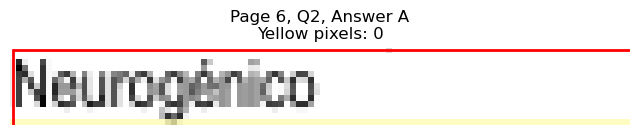

Page 6, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=128.5, y1=190.4
Page 6, Q2, B: Yellow pixels: 1088
Page 6, Q2, B: Total non-white pixels: 1554
Page 6, Q2, B: Yellow percentage: 70.0%


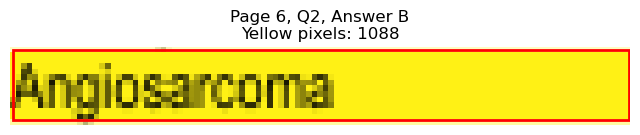

Page 6, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=115.5, y1=203.0
Page 6, Q2, C: Yellow pixels: 2
Page 6, Q2, C: Total non-white pixels: 327
Page 6, Q2, C: Yellow percentage: 0.6%


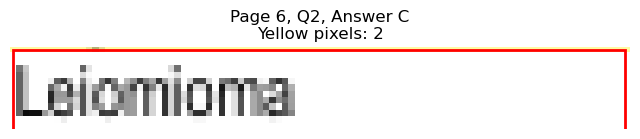

Page 6, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=362.1, y1=177.8
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 146
Page 6, Q2, D: Yellow percentage: 0.0%


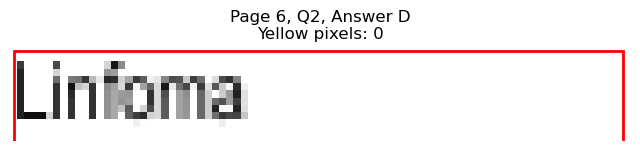

Page 6, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=368.2, y1=190.4
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 202
Page 6, Q2, E: Yellow percentage: 0.0%


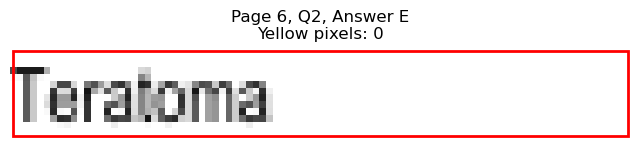


Page 6, Q2 - Selected Answer: B (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=56.6, y0=240.9, x1=65.2, y1=253.5
Page 6, Q3, A: Yellow pixels: 732
Page 6, Q3, A: Total non-white pixels: 840
Page 6, Q3, A: Yellow percentage: 87.1%


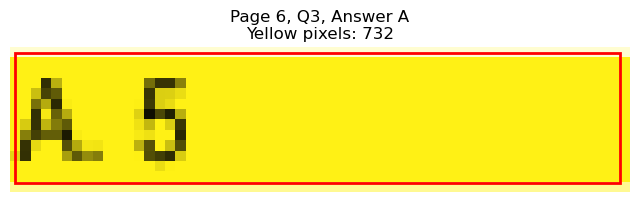

Page 6, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=80.9, y1=266.1
Page 6, Q3, B: Yellow pixels: 63
Page 6, Q3, B: Total non-white pixels: 115
Page 6, Q3, B: Yellow percentage: 54.8%


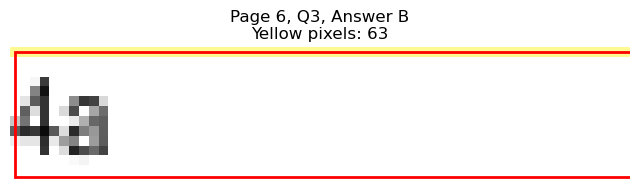

Page 6, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=81.4, y1=278.7
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 59
Page 6, Q3, C: Yellow percentage: 0.0%


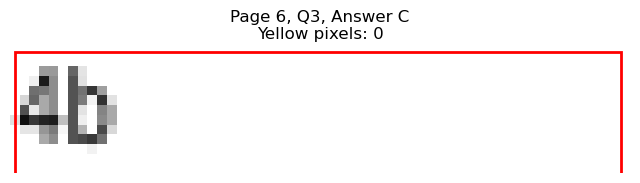

Page 6, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=339.5, y1=253.5
Page 6, Q3, D: Yellow pixels: 0
Page 6, Q3, D: Total non-white pixels: 58
Page 6, Q3, D: Yellow percentage: 0.0%


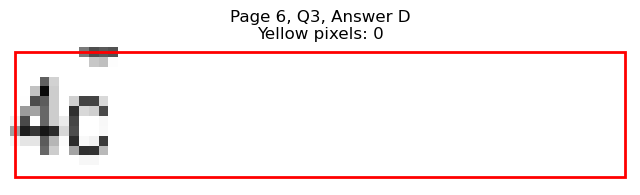

Page 6, Q3 - E: Detected box: x0=315.4, y0=253.5, x1=323.9, y1=266.1
Page 6, Q3, E: Yellow pixels: 0
Page 6, Q3, E: Total non-white pixels: 68
Page 6, Q3, E: Yellow percentage: 0.0%


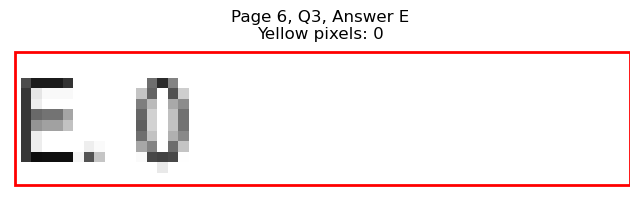


Page 6, Q3 - Selected Answer: A (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=146.5, y1=316.7
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 537
Page 6, Q4, A: Yellow percentage: 0.0%


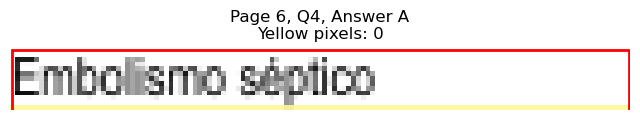

Page 6, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=152.1, y1=329.3
Page 6, Q4, B: Yellow pixels: 1283
Page 6, Q4, B: Total non-white pixels: 1890
Page 6, Q4, B: Yellow percentage: 67.9%


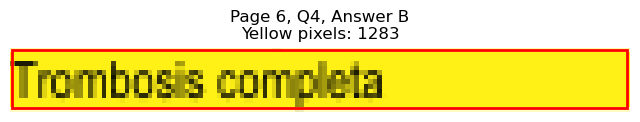

Page 6, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=145.0, y1=341.9
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 509
Page 6, Q4, C: Yellow percentage: 0.0%


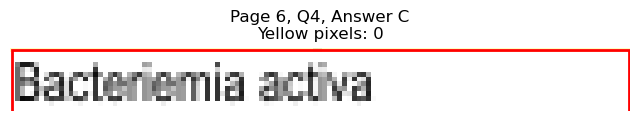

Page 6, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=434.3, y1=316.7
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 599
Page 6, Q4, D: Yellow percentage: 0.0%


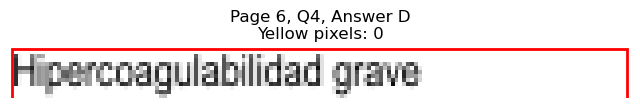

Page 6, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=434.3, y1=329.3
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 548
Page 6, Q4, E: Yellow percentage: 0.0%


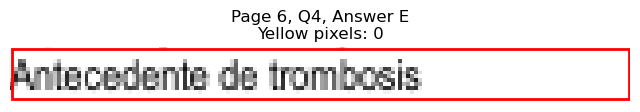


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=103.9, y1=392.4
Page 6, Q5, A: Yellow pixels: 897
Page 6, Q5, A: Total non-white pixels: 1204
Page 6, Q5, A: Yellow percentage: 74.5%


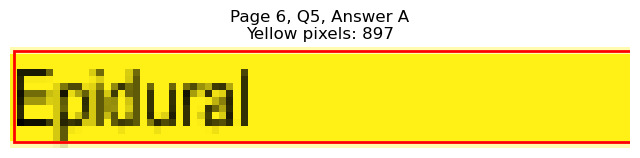

Page 6, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=96.4, y1=405.0
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 227
Page 6, Q5, B: Yellow percentage: 0.0%


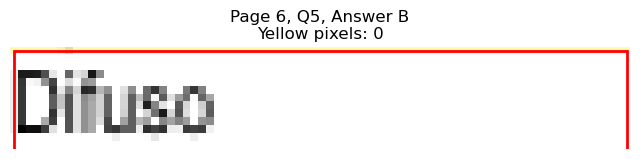

Page 6, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=107.4, y1=417.6
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 208
Page 6, Q5, C: Yellow percentage: 0.0%


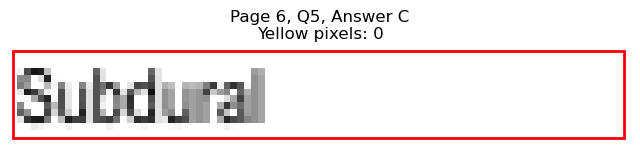

Page 6, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=364.1, y1=392.4
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 194
Page 6, Q5, D: Yellow percentage: 0.0%


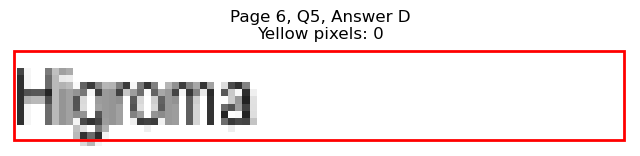

Page 6, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=390.3, y1=405.0
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 337
Page 6, Q5, E: Yellow percentage: 0.0%


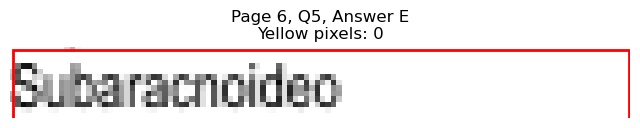


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=83.4, y1=468.1
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 70
Page 6, Q6, A: Yellow percentage: 0.0%


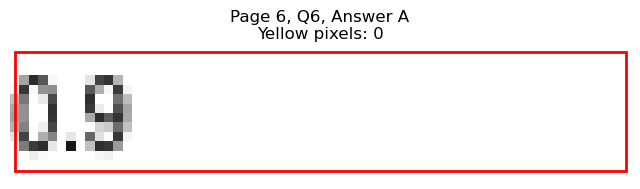

Page 6, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=83.4, y1=480.7
Page 6, Q6, B: Yellow pixels: 0
Page 6, Q6, B: Total non-white pixels: 39
Page 6, Q6, B: Yellow percentage: 0.0%


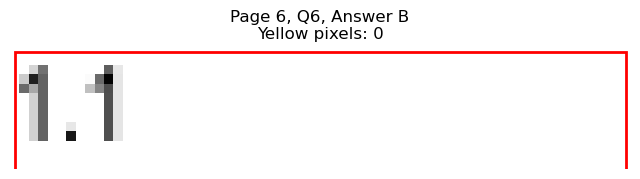

Page 6, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=83.9, y1=493.4
Page 6, Q6, C: Yellow pixels: 750
Page 6, Q6, C: Total non-white pixels: 924
Page 6, Q6, C: Yellow percentage: 81.2%


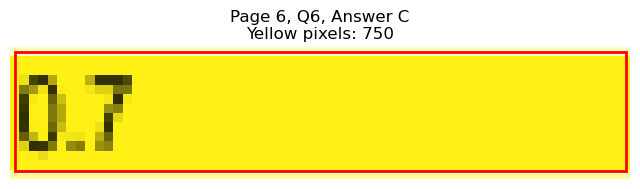

Page 6, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=342.7, y1=468.1
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 47
Page 6, Q6, D: Yellow percentage: 0.0%


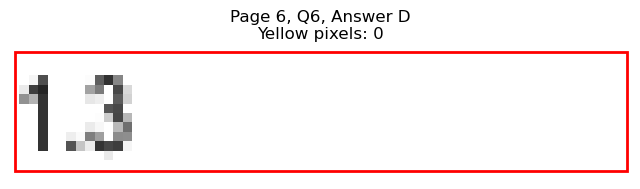

Page 6, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=342.2, y1=480.7
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 55
Page 6, Q6, E: Yellow percentage: 0.0%


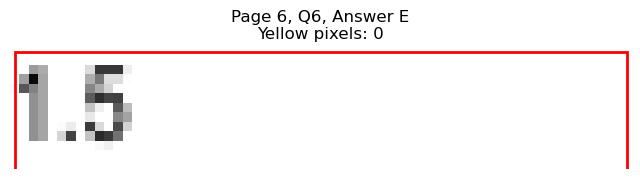


Page 6, Q6 - Selected Answer: C (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=124.0, y1=531.2
Page 6, Q7, A: Yellow pixels: 106
Page 6, Q7, A: Total non-white pixels: 389
Page 6, Q7, A: Yellow percentage: 27.2%


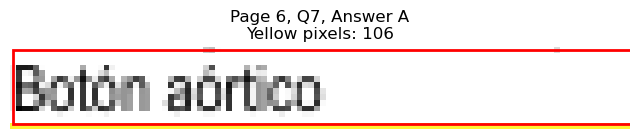

Page 6, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=103.9, y1=543.8
Page 6, Q7, B: Yellow pixels: 993
Page 6, Q7, B: Total non-white pixels: 1118
Page 6, Q7, B: Yellow percentage: 88.8%


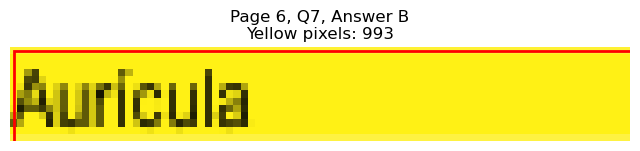

Page 6, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=174.1, y1=556.4
Page 6, Q7, C: Yellow pixels: 157
Page 6, Q7, C: Total non-white pixels: 684
Page 6, Q7, C: Yellow percentage: 23.0%


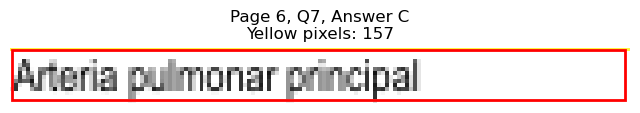

Page 6, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=370.6, y1=531.2
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 208
Page 6, Q7, D: Yellow percentage: 0.0%


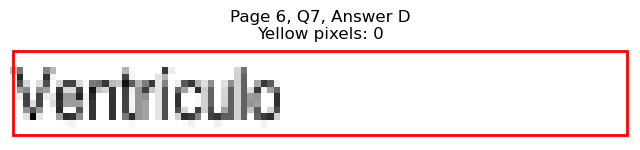

Page 6, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=452.5, y1=543.8
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 609
Page 6, Q7, E: Yellow percentage: 0.0%


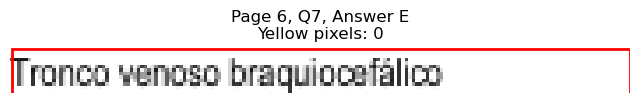


Page 6, Q7 - Selected Answer: B (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=221.8, y1=594.4
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 762
Page 6, Q8, A: Yellow percentage: 0.0%


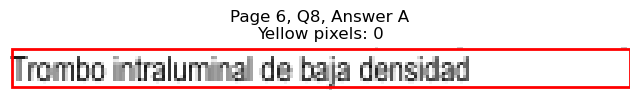

Page 6, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=207.8, y1=607.0
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 686
Page 6, Q8, B: Yellow percentage: 0.0%


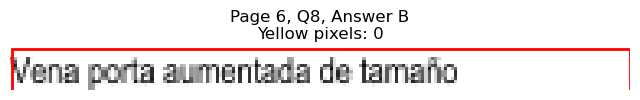

Page 6, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=231.8, y1=619.6
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 776
Page 6, Q8, C: Yellow percentage: 0.0%


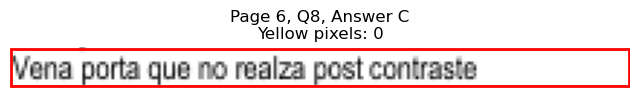

Page 6, Q8 - D: Detected box: x0=327.5, y0=581.7, x1=429.3, y1=594.4
Page 6, Q8, D: Yellow pixels: 1419
Page 6, Q8, D: Total non-white pixels: 2142
Page 6, Q8, D: Yellow percentage: 66.2%


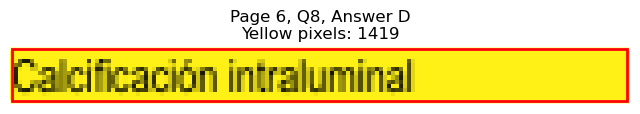

Page 6, Q8 - E: Detected box: x0=327.0, y0=594.3, x1=436.4, y1=607.0
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 683
Page 6, Q8, E: Yellow percentage: 0.0%


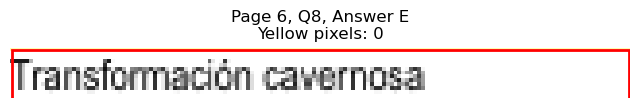


Page 6, Q8 - Selected Answer: D (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=129.5, y1=657.5
Page 6, Q9, A: Yellow pixels: 112
Page 6, Q9, A: Total non-white pixels: 438
Page 6, Q9, A: Yellow percentage: 25.6%


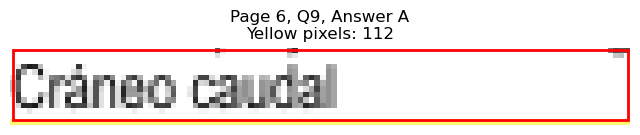

Page 6, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=115.0, y1=670.1
Page 6, Q9, B: Yellow pixels: 1076
Page 6, Q9, B: Total non-white pixels: 1358
Page 6, Q9, B: Yellow percentage: 79.2%


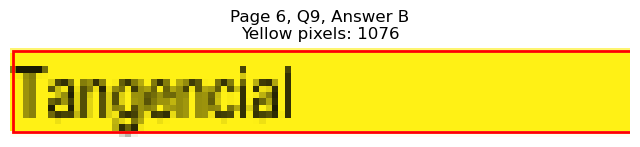

Page 6, Q9 - C: Detected box: x0=68.8, y0=670.1, x1=156.0, y1=682.7
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 568
Page 6, Q9, C: Yellow percentage: 0.0%


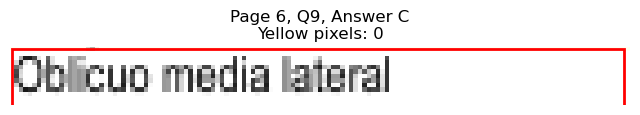

Page 6, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=389.2, y1=657.5
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 298
Page 6, Q9, D: Yellow percentage: 0.0%


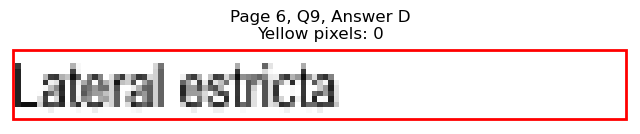

Page 6, Q9 - E: Detected box: x0=327.0, y0=657.5, x1=388.3, y1=670.1
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 286
Page 6, Q9, E: Yellow percentage: 0.0%


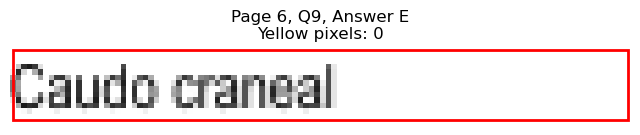


Page 6, Q9 - Selected Answer: B (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=720.6, x1=139.6, y1=733.2
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 357
Page 6, Q10, A: Yellow percentage: 0.0%


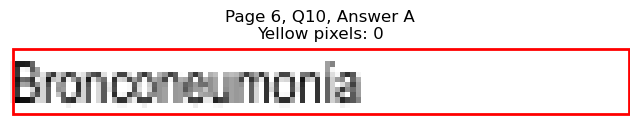

Page 6, Q10 - B: Detected box: x0=68.3, y0=733.2, x1=111.4, y1=745.8
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 321
Page 6, Q10, B: Yellow percentage: 0.0%


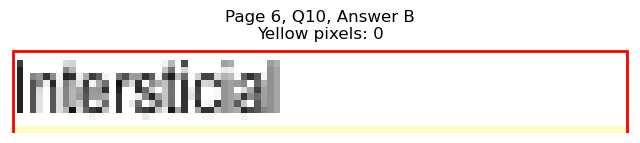

Page 6, Q10 - C: Detected box: x0=68.8, y0=745.8, x1=94.3, y1=758.4
Page 6, Q10, C: Yellow pixels: 903
Page 6, Q10, C: Total non-white pixels: 1078
Page 6, Q10, C: Yellow percentage: 83.8%


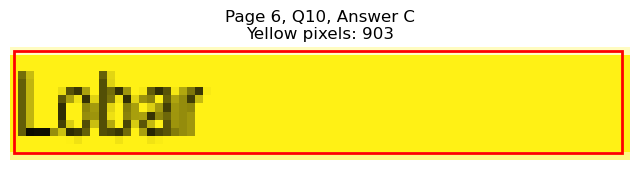

Page 6, Q10 - D: Detected box: x0=327.5, y0=720.6, x1=369.2, y1=733.2
Page 6, Q10, D: Yellow pixels: 0
Page 6, Q10, D: Total non-white pixels: 224
Page 6, Q10, D: Yellow percentage: 0.0%


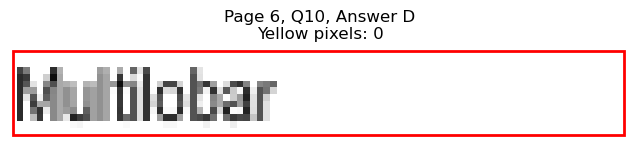

Page 6, Q10 - E: Detected box: x0=327.0, y0=733.2, x1=362.8, y1=745.8
Page 6, Q10, E: Yellow pixels: 0
Page 6, Q10, E: Total non-white pixels: 193
Page 6, Q10, E: Yellow percentage: 0.0%


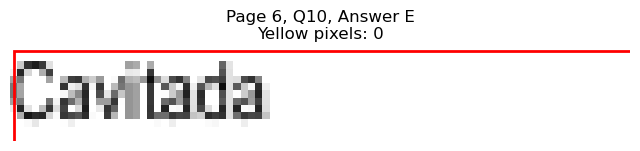


Page 6, Q10 - Selected Answer: C (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=119.9, y1=114.7
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 289
Page 7, Q1, A: Yellow percentage: 0.0%


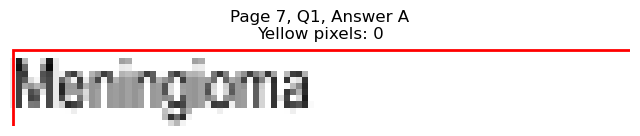

Page 7, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=153.5, y1=127.3
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 436
Page 7, Q1, B: Yellow percentage: 0.0%


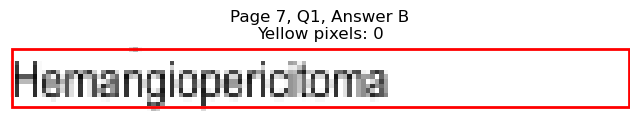

Page 7, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=103.3, y1=139.9
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 173
Page 7, Q1, C: Yellow percentage: 0.0%


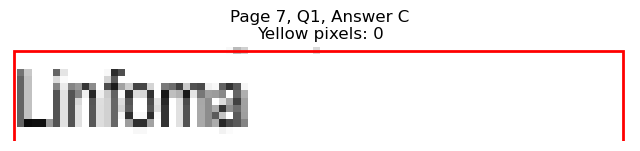

Page 7, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=434.8, y1=114.7
Page 7, Q1, D: Yellow pixels: 1665
Page 7, Q1, D: Total non-white pixels: 2054
Page 7, Q1, D: Yellow percentage: 81.1%


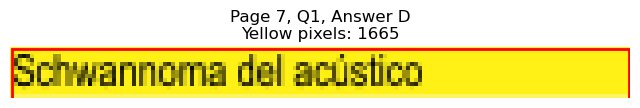

Page 7, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=390.3, y1=127.3
Page 7, Q1, E: Yellow pixels: 114
Page 7, Q1, E: Total non-white pixels: 468
Page 7, Q1, E: Yellow percentage: 24.4%


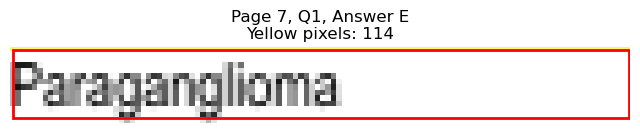


Page 7, Q1 - Selected Answer: D (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=166.6, y1=190.4
Page 7, Q2, A: Yellow pixels: 1372
Page 7, Q2, A: Total non-white pixels: 2086
Page 7, Q2, A: Yellow percentage: 65.8%


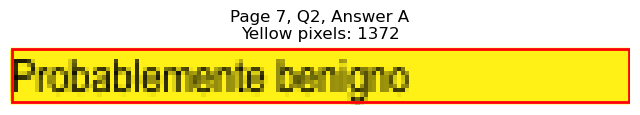

Page 7, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=106.5, y1=203.0
Page 7, Q2, B: Yellow pixels: 2
Page 7, Q2, B: Total non-white pixels: 294
Page 7, Q2, B: Yellow percentage: 0.7%


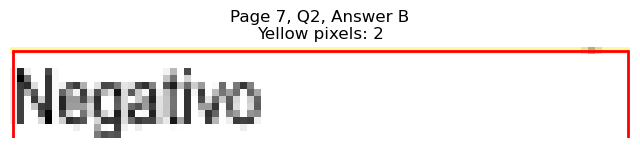

Page 7, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=104.4, y1=215.6
Page 7, Q2, C: Yellow pixels: 0
Page 7, Q2, C: Total non-white pixels: 203
Page 7, Q2, C: Yellow percentage: 0.0%


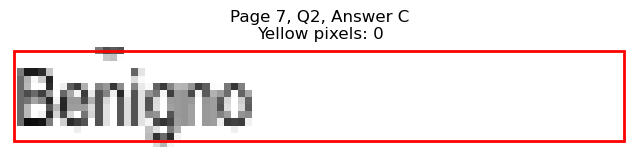

Page 7, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=438.4, y1=190.4
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 594
Page 7, Q2, D: Yellow percentage: 0.0%


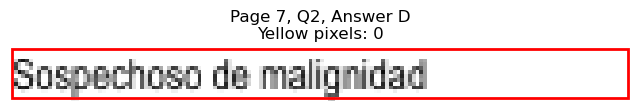

Page 7, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=471.6, y1=203.0
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 773
Page 7, Q2, E: Yellow percentage: 0.0%


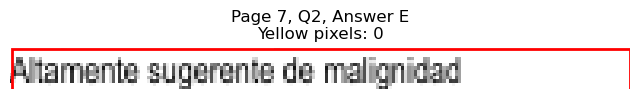


Page 7, Q2 - Selected Answer: A (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=132.0, y1=253.5
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 337
Page 7, Q3, A: Yellow percentage: 0.0%


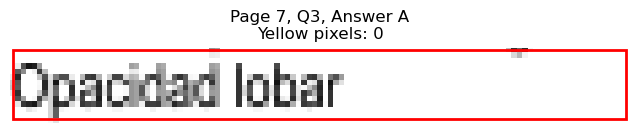

Page 7, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=183.1, y1=266.1
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 640
Page 7, Q3, B: Yellow percentage: 0.0%


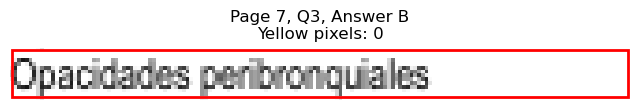

Page 7, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=115.5, y1=278.7
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 269
Page 7, Q3, C: Yellow percentage: 0.0%


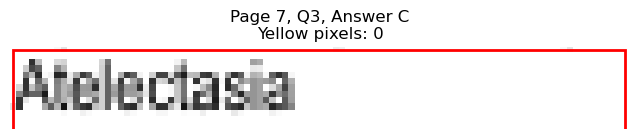

Page 7, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=434.3, y1=253.5
Page 7, Q3, D: Yellow pixels: 158
Page 7, Q3, D: Total non-white pixels: 735
Page 7, Q3, D: Yellow percentage: 21.5%


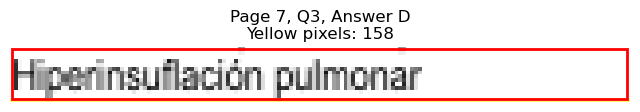

Page 7, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=464.0, y1=266.1
Page 7, Q3, E: Yellow pixels: 1883
Page 7, Q3, E: Total non-white pixels: 2618
Page 7, Q3, E: Yellow percentage: 71.9%


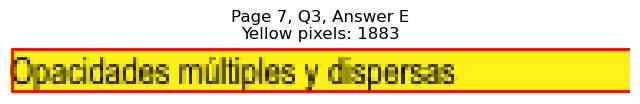


Page 7, Q3 - Selected Answer: E (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=92.9, y1=329.3
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 103
Page 7, Q4, A: Yellow percentage: 0.0%


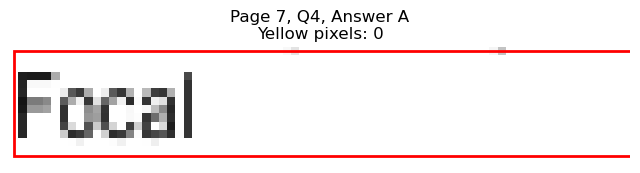

Page 7, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=143.5, y1=341.9
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 391
Page 7, Q4, B: Yellow percentage: 0.0%


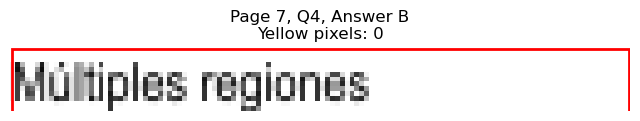

Page 7, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=96.9, y1=354.6
Page 7, Q4, C: Yellow pixels: 922
Page 7, Q4, C: Total non-white pixels: 1106
Page 7, Q4, C: Yellow percentage: 83.4%


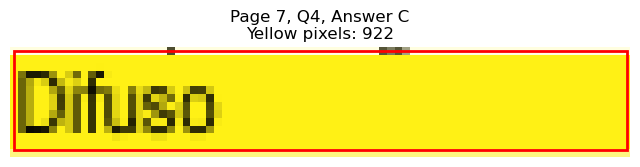

Page 7, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=365.7, y1=329.3
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 218
Page 7, Q4, D: Yellow percentage: 0.0%


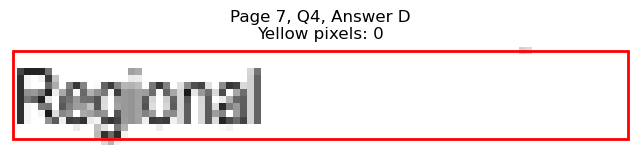

Page 7, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=380.7, y1=341.9
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 290
Page 7, Q4, E: Yellow percentage: 0.0%


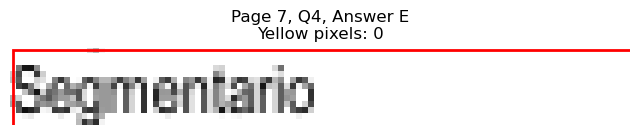


Page 7, Q4 - Selected Answer: C (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=144.0, y1=405.0
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 379
Page 7, Q5, A: Yellow percentage: 0.0%


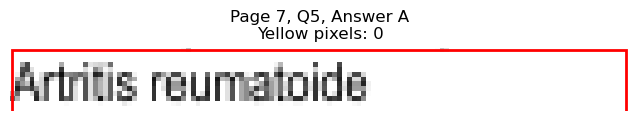

Page 7, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=164.1, y1=417.6
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 450
Page 7, Q5, B: Yellow percentage: 0.0%


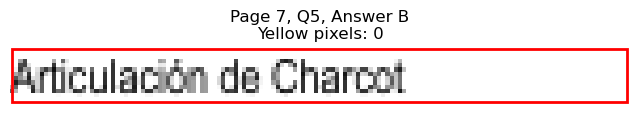

Page 7, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=119.9, y1=430.3
Page 7, Q5, C: Yellow pixels: 1012
Page 7, Q5, C: Total non-white pixels: 1428
Page 7, Q5, C: Yellow percentage: 70.9%


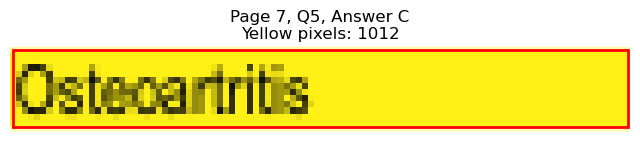

Page 7, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=417.8, y1=405.0
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 459
Page 7, Q5, D: Yellow percentage: 0.0%


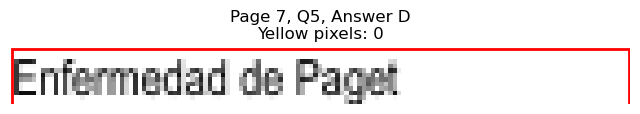

Page 7, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=483.6, y1=417.6
Page 7, Q5, E: Yellow pixels: 0
Page 7, Q5, E: Total non-white pixels: 806
Page 7, Q5, E: Yellow percentage: 0.0%


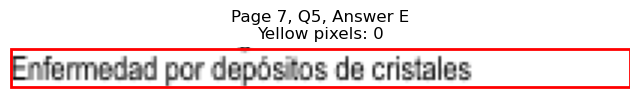


Page 7, Q5 - Selected Answer: C (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=112.9, y1=480.7
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 219
Page 7, Q6, A: Yellow percentage: 0.0%


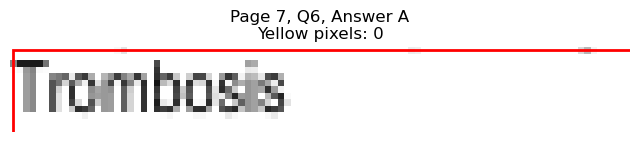

Page 7, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=138.0, y1=493.4
Page 7, Q6, B: Yellow pixels: 1196
Page 7, Q6, B: Total non-white pixels: 1694
Page 7, Q6, B: Yellow percentage: 70.6%


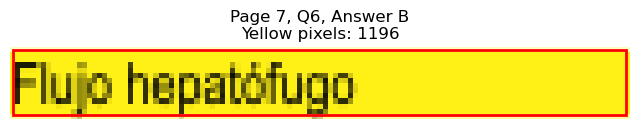

Page 7, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=138.5, y1=506.0
Page 7, Q6, C: Yellow pixels: 3
Page 7, Q6, C: Total non-white pixels: 505
Page 7, Q6, C: Yellow percentage: 0.6%


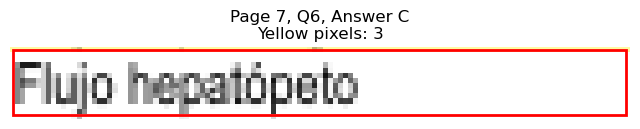

Page 7, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=402.3, y1=480.7
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 402
Page 7, Q6, D: Yellow percentage: 0.0%


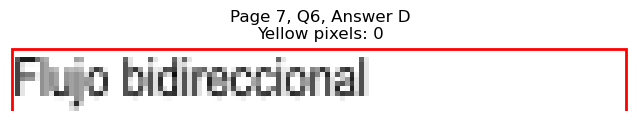

Page 7, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=385.3, y1=493.4
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 307
Page 7, Q6, E: Yellow percentage: 0.0%


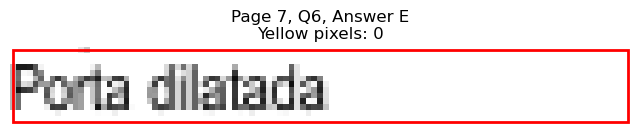


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=180.1, y1=543.8
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 739
Page 7, Q7, A: Yellow percentage: 0.0%


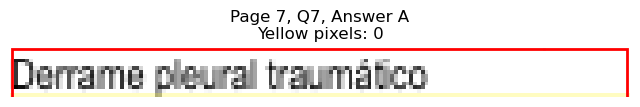

Page 7, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=169.6, y1=556.4
Page 7, Q7, B: Yellow pixels: 1535
Page 7, Q7, B: Total non-white pixels: 2128
Page 7, Q7, B: Yellow percentage: 72.1%


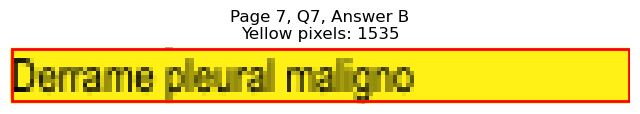

Page 7, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=151.6, y1=569.2
Page 7, Q7, C: Yellow pixels: 133
Page 7, Q7, C: Total non-white pixels: 564
Page 7, Q7, C: Yellow percentage: 23.6%


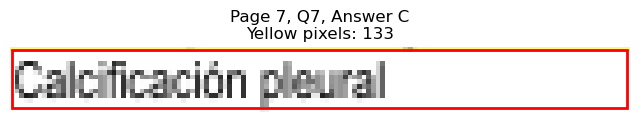

Page 7, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=371.2, y1=543.8
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 223
Page 7, Q7, D: Yellow percentage: 0.0%


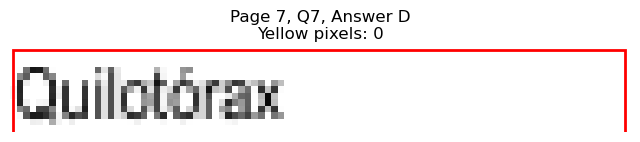

Page 7, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=421.9, y1=556.4
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 449
Page 7, Q7, E: Yellow percentage: 0.0%


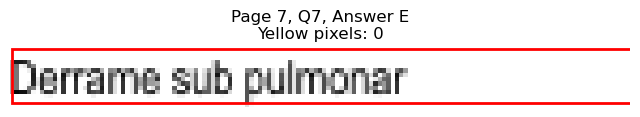


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=196.2, y1=607.0
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 642
Page 7, Q8, A: Yellow percentage: 0.0%


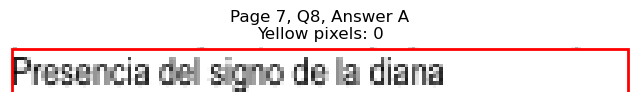

Page 7, Q8 - B: Detected box: x0=68.3, y0=606.9, x1=176.2, y1=619.6
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 536
Page 7, Q8, B: Yellow percentage: 0.0%


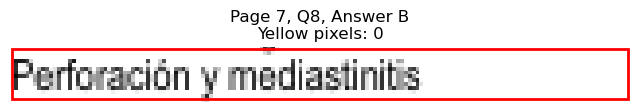

Page 7, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=112.4, y1=632.3
Page 7, Q8, C: Yellow pixels: 959
Page 7, Q8, C: Total non-white pixels: 1330
Page 7, Q8, C: Yellow percentage: 72.1%


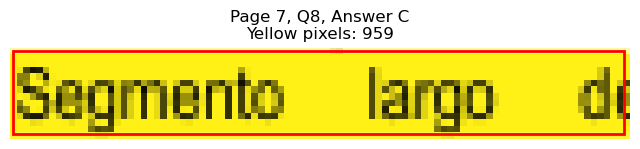

Page 7, Q8 - D: Detected box: x0=327.5, y0=594.3, x1=403.3, y1=607.0
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 397
Page 7, Q8, D: Yellow percentage: 0.0%


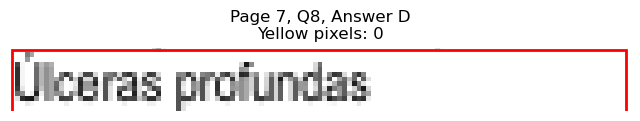

Page 7, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=541.0, y1=619.6
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 1002
Page 7, Q8, E: Yellow percentage: 0.0%


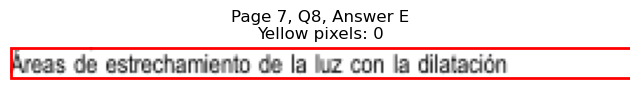


Page 7, Q8 - Selected Answer: C (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=213.3, y1=695.3
Page 7, Q9, A: Yellow pixels: 0
Page 7, Q9, A: Total non-white pixels: 728
Page 7, Q9, A: Yellow percentage: 0.0%


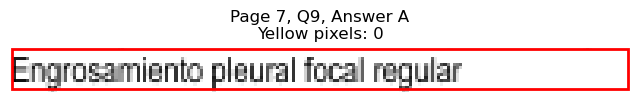

Page 7, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=151.1, y1=708.0
Page 7, Q9, B: Yellow pixels: 0
Page 7, Q9, B: Total non-white pixels: 411
Page 7, Q9, B: Yellow percentage: 0.0%


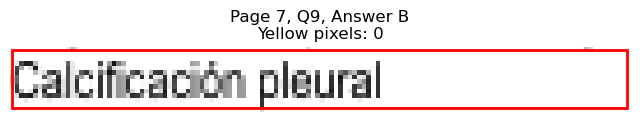

Page 7, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=188.2, y1=720.6
Page 7, Q9, C: Yellow pixels: 0
Page 7, Q9, C: Total non-white pixels: 627
Page 7, Q9, C: Yellow percentage: 0.0%


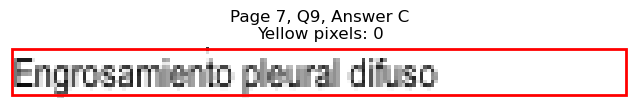

Page 7, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=443.3, y1=695.3
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 605
Page 7, Q9, D: Yellow percentage: 0.0%


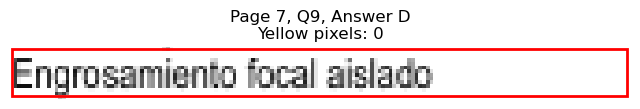

Page 7, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=488.1, y1=708.0
Page 7, Q9, E: Yellow pixels: 2109
Page 7, Q9, E: Total non-white pixels: 2764
Page 7, Q9, E: Yellow percentage: 76.3%


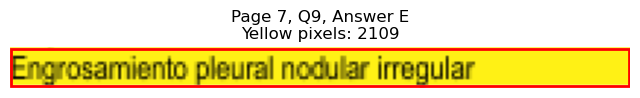


Page 7, Q9 - Selected Answer: E (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=56.6, y0=114.6, x1=65.2, y1=127.3
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 44
Page 8, Q1, A: Yellow percentage: 0.0%


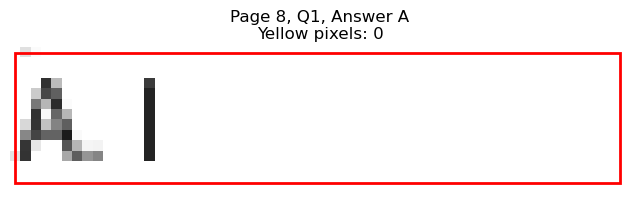

Page 8, Q1 - B: Detected box: x0=56.6, y0=127.2, x1=65.2, y1=139.9
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 66
Page 8, Q1, B: Yellow percentage: 0.0%


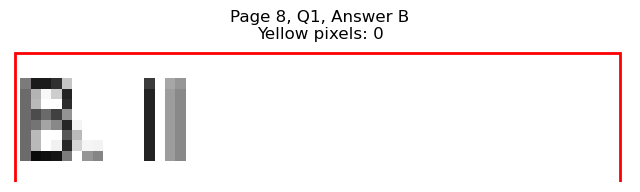

Page 8, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=79.8, y1=152.6
Page 8, Q1, C: Yellow pixels: 0
Page 8, Q1, C: Total non-white pixels: 44
Page 8, Q1, C: Yellow percentage: 0.0%


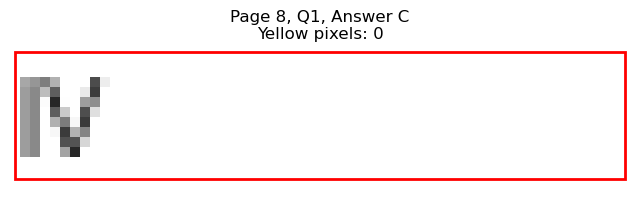

Page 8, Q1 - D: Detected box: x0=315.4, y0=114.6, x1=324.4, y1=127.3
Page 8, Q1, D: Yellow pixels: 60
Page 8, Q1, D: Total non-white pixels: 129
Page 8, Q1, D: Yellow percentage: 46.5%


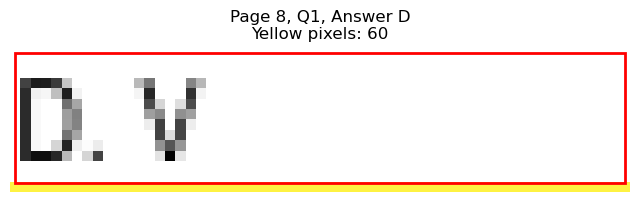

Page 8, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=337.1, y1=139.9
Page 8, Q1, E: Yellow pixels: 761
Page 8, Q1, E: Total non-white pixels: 793
Page 8, Q1, E: Yellow percentage: 96.0%


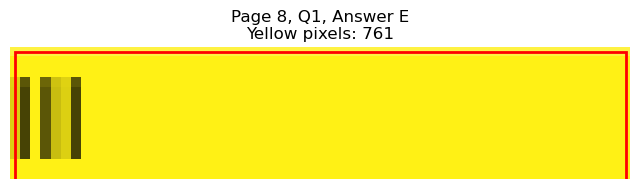


Page 8, Q1 - Selected Answer: E (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=118.5, y1=203.0
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 258
Page 8, Q2, A: Yellow percentage: 0.0%


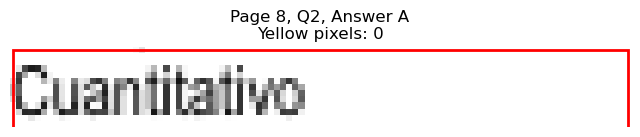

Page 8, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=137.1, y1=215.6
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 361
Page 8, Q2, B: Yellow percentage: 0.0%


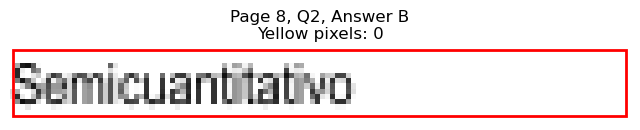

Page 8, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=113.4, y1=228.3
Page 8, Q2, C: Yellow pixels: 969
Page 8, Q2, C: Total non-white pixels: 1344
Page 8, Q2, C: Yellow percentage: 72.1%


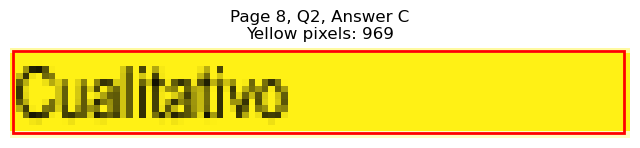

Page 8, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=368.7, y1=203.0
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 201
Page 8, Q2, D: Yellow percentage: 0.0%


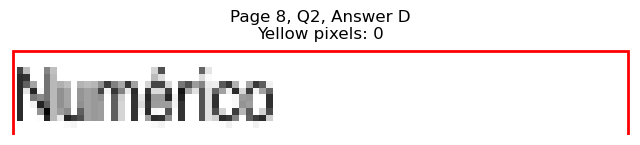

Page 8, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=387.8, y1=215.6
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 310
Page 8, Q2, E: Yellow percentage: 0.0%


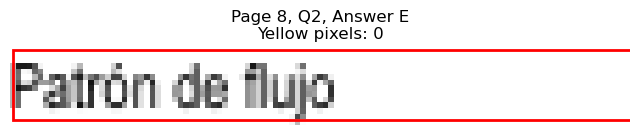


Page 8, Q2 - Selected Answer: C (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=137.1, y1=278.7
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 354
Page 8, Q3, A: Yellow percentage: 0.0%


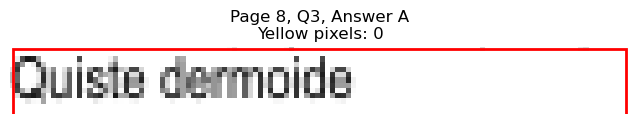

Page 8, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=128.5, y1=291.5
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 333
Page 8, Q3, B: Yellow percentage: 0.0%


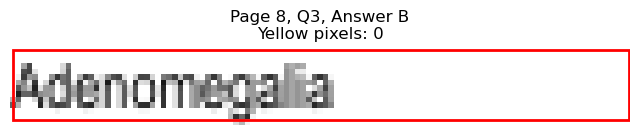

Page 8, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=100.9, y1=304.1
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 155
Page 8, Q3, C: Yellow percentage: 0.0%


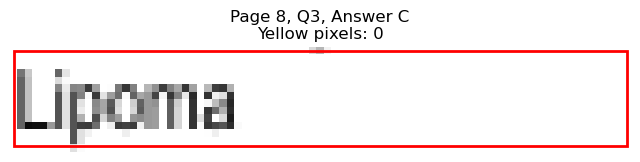

Page 8, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=392.7, y1=278.7
Page 8, Q3, D: Yellow pixels: 1275
Page 8, Q3, D: Total non-white pixels: 1508
Page 8, Q3, D: Yellow percentage: 84.5%


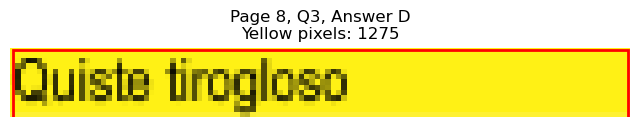

Page 8, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=352.1, y1=291.5
Page 8, Q3, E: Yellow pixels: 74
Page 8, Q3, E: Total non-white pixels: 204
Page 8, Q3, E: Yellow percentage: 36.3%


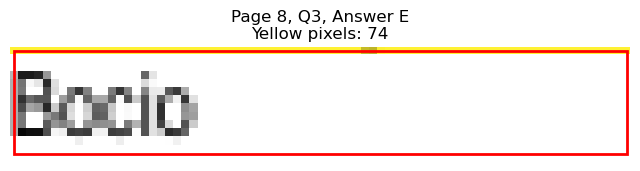


Page 8, Q3 - Selected Answer: D (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=124.9, y1=354.6
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 293
Page 8, Q4, A: Yellow percentage: 0.0%


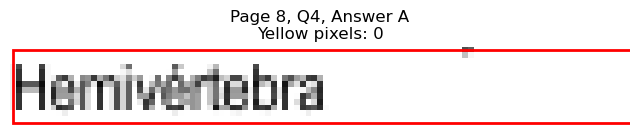

Page 8, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=157.6, y1=367.2
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 414
Page 8, Q4, B: Yellow percentage: 0.0%


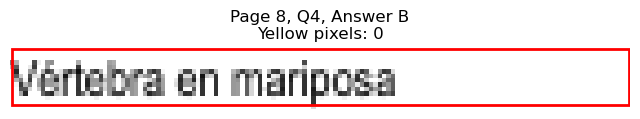

Page 8, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=112.5, y1=379.8
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 233
Page 8, Q4, C: Yellow percentage: 0.0%


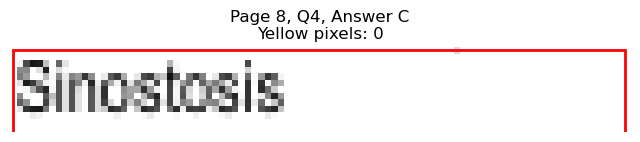

Page 8, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=408.8, y1=354.6
Page 8, Q4, D: Yellow pixels: 1402
Page 8, Q4, D: Total non-white pixels: 1848
Page 8, Q4, D: Yellow percentage: 75.9%


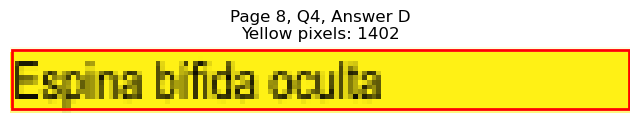

Page 8, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=421.4, y1=367.2
Page 8, Q4, E: Yellow pixels: 145
Page 8, Q4, E: Total non-white pixels: 585
Page 8, Q4, E: Yellow percentage: 24.8%


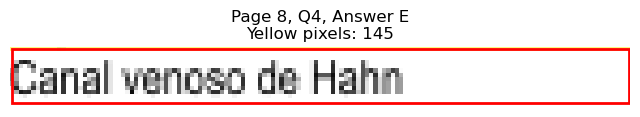


Page 8, Q4 - Selected Answer: D (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=163.1, y1=430.3
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 446
Page 8, Q5, A: Yellow percentage: 0.0%


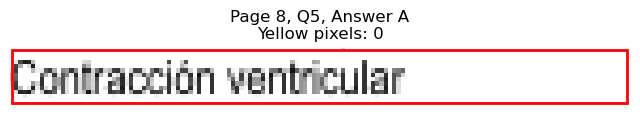

Page 8, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=157.1, y1=442.9
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 454
Page 8, Q5, B: Yellow percentage: 0.0%


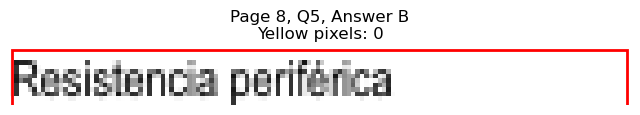

Page 8, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=156.5, y1=455.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 427
Page 8, Q5, C: Yellow percentage: 0.0%


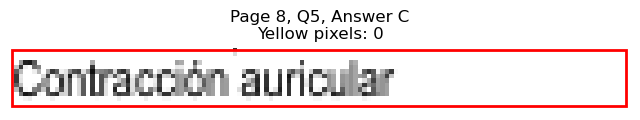

Page 8, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=406.3, y1=430.3
Page 8, Q5, D: Yellow pixels: 130
Page 8, Q5, D: Total non-white pixels: 529
Page 8, Q5, D: Yellow percentage: 24.6%


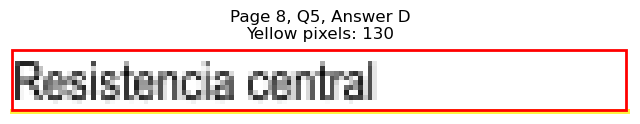

Page 8, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=403.7, y1=442.9
Page 8, Q5, E: Yellow pixels: 1351
Page 8, Q5, E: Total non-white pixels: 1651
Page 8, Q5, E: Yellow percentage: 81.8%


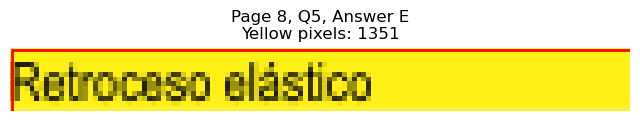


Page 8, Q5 - Selected Answer: E (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=221.3, y1=493.4
Page 8, Q6, A: Yellow pixels: 1886
Page 8, Q6, A: Total non-white pixels: 2856
Page 8, Q6, A: Yellow percentage: 66.0%


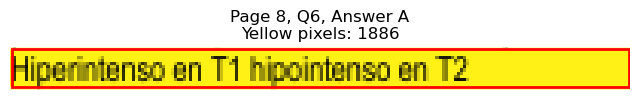

Page 8, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=247.5, y1=506.0
Page 8, Q6, B: Yellow pixels: 2
Page 8, Q6, B: Total non-white pixels: 1056
Page 8, Q6, B: Yellow percentage: 0.2%


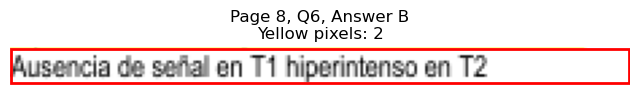

Page 8, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=221.8, y1=518.6
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 706
Page 8, Q6, C: Yellow percentage: 0.0%


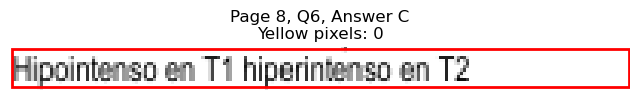

Page 8, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=507.2, y1=493.4
Page 8, Q6, D: Yellow pixels: 0
Page 8, Q6, D: Total non-white pixels: 856
Page 8, Q6, D: Yellow percentage: 0.0%


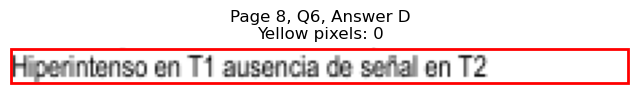

Page 8, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=503.1, y1=506.0
Page 8, Q6, E: Yellow pixels: 0
Page 8, Q6, E: Total non-white pixels: 838
Page 8, Q6, E: Yellow percentage: 0.0%


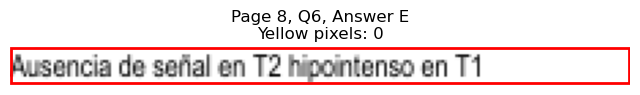


Page 8, Q6 - Selected Answer: A (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=124.0, y1=556.4
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 278
Page 8, Q7, A: Yellow percentage: 0.0%


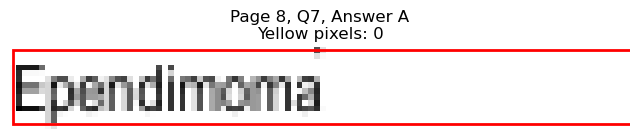

Page 8, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=120.0, y1=569.2
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 291
Page 8, Q7, B: Yellow percentage: 0.0%


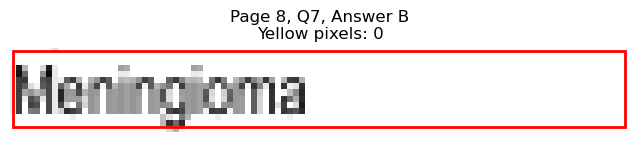

Page 8, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=147.1, y1=581.8
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 452
Page 8, Q7, C: Yellow percentage: 0.0%


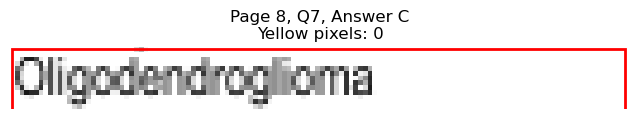

Page 8, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=404.8, y1=556.4
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 415
Page 8, Q7, D: Yellow percentage: 0.0%


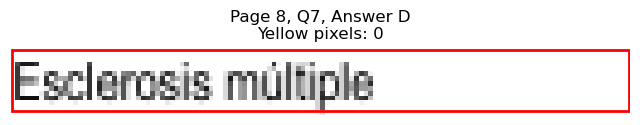

Page 8, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=426.9, y1=569.2
Page 8, Q7, E: Yellow pixels: 1533
Page 8, Q7, E: Total non-white pixels: 2100
Page 8, Q7, E: Yellow percentage: 73.0%


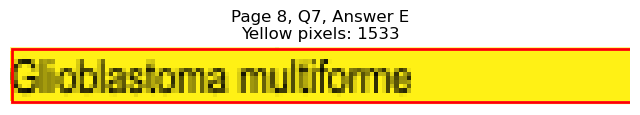


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=123.5, y1=619.6
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 285
Page 8, Q8, A: Yellow percentage: 0.0%


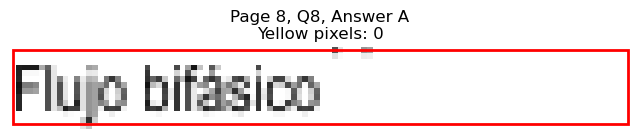

Page 8, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=164.1, y1=632.3
Page 8, Q8, B: Yellow pixels: 147
Page 8, Q8, B: Total non-white pixels: 616
Page 8, Q8, B: Yellow percentage: 23.9%


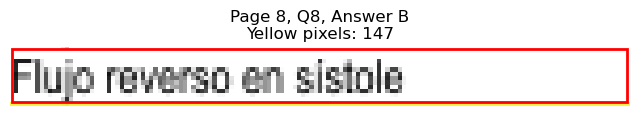

Page 8, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=188.7, y1=644.9
Page 8, Q8, C: Yellow pixels: 1746
Page 8, Q8, C: Total non-white pixels: 2223
Page 8, Q8, C: Yellow percentage: 78.5%


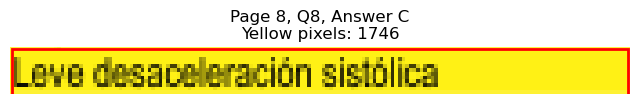

Page 8, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=428.3, y1=619.6
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 514
Page 8, Q8, D: Yellow percentage: 0.0%


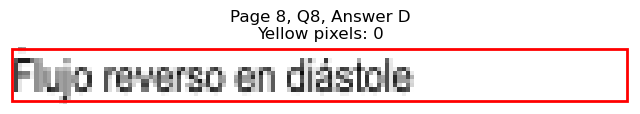

Page 8, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=397.7, y1=632.3
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 336
Page 8, Q8, E: Yellow percentage: 0.0%


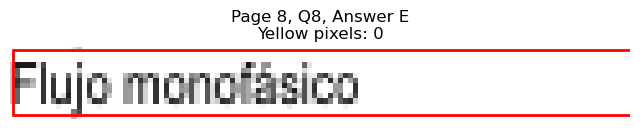


Page 8, Q8 - Selected Answer: C (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=682.7, x1=121.9, y1=695.3
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 267
Page 8, Q9, A: Yellow percentage: 0.0%


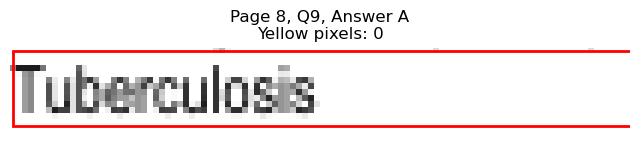

Page 8, Q9 - B: Detected box: x0=68.3, y0=695.4, x1=173.7, y1=708.0
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 559
Page 8, Q9, B: Yellow percentage: 0.0%


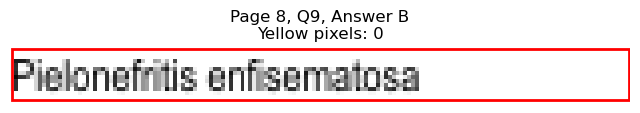

Page 8, Q9 - C: Detected box: x0=68.8, y0=708.0, x1=99.4, y1=720.6
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 171
Page 8, Q9, C: Yellow percentage: 0.0%


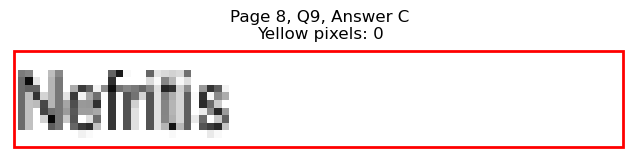

Page 8, Q9 - D: Detected box: x0=327.5, y0=682.7, x1=374.7, y1=695.3
Page 8, Q9, D: Yellow pixels: 1001
Page 8, Q9, D: Total non-white pixels: 1372
Page 8, Q9, D: Yellow percentage: 73.0%


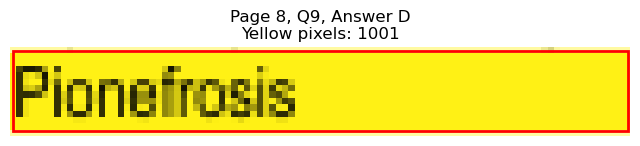

Page 8, Q9 - E: Detected box: x0=327.0, y0=695.4, x1=401.4, y1=708.0
Page 8, Q9, E: Yellow pixels: 0
Page 8, Q9, E: Total non-white pixels: 548
Page 8, Q9, E: Yellow percentage: 0.0%


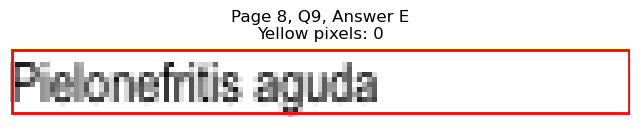


Page 8, Q9 - Selected Answer: D (based on yellow pixel count)





Page 9: Found 9 questions
Page 9, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=132.0, y1=102.1
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 327
Page 9, Q1, A: Yellow percentage: 0.0%


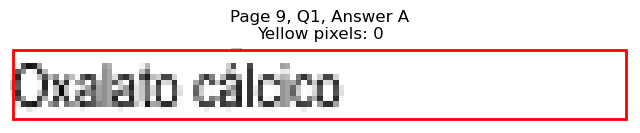

Page 9, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=98.4, y1=114.7
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 241
Page 9, Q1, B: Yellow percentage: 0.0%


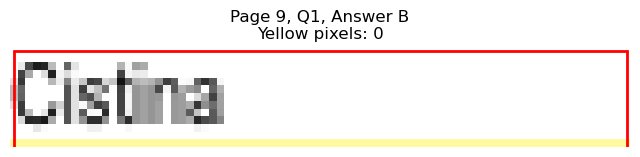

Page 9, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=115.9, y1=127.3
Page 9, Q1, C: Yellow pixels: 995
Page 9, Q1, C: Total non-white pixels: 1372
Page 9, Q1, C: Yellow percentage: 72.5%


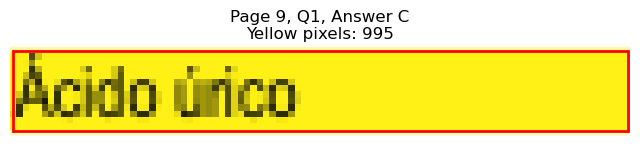

Page 9, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=390.2, y1=102.1
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 314
Page 9, Q1, D: Yellow percentage: 0.0%


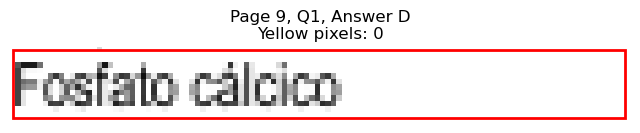

Page 9, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=364.6, y1=114.7
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 202
Page 9, Q1, E: Yellow percentage: 0.0%


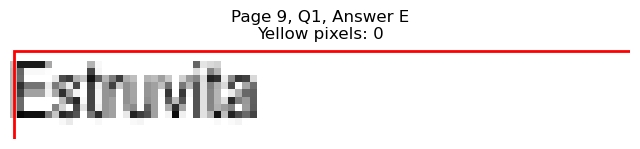


Page 9, Q1 - Selected Answer: C (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=118.0, y1=165.2
Page 9, Q2, A: Yellow pixels: 100
Page 9, Q2, A: Total non-white pixels: 335
Page 9, Q2, A: Yellow percentage: 29.9%


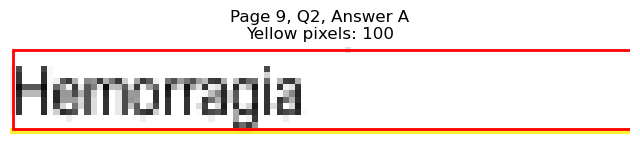

Page 9, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=119.9, y1=177.8
Page 9, Q2, B: Yellow pixels: 1132
Page 9, Q2, B: Total non-white pixels: 1326
Page 9, Q2, B: Yellow percentage: 85.4%


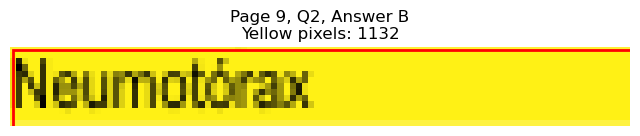

Page 9, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=107.4, y1=190.4
Page 9, Q2, C: Yellow pixels: 90
Page 9, Q2, C: Total non-white pixels: 289
Page 9, Q2, C: Yellow percentage: 31.1%


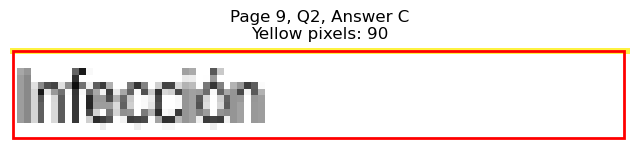

Page 9, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=391.3, y1=165.2
Page 9, Q2, D: Yellow pixels: 0
Page 9, Q2, D: Total non-white pixels: 337
Page 9, Q2, D: Yellow percentage: 0.0%


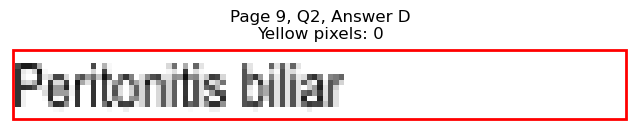

Page 9, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=426.9, y1=177.8
Page 9, Q2, E: Yellow pixels: 0
Page 9, Q2, E: Total non-white pixels: 529
Page 9, Q2, E: Yellow percentage: 0.0%


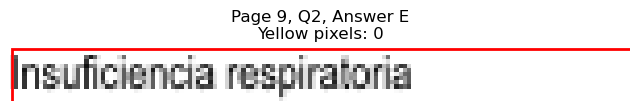


Page 9, Q2 - Selected Answer: B (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=96.4, y1=253.5
Page 9, Q3, A: Yellow pixels: 79
Page 9, Q3, A: Total non-white pixels: 237
Page 9, Q3, A: Yellow percentage: 33.3%


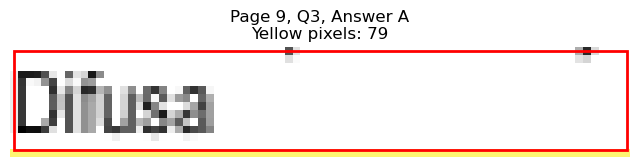

Page 9, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=92.9, y1=266.1
Page 9, Q3, B: Yellow pixels: 895
Page 9, Q3, B: Total non-white pixels: 1050
Page 9, Q3, B: Yellow percentage: 85.2%


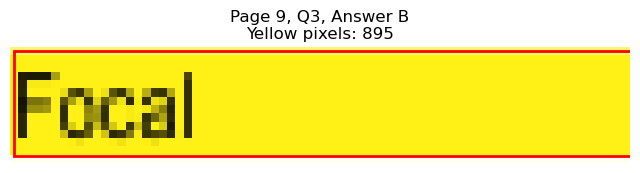

Page 9, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=109.5, y1=278.7
Page 9, Q3, C: Yellow pixels: 0
Page 9, Q3, C: Total non-white pixels: 325
Page 9, Q3, C: Yellow percentage: 0.0%


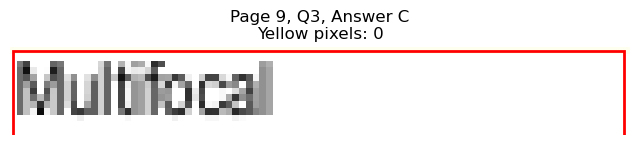

Page 9, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=406.7, y1=253.5
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 403
Page 9, Q3, D: Yellow percentage: 0.0%


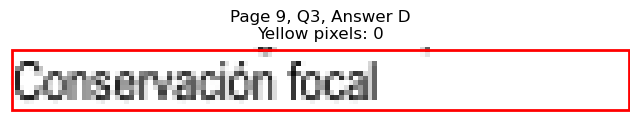

Page 9, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=364.7, y1=266.1
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 207
Page 9, Q3, E: Yellow percentage: 0.0%


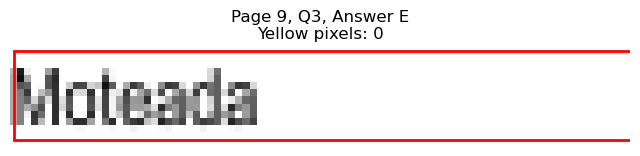


Page 9, Q3 - Selected Answer: B (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=167.7, y1=316.7
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 471
Page 9, Q4, A: Yellow percentage: 0.0%


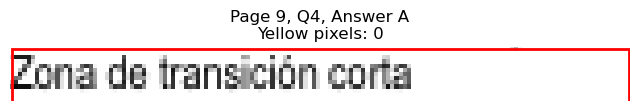

Page 9, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=136.0, y1=329.3
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 352
Page 9, Q4, B: Yellow percentage: 0.0%


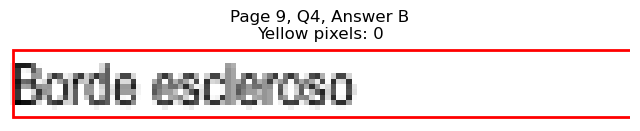

Page 9, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=130.9, y1=341.9
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 308
Page 9, Q4, C: Yellow percentage: 0.0%


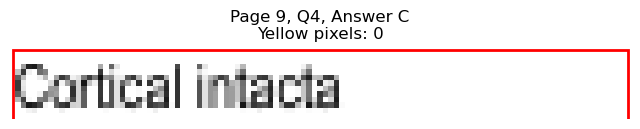

Page 9, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=470.5, y1=316.7
Page 9, Q4, D: Yellow pixels: 1
Page 9, Q4, D: Total non-white pixels: 915
Page 9, Q4, D: Yellow percentage: 0.1%


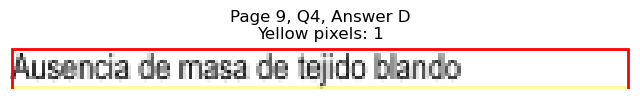

Page 9, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=403.3, y1=329.3
Page 9, Q4, E: Yellow pixels: 1212
Page 9, Q4, E: Total non-white pixels: 1778
Page 9, Q4, E: Yellow percentage: 68.2%


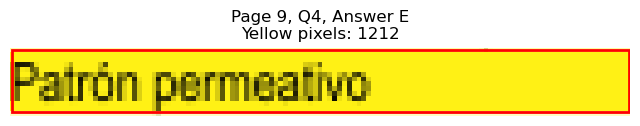


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=150.5, y1=392.4
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 402
Page 9, Q5, A: Yellow percentage: 0.0%


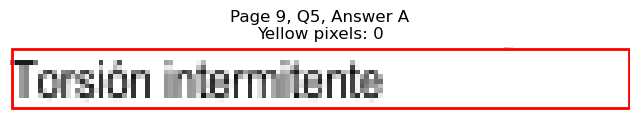

Page 9, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=135.0, y1=405.0
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 321
Page 9, Q5, B: Yellow percentage: 0.0%


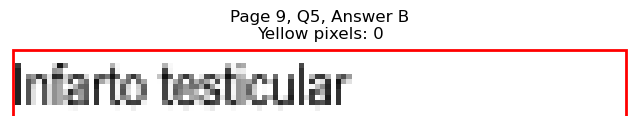

Page 9, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=138.0, y1=417.6
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 399
Page 9, Q5, C: Yellow percentage: 0.0%


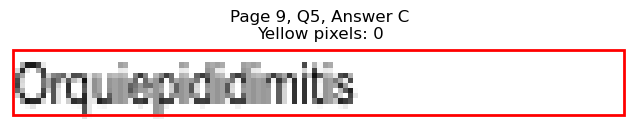

Page 9, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=406.3, y1=392.4
Page 9, Q5, D: Yellow pixels: 1265
Page 9, Q5, D: Total non-white pixels: 1820
Page 9, Q5, D: Yellow percentage: 69.5%


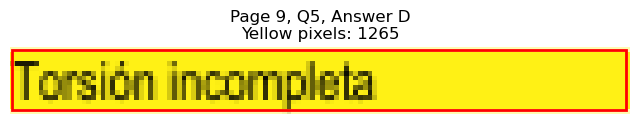

Page 9, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=371.7, y1=405.0
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 319
Page 9, Q5, E: Yellow percentage: 0.0%


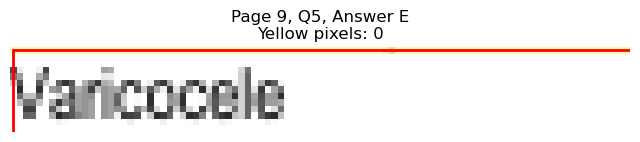


Page 9, Q5 - Selected Answer: D (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=242.3, y1=455.5
Page 9, Q6, A: Yellow pixels: 213
Page 9, Q6, A: Total non-white pixels: 1065
Page 9, Q6, A: Yellow percentage: 20.0%


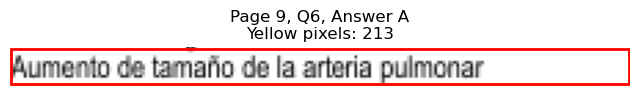

Page 9, Q6 - B: Detected box: x0=164.1, y0=455.5, x1=215.3, y1=468.1
Page 9, Q6, B: Yellow pixels: 1102
Page 9, Q6, B: Total non-white pixels: 1428
Page 9, Q6, B: Yellow percentage: 77.2%


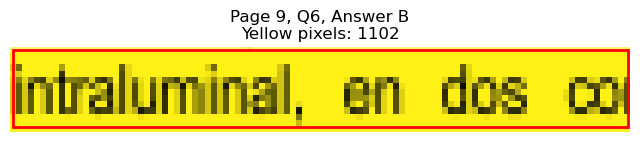

Page 9, Q6 - C: Detected box: x0=175.1, y0=480.8, x1=225.3, y1=493.4
Page 9, Q6, C: Yellow pixels: 101
Page 9, Q6, C: Total non-white pixels: 592
Page 9, Q6, C: Yellow percentage: 17.1%


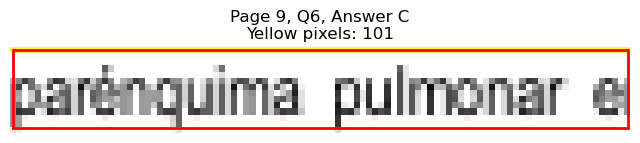

Page 9, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=414.3, y1=455.5
Page 9, Q6, D: Yellow pixels: 0
Page 9, Q6, D: Total non-white pixels: 463
Page 9, Q6, D: Yellow percentage: 0.0%


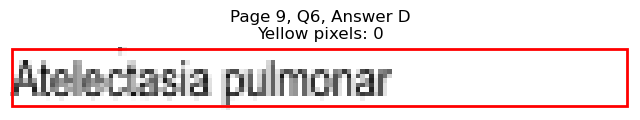

Page 9, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=541.0, y1=468.1
Page 9, Q6, E: Yellow pixels: 0
Page 9, Q6, E: Total non-white pixels: 1004
Page 9, Q6, E: Yellow percentage: 0.0%


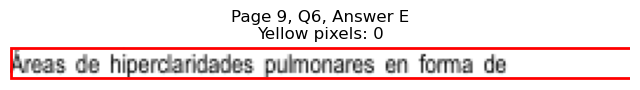


Page 9, Q6 - Selected Answer: B (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=569.1, x1=173.7, y1=581.8
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 561
Page 9, Q7, A: Yellow percentage: 0.0%


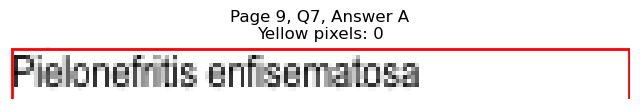

Page 9, Q7 - B: Detected box: x0=68.3, y0=581.7, x1=145.1, y1=594.4
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 392
Page 9, Q7, B: Yellow percentage: 0.0%


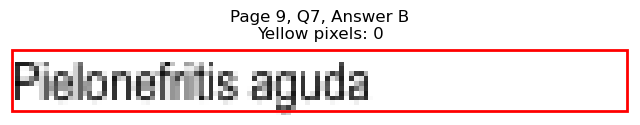

Page 9, Q7 - C: Detected box: x0=68.8, y0=594.3, x1=149.5, y1=607.0
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 407
Page 9, Q7, C: Yellow percentage: 0.0%


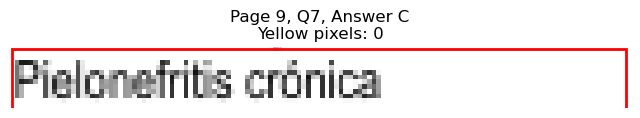

Page 9, Q7 - D: Detected box: x0=327.5, y0=569.1, x1=403.7, y1=581.8
Page 9, Q7, D: Yellow pixels: 0
Page 9, Q7, D: Total non-white pixels: 520
Page 9, Q7, D: Yellow percentage: 0.0%


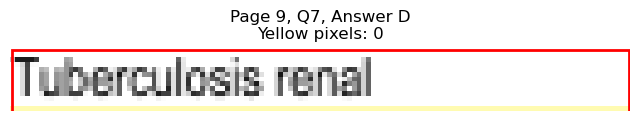

Page 9, Q7 - E: Detected box: x0=327.0, y0=581.7, x1=460.4, y1=594.4
Page 9, Q7, E: Yellow pixels: 1629
Page 9, Q7, E: Total non-white pixels: 2576
Page 9, Q7, E: Yellow percentage: 63.2%


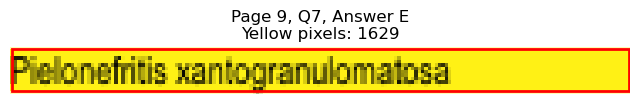


Page 9, Q7 - Selected Answer: E (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=56.6, y0=644.9, x1=65.2, y1=657.5
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 69
Page 9, Q8, A: Yellow percentage: 0.0%


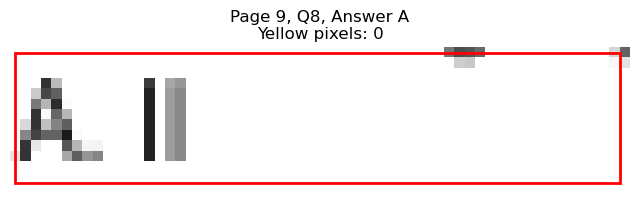

Page 9, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=79.3, y1=670.1
Page 9, Q8, B: Yellow pixels: 0
Page 9, Q8, B: Total non-white pixels: 36
Page 9, Q8, B: Yellow percentage: 0.0%


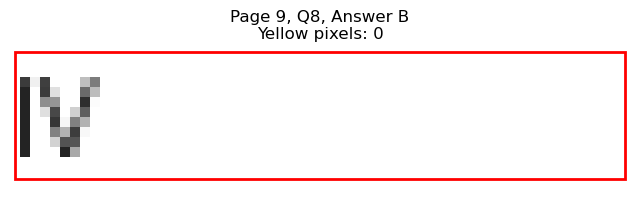

Page 9, Q8 - C: Detected box: x0=56.6, y0=670.1, x1=65.6, y1=682.7
Page 9, Q8, C: Yellow pixels: 0
Page 9, Q8, C: Total non-white pixels: 65
Page 9, Q8, C: Yellow percentage: 0.0%


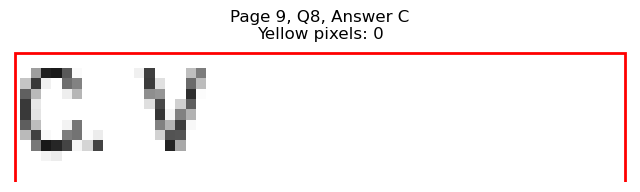

Page 9, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=337.6, y1=657.5
Page 9, Q8, D: Yellow pixels: 753
Page 9, Q8, D: Total non-white pixels: 854
Page 9, Q8, D: Yellow percentage: 88.2%


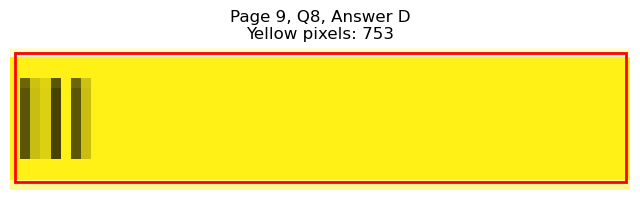

Page 9, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=338.1, y1=670.1
Page 9, Q8, E: Yellow pixels: 62
Page 9, Q8, E: Total non-white pixels: 104
Page 9, Q8, E: Yellow percentage: 59.6%


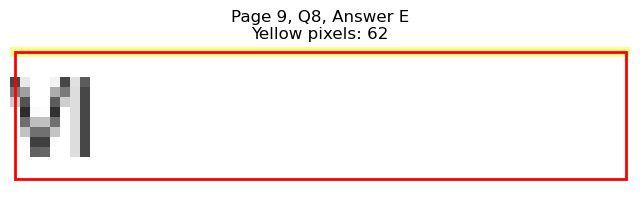


Page 9, Q8 - Selected Answer: D (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=56.6, y0=644.9, x1=65.2, y1=657.5
Page 9, Q9, A: Yellow pixels: 0
Page 9, Q9, A: Total non-white pixels: 69
Page 9, Q9, A: Yellow percentage: 0.0%


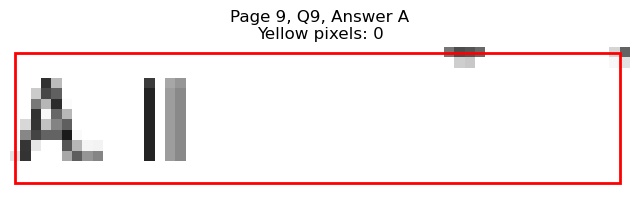

Page 9, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=78.4, y1=745.8
Page 9, Q9, B: Yellow pixels: 0
Page 9, Q9, B: Total non-white pixels: 32
Page 9, Q9, B: Yellow percentage: 0.0%


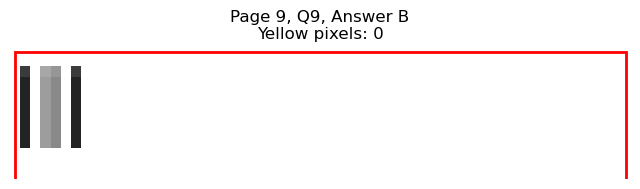

Page 9, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=79.8, y1=758.4
Page 9, Q9, C: Yellow pixels: 0
Page 9, Q9, C: Total non-white pixels: 44
Page 9, Q9, C: Yellow percentage: 0.0%


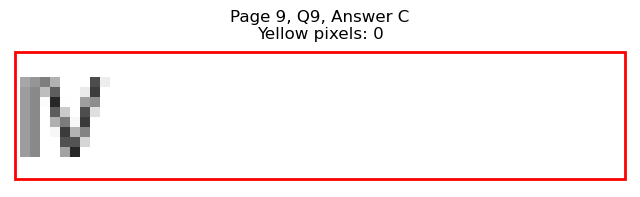

Page 9, Q9 - D: Detected box: x0=315.4, y0=720.6, x1=324.4, y1=733.2
Page 9, Q9, D: Yellow pixels: 734
Page 9, Q9, D: Total non-white pixels: 840
Page 9, Q9, D: Yellow percentage: 87.4%


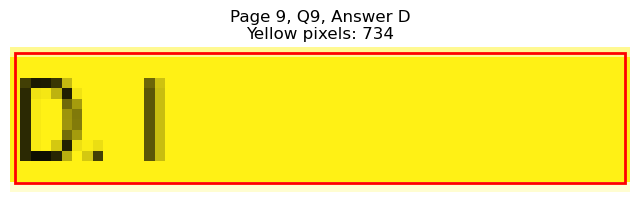

Page 9, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=337.6, y1=745.8
Page 9, Q9, E: Yellow pixels: 0
Page 9, Q9, E: Total non-white pixels: 122
Page 9, Q9, E: Yellow percentage: 0.0%


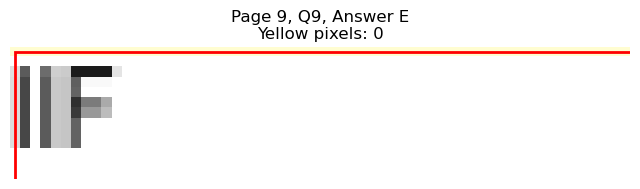


Page 9, Q9 - Selected Answer: D (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=145.0, y1=102.1
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 401
Page 10, Q1, A: Yellow percentage: 0.0%


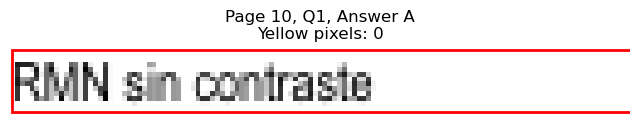

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=146.5, y1=114.7
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 493
Page 10, Q1, B: Yellow percentage: 0.0%


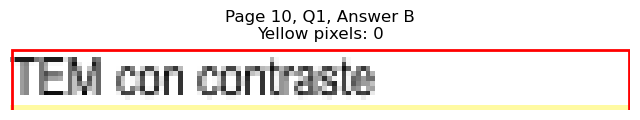

Page 10, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=144.0, y1=127.3
Page 10, Q1, C: Yellow pixels: 1244
Page 10, Q1, C: Total non-white pixels: 1778
Page 10, Q1, C: Yellow percentage: 70.0%


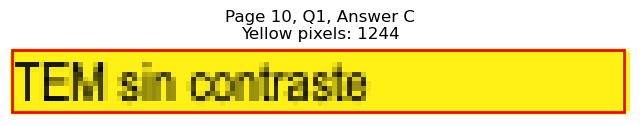

Page 10, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=419.3, y1=102.1
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 479
Page 10, Q1, D: Yellow percentage: 0.0%


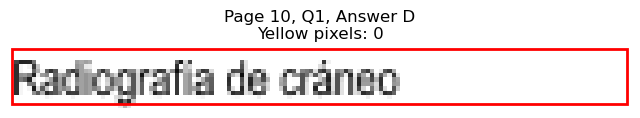

Page 10, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=406.7, y1=114.7
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 405
Page 10, Q1, E: Yellow percentage: 0.0%


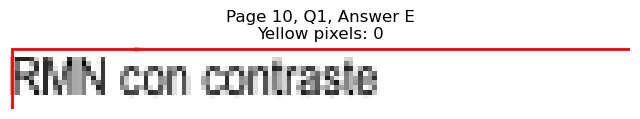


Page 10, Q1 - Selected Answer: C (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=179.2, y1=190.4
Page 10, Q2, A: Yellow pixels: 162
Page 10, Q2, A: Total non-white pixels: 727
Page 10, Q2, A: Yellow percentage: 22.3%


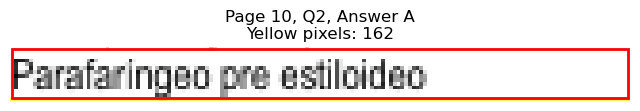

Page 10, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=138.0, y1=203.0
Page 10, Q2, B: Yellow pixels: 1315
Page 10, Q2, B: Total non-white pixels: 1573
Page 10, Q2, B: Yellow percentage: 83.6%


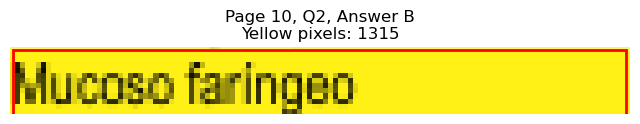

Page 10, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=182.7, y1=215.6
Page 10, Q2, C: Yellow pixels: 161
Page 10, Q2, C: Total non-white pixels: 785
Page 10, Q2, C: Yellow percentage: 20.5%


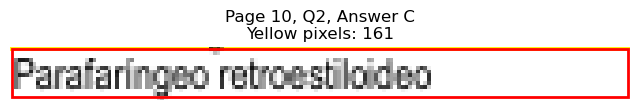

Page 10, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=369.2, y1=190.4
Page 10, Q2, D: Yellow pixels: 0
Page 10, Q2, D: Total non-white pixels: 211
Page 10, Q2, D: Yellow percentage: 0.0%


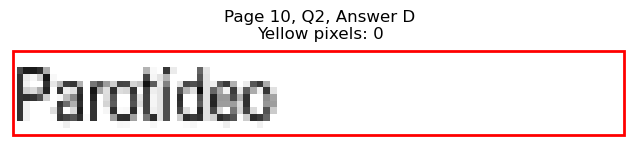

Page 10, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=373.7, y1=203.0
Page 10, Q2, E: Yellow pixels: 0
Page 10, Q2, E: Total non-white pixels: 244
Page 10, Q2, E: Yellow percentage: 0.0%


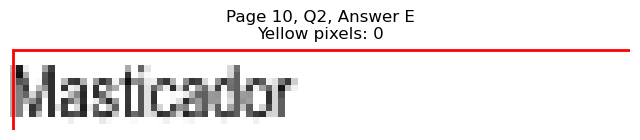


Page 10, Q2 - Selected Answer: B (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=122.4, y1=278.7
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 275
Page 10, Q3, A: Yellow percentage: 0.0%


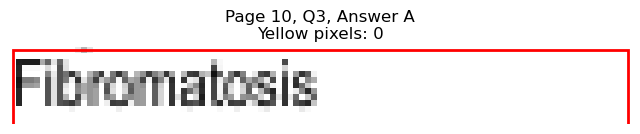

Page 10, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=139.5, y1=291.5
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 378
Page 10, Q3, B: Yellow percentage: 0.0%


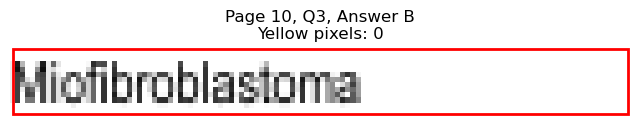

Page 10, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=119.4, y1=304.1
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 256
Page 10, Q3, C: Yellow percentage: 0.0%


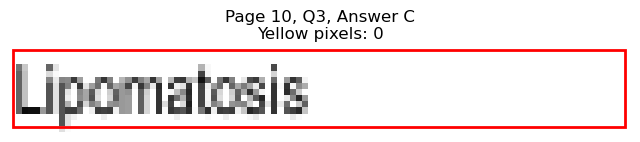

Page 10, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=390.8, y1=278.7
Page 10, Q3, D: Yellow pixels: 0
Page 10, Q3, D: Total non-white pixels: 335
Page 10, Q3, D: Yellow percentage: 0.0%


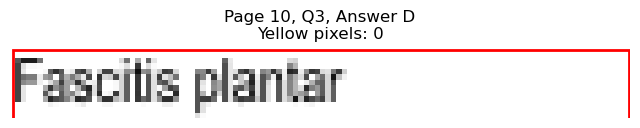

Page 10, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=409.9, y1=291.5
Page 10, Q3, E: Yellow pixels: 1435
Page 10, Q3, E: Total non-white pixels: 1862
Page 10, Q3, E: Yellow percentage: 77.1%


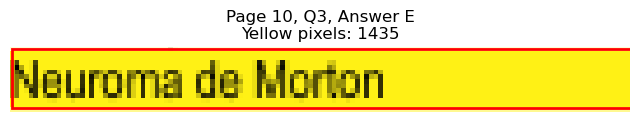


Page 10, Q3 - Selected Answer: E (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=152.5, y1=341.9
Page 10, Q4, A: Yellow pixels: 1430
Page 10, Q4, A: Total non-white pixels: 1755
Page 10, Q4, A: Yellow percentage: 81.5%


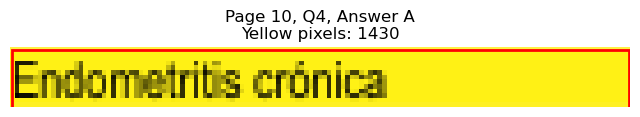

Page 10, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=124.5, y1=354.6
Page 10, Q4, B: Yellow pixels: 107
Page 10, Q4, B: Total non-white pixels: 418
Page 10, Q4, B: Yellow percentage: 25.6%


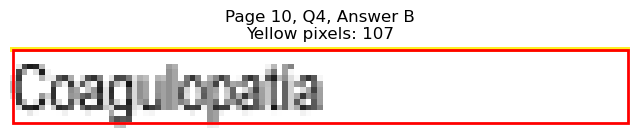

Page 10, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=143.5, y1=367.2
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 384
Page 10, Q4, C: Yellow percentage: 0.0%


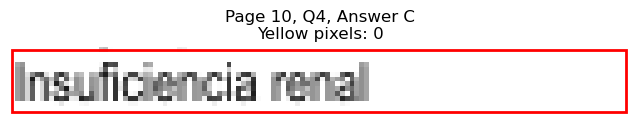

Page 10, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=439.4, y1=341.9
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 546
Page 10, Q4, D: Yellow percentage: 0.0%


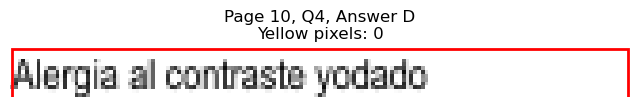

Page 10, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=436.4, y1=354.6
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 545
Page 10, Q4, E: Yellow percentage: 0.0%


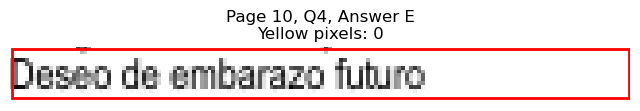


Page 10, Q4 - Selected Answer: A (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=404.9, x1=80.9, y1=417.6
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 55
Page 10, Q5, A: Yellow percentage: 0.0%


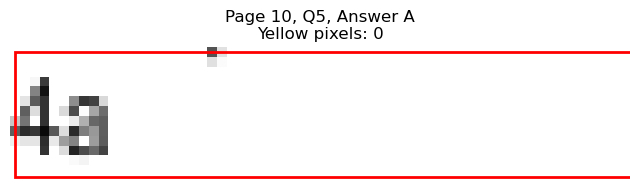

Page 10, Q5 - B: Detected box: x0=68.3, y0=417.6, x1=80.9, y1=430.3
Page 10, Q5, B: Yellow pixels: 0
Page 10, Q5, B: Total non-white pixels: 54
Page 10, Q5, B: Yellow percentage: 0.0%


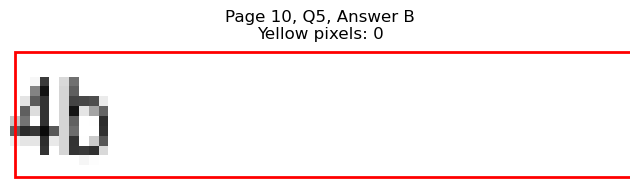

Page 10, Q5 - C: Detected box: x0=56.6, y0=430.2, x1=65.6, y1=442.9
Page 10, Q5, C: Yellow pixels: 0
Page 10, Q5, C: Total non-white pixels: 63
Page 10, Q5, C: Yellow percentage: 0.0%


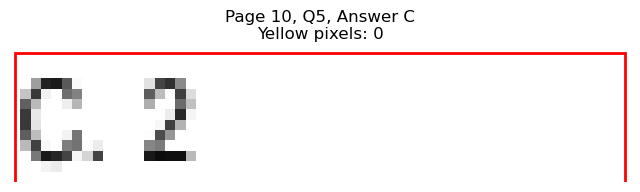

Page 10, Q5 - D: Detected box: x0=315.4, y0=404.9, x1=324.4, y1=417.6
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 79
Page 10, Q5, D: Yellow percentage: 0.0%


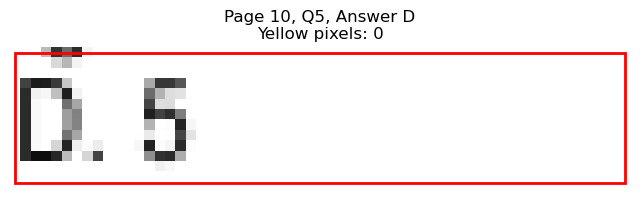

Page 10, Q5 - E: Detected box: x0=315.4, y0=417.6, x1=323.9, y1=430.3
Page 10, Q5, E: Yellow pixels: 660
Page 10, Q5, E: Total non-white pixels: 826
Page 10, Q5, E: Yellow percentage: 79.9%


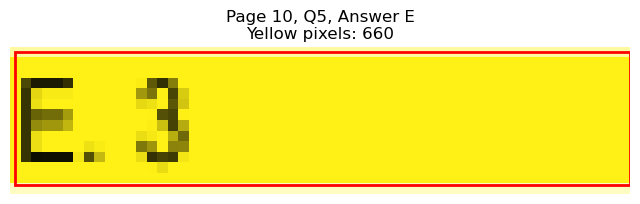


Page 10, Q5 - Selected Answer: E (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=121.0, y1=480.7
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 242
Page 10, Q6, A: Yellow percentage: 0.0%


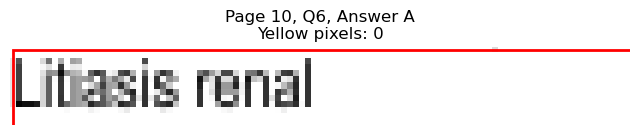

Page 10, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=139.6, y1=493.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 351
Page 10, Q6, B: Yellow percentage: 0.0%


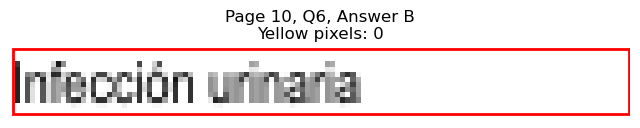

Page 10, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=164.1, y1=506.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 461
Page 10, Q6, C: Yellow percentage: 0.0%


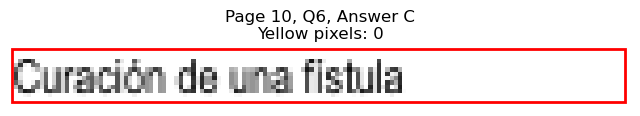

Page 10, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=374.7, y1=480.7
Page 10, Q6, D: Yellow pixels: 1095
Page 10, Q6, D: Total non-white pixels: 1274
Page 10, Q6, D: Yellow percentage: 85.9%


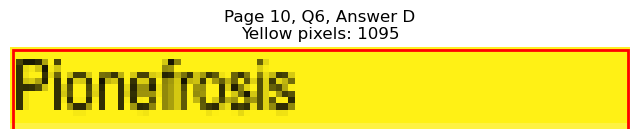

Page 10, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=481.5, y1=493.4
Page 10, Q6, E: Yellow pixels: 205
Page 10, Q6, E: Total non-white pixels: 967
Page 10, Q6, E: Yellow percentage: 21.2%


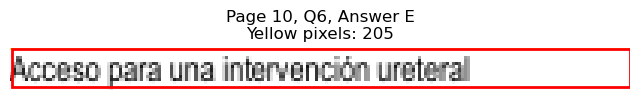


Page 10, Q6 - Selected Answer: D (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=175.1, y1=556.4
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 536
Page 10, Q7, A: Yellow percentage: 0.0%


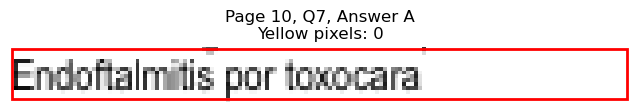

Page 10, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=188.2, y1=569.2
Page 10, Q7, B: Yellow pixels: 171
Page 10, Q7, B: Total non-white pixels: 771
Page 10, Q7, B: Yellow percentage: 22.2%


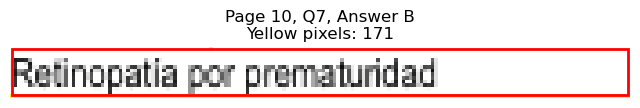

Page 10, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=133.9, y1=581.8
Page 10, Q7, C: Yellow pixels: 1229
Page 10, Q7, C: Total non-white pixels: 1508
Page 10, Q7, C: Yellow percentage: 81.5%


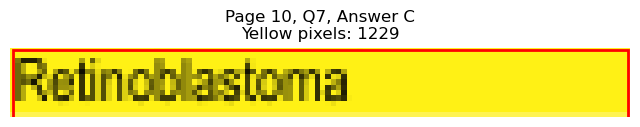

Page 10, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=451.4, y1=556.4
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 663
Page 10, Q7, D: Yellow percentage: 0.0%


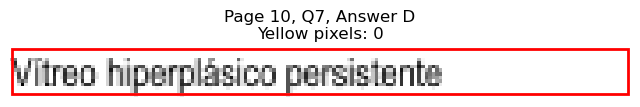

Page 10, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=417.3, y1=569.2
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 464
Page 10, Q7, E: Yellow percentage: 0.0%


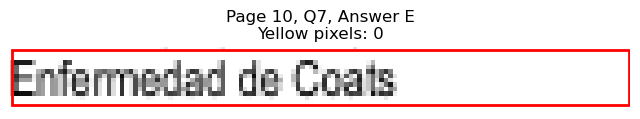


Page 10, Q7 - Selected Answer: C (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=189.6, y1=619.6
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 582
Page 10, Q8, A: Yellow percentage: 0.0%


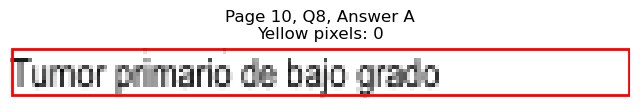

Page 10, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=113.9, y1=632.3
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 272
Page 10, Q8, B: Yellow percentage: 0.0%


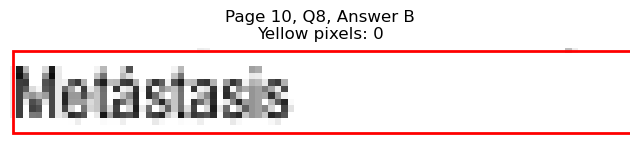

Page 10, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=96.9, y1=644.9
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 143
Page 10, Q8, C: Yellow percentage: 0.0%


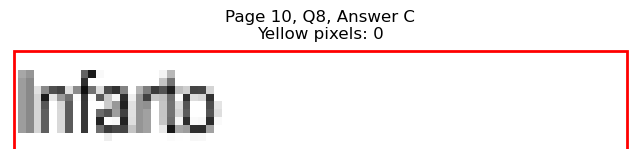

Page 10, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=512.1, y1=619.6
Page 10, Q8, D: Yellow pixels: 2054
Page 10, Q8, D: Total non-white pixels: 2995
Page 10, Q8, D: Yellow percentage: 68.6%


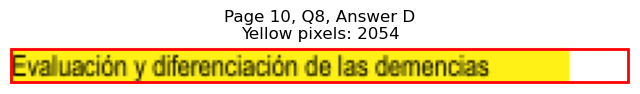

Page 10, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=385.3, y1=632.3
Page 10, Q8, E: Yellow pixels: 108
Page 10, Q8, E: Total non-white pixels: 400
Page 10, Q8, E: Yellow percentage: 27.0%


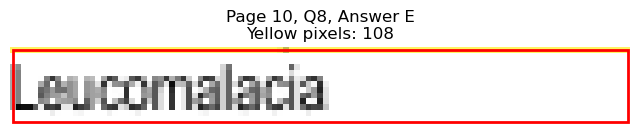


Page 10, Q8 - Selected Answer: D (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=133.5, y1=708.0
Page 10, Q9, A: Yellow pixels: 116
Page 10, Q9, A: Total non-white pixels: 583
Page 10, Q9, A: Yellow percentage: 19.9%


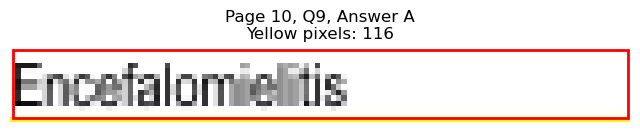

Page 10, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=153.0, y1=720.6
Page 10, Q9, B: Yellow pixels: 1404
Page 10, Q9, B: Total non-white pixels: 1904
Page 10, Q9, B: Yellow percentage: 73.7%


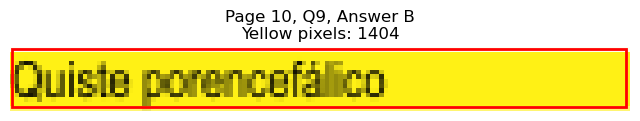

Page 10, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=138.5, y1=733.2
Page 10, Q9, C: Yellow pixels: 121
Page 10, Q9, C: Total non-white pixels: 459
Page 10, Q9, C: Yellow percentage: 26.4%


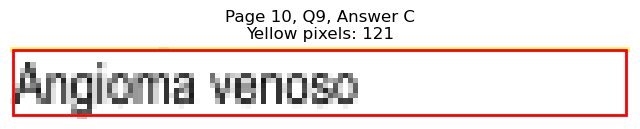

Page 10, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=412.3, y1=708.0
Page 10, Q9, D: Yellow pixels: 0
Page 10, Q9, D: Total non-white pixels: 456
Page 10, Q9, D: Yellow percentage: 0.0%


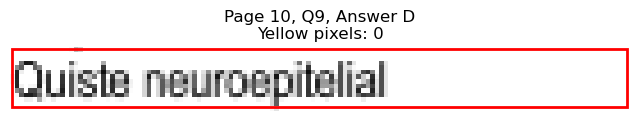

Page 10, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=370.2, y1=720.6
Page 10, Q9, E: Yellow pixels: 0
Page 10, Q9, E: Total non-white pixels: 268
Page 10, Q9, E: Yellow percentage: 0.0%


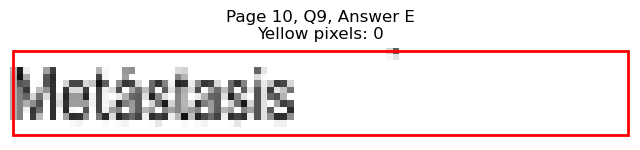


Page 10, Q9 - Selected Answer: B (based on yellow pixel count)





Page 11: Found 8 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=135.0, y1=127.3
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 367
Page 11, Q1, A: Yellow percentage: 0.0%


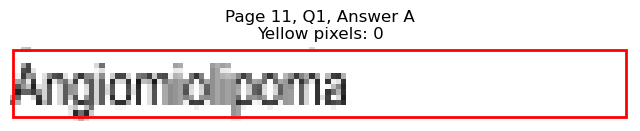

Page 11, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=215.3, y1=139.9
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 733
Page 11, Q1, B: Yellow percentage: 0.0%


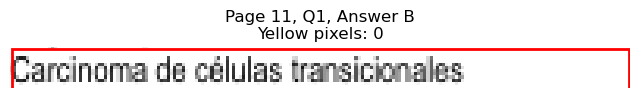

Page 11, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=103.3, y1=152.6
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 169
Page 11, Q1, C: Yellow percentage: 0.0%


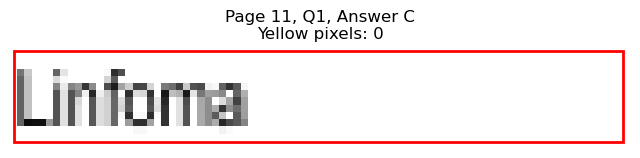

Page 11, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=448.9, y1=127.3
Page 11, Q1, D: Yellow pixels: 1623
Page 11, Q1, D: Total non-white pixels: 2408
Page 11, Q1, D: Yellow percentage: 67.4%


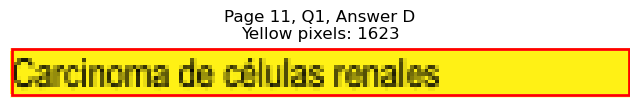

Page 11, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=460.0, y1=139.9
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 785
Page 11, Q1, E: Yellow percentage: 0.0%


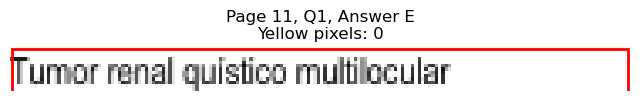


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=146.5, y1=190.4
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 379
Page 11, Q2, A: Yellow percentage: 0.0%


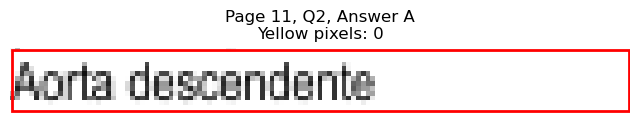

Page 11, Q2 - B: Detected box: x0=242.4, y0=190.3, x1=282.2, y1=203.0
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 268
Page 11, Q2, B: Yellow percentage: 0.0%


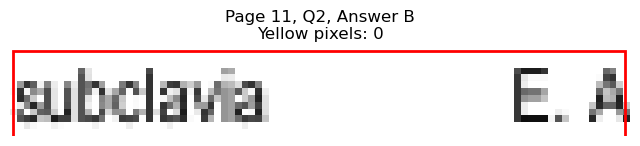

Page 11, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=122.9, y1=228.3
Page 11, Q2, C: Yellow pixels: 1052
Page 11, Q2, C: Total non-white pixels: 1470
Page 11, Q2, C: Yellow percentage: 71.6%


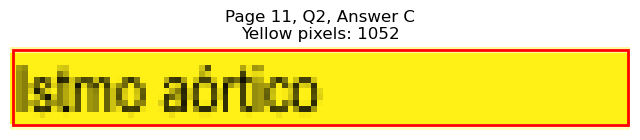

Page 11, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=467.0, y1=190.4
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 679
Page 11, Q2, D: Yellow percentage: 0.0%


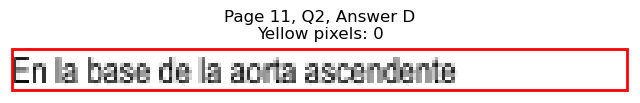

Page 11, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=400.3, y1=203.0
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 368
Page 11, Q2, E: Yellow percentage: 0.0%


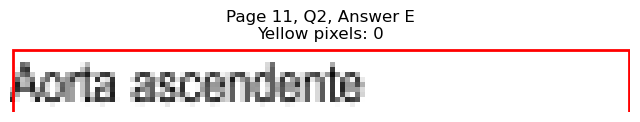


Page 11, Q2 - Selected Answer: C (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=291.4, x1=124.5, y1=304.1
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 278
Page 11, Q3, A: Yellow percentage: 0.0%


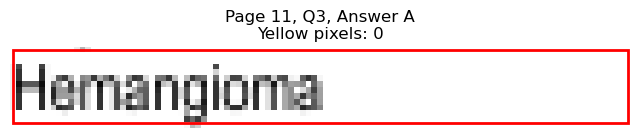

Page 11, Q3 - B: Detected box: x0=68.3, y0=304.0, x1=205.7, y1=316.7
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 840
Page 11, Q3, B: Yellow percentage: 0.0%


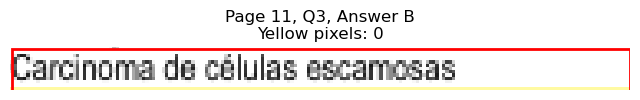

Page 11, Q3 - C: Detected box: x0=68.8, y0=316.6, x1=144.5, y1=329.3
Page 11, Q3, C: Yellow pixels: 1194
Page 11, Q3, C: Total non-white pixels: 1778
Page 11, Q3, C: Yellow percentage: 67.2%


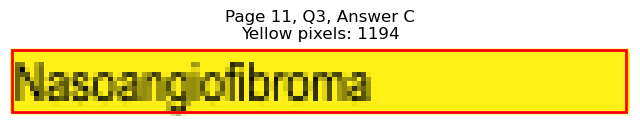

Page 11, Q3 - D: Detected box: x0=327.5, y0=291.4, x1=409.7, y1=304.1
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 419
Page 11, Q3, D: Yellow percentage: 0.0%


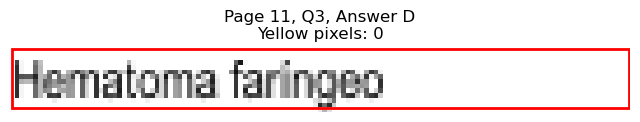

Page 11, Q3 - E: Detected box: x0=327.0, y0=304.0, x1=361.6, y1=316.7
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 162
Page 11, Q3, E: Yellow percentage: 0.0%


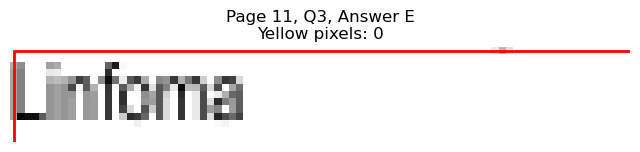


Page 11, Q3 - Selected Answer: C (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=367.1, x1=85.8, y1=379.8
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 90
Page 11, Q4, A: Yellow percentage: 0.0%


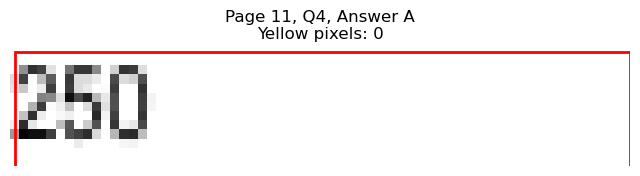

Page 11, Q4 - B: Detected box: x0=68.3, y0=379.7, x1=85.8, y1=392.4
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 91
Page 11, Q4, B: Yellow percentage: 0.0%


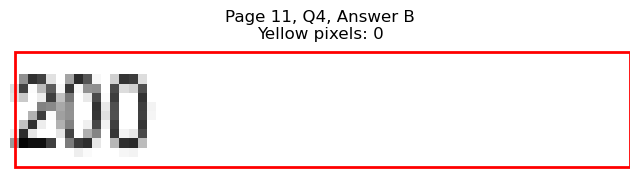

Page 11, Q4 - C: Detected box: x0=68.8, y0=392.3, x1=86.3, y1=405.0
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 82
Page 11, Q4, C: Yellow percentage: 0.0%


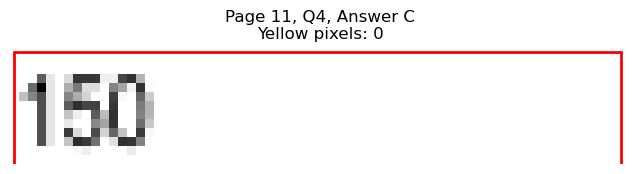

Page 11, Q4 - D: Detected box: x0=327.5, y0=367.1, x1=345.1, y1=379.8
Page 11, Q4, D: Yellow pixels: 838
Page 11, Q4, D: Total non-white pixels: 897
Page 11, Q4, D: Yellow percentage: 93.4%


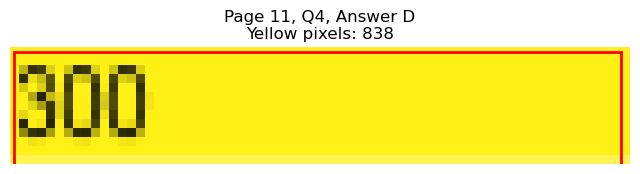

Page 11, Q4 - E: Detected box: x0=327.0, y0=379.7, x1=344.6, y1=392.4
Page 11, Q4, E: Yellow pixels: 68
Page 11, Q4, E: Total non-white pixels: 152
Page 11, Q4, E: Yellow percentage: 44.7%


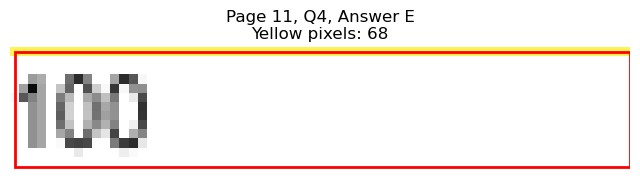


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=162.6, y1=455.5
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 491
Page 11, Q5, A: Yellow percentage: 0.0%


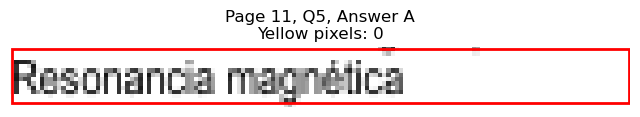

Page 11, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=88.3, y1=468.1
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 94
Page 11, Q5, B: Yellow percentage: 0.0%


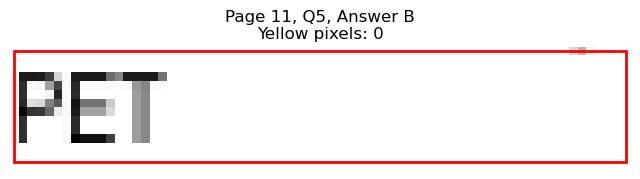

Page 11, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=126.5, y1=480.7
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 308
Page 11, Q5, C: Yellow percentage: 0.0%


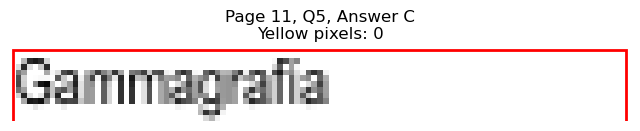

Page 11, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=436.4, y1=455.5
Page 11, Q5, D: Yellow pixels: 1675
Page 11, Q5, D: Total non-white pixels: 2240
Page 11, Q5, D: Yellow percentage: 74.8%


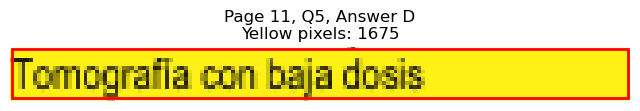

Page 11, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=391.3, y1=468.1
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 340
Page 11, Q5, E: Yellow percentage: 0.0%


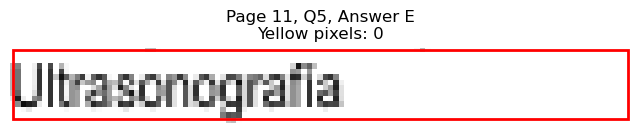


Page 11, Q5 - Selected Answer: D (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=152.5, y1=543.8
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 468
Page 11, Q6, A: Yellow percentage: 0.0%


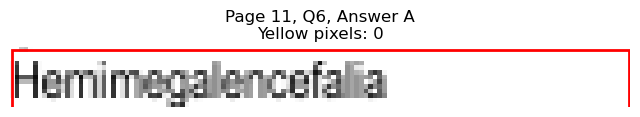

Page 11, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=112.9, y1=556.4
Page 11, Q6, B: Yellow pixels: 0
Page 11, Q6, B: Total non-white pixels: 241
Page 11, Q6, B: Yellow percentage: 0.0%


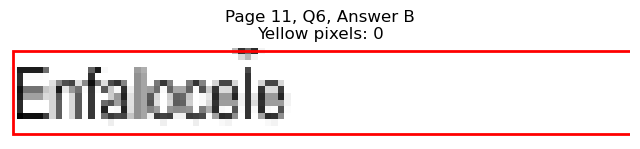

Page 11, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=134.5, y1=569.2
Page 11, Q6, C: Yellow pixels: 1225
Page 11, Q6, C: Total non-white pixels: 1638
Page 11, Q6, C: Yellow percentage: 74.8%


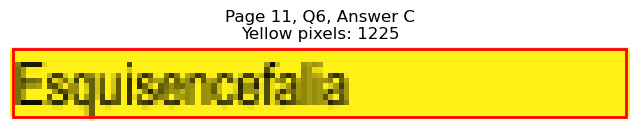

Page 11, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=377.7, y1=543.8
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 258
Page 11, Q6, D: Yellow percentage: 0.0%


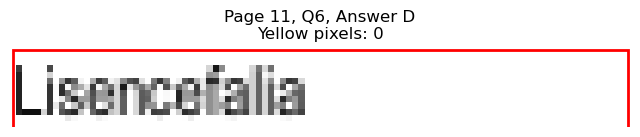

Page 11, Q6 - E: Detected box: x0=327.0, y0=543.8, x1=369.7, y1=556.4
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 248
Page 11, Q6, E: Yellow percentage: 0.0%


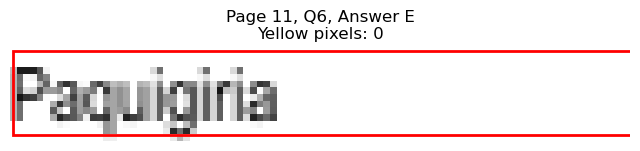


Page 11, Q6 - Selected Answer: C (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=123.0, y1=607.0
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 282
Page 11, Q7, A: Yellow percentage: 0.0%


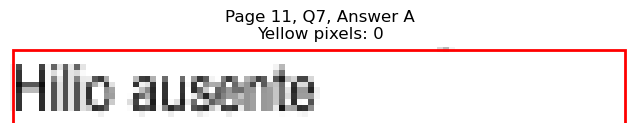

Page 11, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=136.9, y1=619.6
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 337
Page 11, Q7, B: Yellow percentage: 0.0%


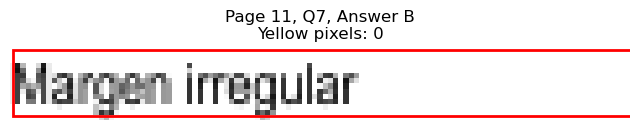

Page 11, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=190.6, y1=632.3
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 627
Page 11, Q7, C: Yellow percentage: 0.0%


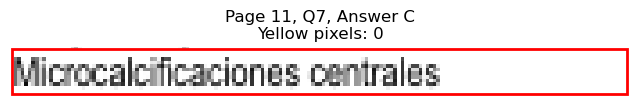

Page 11, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=450.9, y1=607.0
Page 11, Q7, D: Yellow pixels: 0
Page 11, Q7, D: Total non-white pixels: 826
Page 11, Q7, D: Yellow percentage: 0.0%


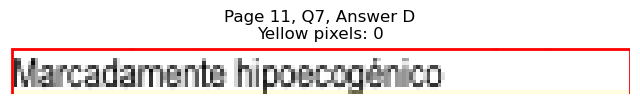

Page 11, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=389.7, y1=619.6
Page 11, Q7, E: Yellow pixels: 1235
Page 11, Q7, E: Total non-white pixels: 1582
Page 11, Q7, E: Yellow percentage: 78.1%


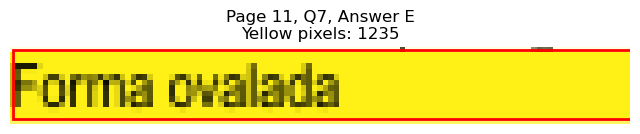


Page 11, Q7 - Selected Answer: E (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=123.5, y1=695.3
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 257
Page 11, Q8, A: Yellow percentage: 0.0%


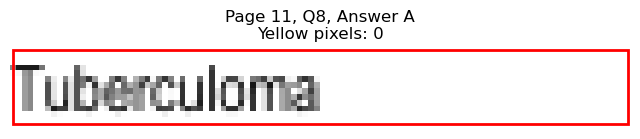

Page 11, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=141.0, y1=708.0
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 376
Page 11, Q8, B: Yellow percentage: 0.0%


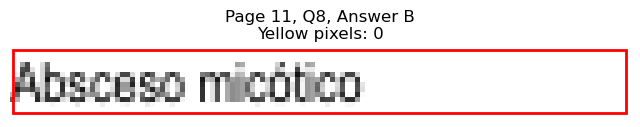

Page 11, Q8 - C: Detected box: x0=68.8, y0=139.9, x1=103.3, y1=152.6
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 169
Page 11, Q8, C: Yellow percentage: 0.0%


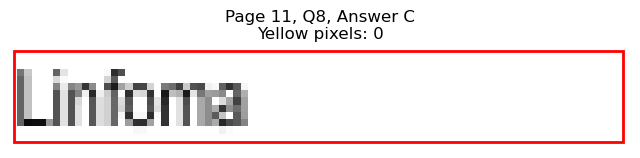

Page 11, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=372.7, y1=695.3
Page 11, Q8, D: Yellow pixels: 952
Page 11, Q8, D: Total non-white pixels: 1344
Page 11, Q8, D: Yellow percentage: 70.8%


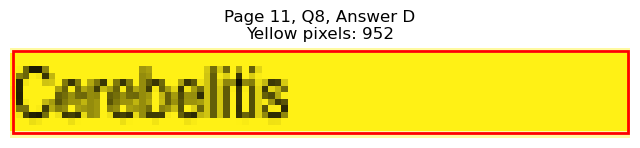

Page 11, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=398.8, y1=708.0
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 499
Page 11, Q8, E: Yellow percentage: 0.0%


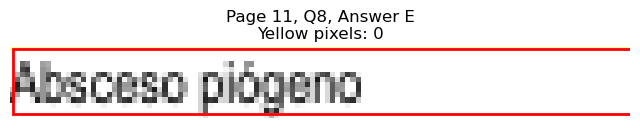


Page 11, Q8 - Selected Answer: D (based on yellow pixel count)





Page 12: Found 1 questions
Page 12, Q1 - A: Detected box: x0=56.6, y0=102.0, x1=65.2, y1=114.7
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 68
Page 12, Q1, A: Yellow percentage: 0.0%


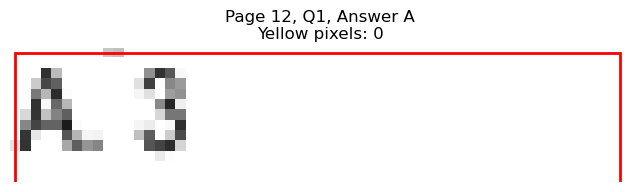

Page 12, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=80.9, y1=127.3
Page 12, Q1, B: Yellow pixels: 0
Page 12, Q1, B: Total non-white pixels: 52
Page 12, Q1, B: Yellow percentage: 0.0%


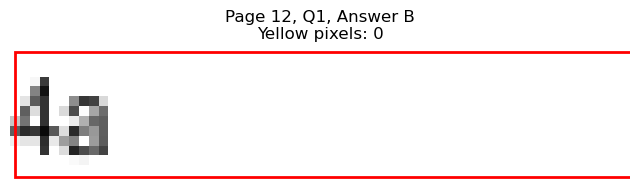

Page 12, Q1 - C: Detected box: x0=56.6, y0=127.2, x1=65.6, y1=139.9
Page 12, Q1, C: Yellow pixels: 0
Page 12, Q1, C: Total non-white pixels: 70
Page 12, Q1, C: Yellow percentage: 0.0%


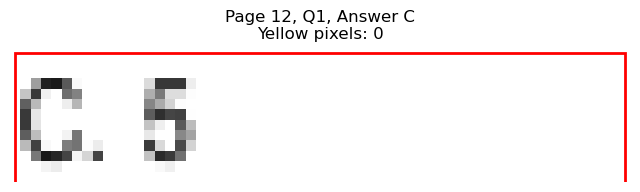

Page 12, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=340.1, y1=114.7
Page 12, Q1, D: Yellow pixels: 0
Page 12, Q1, D: Total non-white pixels: 118
Page 12, Q1, D: Yellow percentage: 0.0%


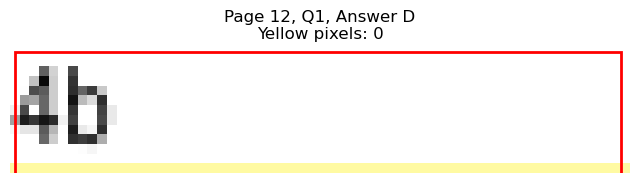

Page 12, Q1 - E: Detected box: x0=315.4, y0=114.6, x1=323.9, y1=127.3
Page 12, Q1, E: Yellow pixels: 659
Page 12, Q1, E: Total non-white pixels: 826
Page 12, Q1, E: Yellow percentage: 79.8%


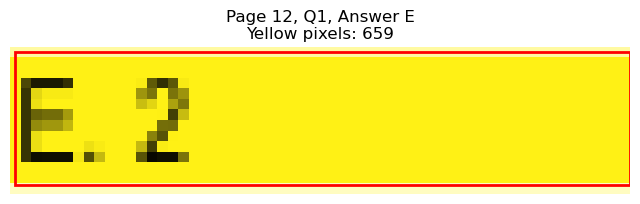


Page 12, Q1 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,En relación con la ecogenicidad de los nódulos...
1,¿Cuál es la neoplasia auricular primaria más f...
2,"Varón de 80 años, ingresa a emergencia por hip..."
3,En el estudio de Histerosalpingografía. ¿Cuál ...
4,"Mujer de 60 años, sufre caída con la mano abie..."
...,...
95,"En mieloma múltiple, el número de lesiones lít..."
96,"Niño de 3 años, presenta crisis epilépticas, c..."
97,En la evaluación ecográfica del ganglio cervic...
98,"Varón con antecedente de sinusitis no tratada,..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Isoecogénico,Hiperecogénico,Hipoecogénico,Heterogéneo,Anecogénico
1,Sarcoma,Linfoma,Teratoma,Lipoma,Mixoma
2,Aneurisma disecante,Ruptura de un aneurisma aórtico,Pseudoaneurisma,Aneurisma inflamatorio,Trombosis arterial aórtica
3,Abortos a repetición,Reconstrucción tubaria,Bloqueo tubario,Miomatosis uterina,Dispositivo intrauterino
4,Colles,Smith,Galeazzi,Piedmont,Barton y Hutchinson
...,...,...,...,...,...
95,Resonancia magnética,PET,Gammagrafía,Tomografía con baja dosis,Ultrasonografía
96,Hemimegalencefalia,Enfalocele,Esquisencefalia,Lisencefalia,Paquigiria
97,Hilio ausente,Margen irregular,Microcalcificaciones centrales,Marcadamente hipoecogénico,Forma ovalada
98,Tuberculoma,Absceso micótico,Linfoma,Cerebelitis,Absceso piógeno


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,En relación con la ecogenicidad de los nódulos...,Isoecogénico,Hiperecogénico,Hipoecogénico,Heterogéneo,Anecogénico,C
1,¿Cuál es la neoplasia auricular primaria más f...,Sarcoma,Linfoma,Teratoma,Lipoma,Mixoma,E
2,"Varón de 80 años, ingresa a emergencia por hip...",Aneurisma disecante,Ruptura de un aneurisma aórtico,Pseudoaneurisma,Aneurisma inflamatorio,Trombosis arterial aórtica,B
3,En el estudio de Histerosalpingografía. ¿Cuál ...,Abortos a repetición,Reconstrucción tubaria,Bloqueo tubario,Miomatosis uterina,Dispositivo intrauterino,E
4,"Mujer de 60 años, sufre caída con la mano abie...",Colles,Smith,Galeazzi,Piedmont,Barton y Hutchinson,A
...,...,...,...,...,...,...,...
95,"En mieloma múltiple, el número de lesiones lít...",Resonancia magnética,PET,Gammagrafía,Tomografía con baja dosis,Ultrasonografía,D
96,"Niño de 3 años, presenta crisis epilépticas, c...",Hemimegalencefalia,Enfalocele,Esquisencefalia,Lisencefalia,Paquigiria,C
97,En la evaluación ecográfica del ganglio cervic...,Hilio ausente,Margen irregular,Microcalcificaciones centrales,Marcadamente hipoecogénico,Forma ovalada,E
98,"Varón con antecedente de sinusitis no tratada,...",Tuberculoma,Absceso micótico,Linfoma,Cerebelitis,Absceso piógeno,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Radiología.csv
